# Pronóstico de Producción, Demanda e Importaciones de Maíz Duro Amarillo en Ecuador

**Tesis de Maestría en Big Data** — notebook único, reproducible desde los datos crudos.

## Qué hace este notebook

Procesa desde los archivos originales las fuentes de la Etapa 1 (microdatos ESPAC `.sav` de
2014-2015, `.csv` de 2016-2017, Tabulados oficiales 2018-2025 y clima `.nc` de Copernicus ERA5),
obtiene el balance oferta-demanda del USDA-PSD, y lee las importaciones del BCE y el precio
internacional (FMI vía FRED). Con eso desarrolla las tres etapas:

| Etapa | Pregunta | Método |
|---|---|---|
| 1. Producción | ¿Cuánto maíz duro seco producirá cada provincia? | XGBoost con clima por región, validado con LOYO y Group K-Fold por provincia |
| 2. Demanda | ¿Cuánto consume el país? | Comparación de 6 métodos de series de tiempo sobre 3 fuentes |
| 3. Importaciones | ¿Cuánto necesita importar? | 6 variantes comparadas con validación Leave-One-Out |

## Cómo ejecutarlo

**Opción A — Google Colab:** subir la carpeta `datos/` de este repositorio a
`Mi unidad/Colab Notebooks/Tesis/` en Google Drive y usar *Entorno de ejecución → Ejecutar todas*.

**Opción B — local:** desde la raíz del repositorio,

```bash
pip install -r requirements.txt
jupyter notebook TESIS_COMPLETA.ipynb
```

El notebook detecta solo en qué entorno está. Fuera de Colab lee los datos de la carpeta
`datos/` (o de la ruta indicada en la variable de entorno `TESIS_DATOS`).

```
datos/
├── ESPAC/        ct_nac2014.sav, ctnac_2015.sav, ctnac2016.csv, ctnac2017.csv,
│                 Tabulados ESPAC 2018.xlsx ... Tabulados_excel_2025.xlsx
├── Copernicus/   3 archivos .nc (temperatura/precipitación, humedad del suelo, radiación)
├── BCE/          importaciones_maiz.xlsx
├── FRED/         PMAIZMTUSDA.xlsx
├── FAOSTAT/      FAO 2014-2023.xls
├── USDA/         usda_psd_maiz_ecuador.csv   (copia local del balance USDA-PSD)
└── Mapa/         provincias_ecuador.geojson
```

**API del USDA:** si existe la variable de entorno `USDA_API_KEY` (o el secreto `USDA_API_KEY`
en Colab), el notebook consulta la API en vivo y actualiza la copia local; si no, usa
`datos/USDA/usda_psd_maiz_ecuador.csv`. La clave nunca se escribe en el notebook.

**Tiempo de ejecución:** unos 20-25 minutos (seis búsquedas de 192 combinaciones de
hiperparámetros en la Etapa 1).

# Parte 0 — Configuración inicial

## 0.1 — Instalar las librerías que Colab no trae por defecto

En Colab se instalan aquí las librerías adicionales. En una instalación local se usan las
versiones fijadas en `requirements.txt`, así que esta celda no hace nada.

In [1]:
import sys, subprocess

EN_COLAB = "google.colab" in sys.modules

# - pyreadstat: microdatos .sav de ESPAC 2014-2015
# - xarray, netCDF4: grillas climáticas .nc de Copernicus
# - geopandas, shapely: mapa de provincias y unión espacial del clima
# - xgboost: modelo de Machine Learning de la Etapa 1
# - statsmodels, pmdarima: métodos de series de tiempo de la Etapa 2
# - openpyxl, xlrd: lectura/escritura de Excel (.xlsx y .xls)
if EN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyreadstat", "xarray", "netCDF4",
                    "geopandas", "shapely", "xgboost", "statsmodels", "pmdarima", "openpyxl", "xlrd"],
                   check=True)
    print("Librerías instaladas en Colab.")
else:
    print("Entorno local: se usan las librerías de requirements.txt.")

Entorno local: se usan las librerías de requirements.txt.


## 0.2 — Conectar con Google Drive (solo en Colab)

En Colab se pide autorizar el acceso a Drive una vez por sesión. En local esta celda no hace nada.

In [2]:
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    print("Google Drive conectado.")
else:
    print("Ejecución local: no se monta Google Drive.")

Ejecución local: no se monta Google Drive.


## 0.3 — Todas las rutas de archivos, en un solo lugar

Esta es la única celda que hay que editar si algún archivo está en otra carpeta o con otro nombre.

In [3]:
import os

if EN_COLAB:
    RAIZ = "/content/drive/MyDrive/Colab Notebooks/Tesis"
else:
    RAIZ = os.environ.get("TESIS_DATOS", "datos")

# --- Etapa 1: Producción ---
RUTA_ESPAC = f"{RAIZ}/ESPAC"
RUTA_COPERNICUS = f"{RAIZ}/Copernicus"
RUTA_FAOSTAT = f"{RAIZ}/FAOSTAT"          # validación externa del Paso 1.12
ARCHIVO_FAOSTAT = "FAO 2014-2023.xls"
RUTA_MAPA = f"{RAIZ}/Mapa/provincias_ecuador.geojson"

# --- Insumos de comercio exterior (Etapas 2 y 3) ---
RUTA_BCE = f"{RAIZ}/BCE"
ARCHIVO_BCE = "importaciones_maiz.xlsx"
RUTA_FRED = f"{RAIZ}/FRED"
ARCHIVO_PRECIO = "PMAIZMTUSDA.xlsx"
RUTA_USDA_LOCAL = f"{RAIZ}/USDA/usda_psd_maiz_ecuador.csv"

# --- Salidas (tablas exportadas en la Parte 6) ---
RUTA_RESULTADOS = "resultados"

# Separar "carpeta" (RUTA_...) de "nombre de archivo" (ARCHIVO_...) permite ajustar cada uno
# por separado.

print("Rutas configuradas:")
print(" ESPAC:      ", RUTA_ESPAC)
print(" Copernicus: ", RUTA_COPERNICUS)
print(" FAOSTAT:    ", f"{RUTA_FAOSTAT}/{ARCHIVO_FAOSTAT}")
print(" BCE:        ", f"{RUTA_BCE}/{ARCHIVO_BCE}")
print(" Precio:     ", f"{RUTA_FRED}/{ARCHIVO_PRECIO}")
print(" USDA:       ", RUTA_USDA_LOCAL)

Rutas configuradas:
 ESPAC:       datos/ESPAC
 Copernicus:  datos/Copernicus
 FAOSTAT:     datos/FAOSTAT/FAO 2014-2023.xls
 BCE:         datos/BCE/importaciones_maiz.xlsx
 Precio:      datos/FRED/PMAIZMTUSDA.xlsx
 USDA:        datos/USDA/usda_psd_maiz_ecuador.csv


## 0.4 — Librerías de Python (además de las que ya instalamos)


In [4]:
# ------------------------------------------------------------------
# Manejo de tablas, números y texto
# ------------------------------------------------------------------
import pandas as pd
import numpy as np
import unicodedata
import itertools
import time
import warnings
warnings.filterwarnings("ignore")

# ------------------------------------------------------------------
# Lectura de archivos crudos (microdatos, clima, mapa)
# ------------------------------------------------------------------
import pyreadstat                       # microdatos .sav de ESPAC 2014-2015
import glob                             # buscar archivos .nc de Copernicus dentro de una carpeta
import xarray as xr                     # leer archivos climáticos .nc
import geopandas as gpd                 # mapas y polígonos de provincias
from shapely.geometry import Point      # puntos de la grilla climática, para la unión espacial
import urllib.request                   # descargar el mapa de provincias de Ecuador

# ------------------------------------------------------------------
# La API del USDA (Etapa 2)
# ------------------------------------------------------------------
import requests

# ------------------------------------------------------------------
# Machine Learning y estadística
# ------------------------------------------------------------------
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.holtwinters import Holt
from statsmodels.tsa.ar_model import AutoReg
import pmdarima as pm

# ------------------------------------------------------------------
# Gráficos y formato de Excel
# ------------------------------------------------------------------
import matplotlib.pyplot as plt
from openpyxl import load_workbook, Workbook
from openpyxl.styles import Font, Alignment, PatternFill
from openpyxl.utils import get_column_letter

import sklearn, xgboost, statsmodels
print("Librerías cargadas correctamente.")
print(f"Versiones -> Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | statsmodels {statsmodels.__version__}")


Librerías cargadas correctamente.
Versiones -> Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | xgboost 3.4.1 | statsmodels 0.15.0


In [5]:
# "Libreta" donde iremos guardando cada tabla importante, para poder descargarlas todas al final
# (sección opcional de descargas, al final del notebook).
TABLAS_PARA_DESCARGAR = {}

def guardar_tablas_excel(diccionario_de_tablas, nombre_archivo):
    '''Recibe un diccionario {"nombre_de_hoja": tabla} y lo guarda como un único archivo de Excel,
    con una pestaña por tabla, todas con el mismo formato simple (encabezados en negrita, columnas
    ajustadas, primera fila congelada).'''
    with pd.ExcelWriter(nombre_archivo, engine="openpyxl") as escritor:
        for nombre_hoja, tabla in diccionario_de_tablas.items():
            tabla.to_excel(escritor, sheet_name=str(nombre_hoja)[:31], index=False)

    libro = load_workbook(nombre_archivo)
    for nombre_hoja in libro.sheetnames:
        hoja = libro[nombre_hoja]
        for celda in hoja[1]:
            celda.font = Font(name="Calibri", bold=True, size=11, color="1F1F1F")
            celda.fill = PatternFill(start_color="E8E8E8", end_color="E8E8E8", fill_type="solid")
            celda.alignment = Alignment(horizontal="center", vertical="center")
        for fila in hoja.iter_rows(min_row=2):
            for celda in fila:
                celda.font = Font(name="Calibri", size=10)
        for i, columna in enumerate(hoja.columns, start=1):
            largo_maximo = max((len(str(c.value)) if c.value is not None else 0) for c in columna)
            hoja.column_dimensions[get_column_letter(i)].width = min(max(largo_maximo + 2, 10), 40)
        hoja.freeze_panes = "A2"
    libro.save(nombre_archivo)
    print(f"Guardado: {nombre_archivo}  ({len(diccionario_de_tablas)} pestañas)")

def normaliza_texto(texto):
    '''Convierte un texto a mayúsculas y sin tildes, para poder comparar provincias
    aunque estén escritas de forma distinta en cada archivo.'''
    texto = str(texto).strip().upper()
    texto = unicodedata.normalize("NFD", texto)
    return "".join(letra for letra in texto if unicodedata.category(letra) != "Mn")

print("Funciones auxiliares definidas.")


Funciones auxiliares definidas.


# Parte 1 — Etapa 1: Producción — extracción desde los archivos crudos de ESPAC

La encuesta ESPAC cambió de formato tres veces en los 12 años que necesitamos (2014-2025), así
que la extracción se hace en tres bloques distintos, uno por formato. Al final, los tres bloques
producen tablas con exactamente las mismas columnas, para poder juntarlas sin problema.


## 1.1 — ESPAC 2014-2015: microdatos en formato `.sav`

Son microdatos: una fila por cada cultivo de cada unidad productiva encuestada. El código `548` en
la columna `ct_clacul` identifica "Maíz Duro Seco (grano seco)"; se excluye a propósito el código
`549` (maíz en mazorca), porque mezclar peso en mazorca con peso en grano desgranado distorsiona
el total en toneladas. Cada registro "representa" a un número de unidades similares no
encuestadas (el **factor de expansión**, `fact_exp_fin`): multiplicar por ese factor convierte
"lo que dijo la muestra" en una estimación del total nacional.

El total de 2014 se verifica contra la Tabla 39 oficial del INEC (1,510,342.7 Tm). Ese total
incluye las **Zonas No Delimitadas** (territorios en disputa entre provincias), que más adelante
se excluyen del panel porque no tienen clima asignable (Paso 1.4).

In [6]:
def extraer_espac_sav(ruta_archivo, anio):
    '''Extrae y expande la tabla de maíz duro seco de un archivo .sav de ESPAC (2014 o 2015).
    Devuelve una tabla con una fila por provincia y condición de cultivo (Solo/Asociado).'''

    # pyreadstat.read_sav() devuelve la tabla de datos (df) y los catálogos que traducen
    # cada código numérico a su nombre real (meta).
    df, meta = pyreadstat.read_sav(ruta_archivo)

    # Código 548 = "Maíz Duro Seco (grano seco)". Código 549 (mazorca) se deja fuera a propósito.
    maiz = df[df["ct_clacul"] == 548].copy()

    # Multiplicamos cada variable por su factor de expansión para obtener el total nacional real.
    maiz["sembrada_expandida"] = maiz["ct_k510h"] * maiz["fact_exp_fin"]
    maiz["cosechada_expandida"] = maiz["ct_k511h"] * maiz["fact_exp_fin"]
    maiz["produccion_expandida"] = maiz["ct_prod"] * maiz["fact_exp_fin"]
    maiz["ventas_expandida"] = maiz["Ventas"] * maiz["fact_exp_fin"]

    # Traducimos los códigos de provincia y condición de cultivo a su nombre real, usando el
    # catálogo que trae el propio archivo. Si al catálogo le falta el código '90' (Zona No
    # Delimitada, como ya nos pasó con el archivo de 2014), lo agregamos nosotros a mano.
    catalogo_provincias = dict(meta.variable_value_labels.get("ct_prov", {}))
    if "90" not in catalogo_provincias and 90 not in catalogo_provincias:
        catalogo_provincias[90] = "ZONA NO DELIMITADA"
    catalogo_condicion = meta.variable_value_labels.get("ct_nuevacondicion", {1: "Solo", 2: "Asociado"})

    # ct_prov puede venir como texto ("01", "90") y el catálogo con claves numéricas o de texto:
    # se normalizan ambos a número entero para que ningún código (p. ej. 90) se pierda.
    catalogo_provincias = {int(float(k)): v for k, v in catalogo_provincias.items()}
    maiz["provincia"] = pd.to_numeric(maiz["ct_prov"], errors="coerce").astype("Int64").map(catalogo_provincias)
    maiz["condicion"] = maiz["ct_nuevacondicion"].map(catalogo_condicion)

    # Agrupamos por provincia y condición, sumando las 4 columnas expandidas.
    tabla = (
        maiz.groupby(["provincia", "condicion"])[
            ["sembrada_expandida", "cosechada_expandida", "produccion_expandida", "ventas_expandida"]
        ]
        .sum()
        .round(1)
        .reset_index()
    )
    tabla.insert(0, "anio", anio)
    return tabla

maiz_2014 = extraer_espac_sav(f"{RUTA_ESPAC}/ct_nac2014.sav", 2014)
maiz_2015 = extraer_espac_sav(f"{RUTA_ESPAC}/ctnac_2015.sav", 2015)

for nombre, tabla in [("2014", maiz_2014), ("2015", maiz_2015)]:
    total = tabla["produccion_expandida"].sum()
    znd = tabla.loc[tabla["provincia"] == "ZONA NO DELIMITADA", "produccion_expandida"].sum()
    print(f"ESPAC {nombre}: {len(tabla)} filas. Producción nacional: {total:,.1f} Tm "
          f"(de ellas, Zona No Delimitada: {znd:,.1f} Tm)")
print("\nVerificación 2014 contra la Tabla 39 oficial del INEC: 1,510,342.7 Tm")

maiz_2014.head()


ESPAC 2014: 44 filas. Producción nacional: 1,510,342.7 Tm (de ellas, Zona No Delimitada: 21,592.5 Tm)
ESPAC 2015: 38 filas. Producción nacional: 1,847,444.2 Tm (de ellas, Zona No Delimitada: 44,492.9 Tm)

Verificación 2014 contra la Tabla 39 oficial del INEC: 1,510,342.7 Tm


,anio,provincia,condicion,sembrada_expandida,cosechada_expandida,produccion_expandida,ventas_expandida
0,2014,AZUAY,Asociado,295.9,277.6,212.6,92.5
1,2014,AZUAY,Solo,662.0,645.8,670.9,267.3
2,2014,BOLIVAR,Asociado,444.2,426.5,1010.4,1000.3
3,2014,BOLIVAR,Solo,1361.3,1240.0,4152.0,4008.7
4,2014,CARCHI,Solo,193.8,175.7,405.0,213.6


## 1.2 — ESPAC 2016-2017: microdatos en formato `.csv` **(aquí aparece el problema que se diagnostica en el Paso 1.13)**

Estos dos años vienen en `.csv` con formato regional (`;` separa columnas, `,` separa
decimales), y el código de cultivo usado es `ct_nclavr`. La primera extracción usa la misma
variable de producción que 2014-2015 (`ct_prod`), tal como se hizo originalmente. El resultado
sale muy por debajo de los demás años; en lugar de corregirlo aquí en silencio, el notebook
deja visible el problema, lo detecta (Pasos 1.11-1.12), encuentra su causa (Paso 1.13) y lo
corrige (Paso 1.14). Por eso la función ya trae la opción `reconstruir_produccion`, que solo se
activa en el Paso 1.14.

In [7]:
def extraer_espac_csv(ruta_archivo, anio, reconstruir_produccion=False):
    '''Extrae y expande la tabla de maíz duro seco de un archivo .csv de ESPAC (2016 o 2017).

    reconstruir_produccion=True completa `ct_prod` (producción en Tm) donde viene vacía, con la
    misma regla que el INEC aplica en 2014-2015: cantidad cosechada (ct_k516) × peso de la unidad
    en libras (ct_k518) / 2200. Ver el diagnóstico del Paso 1.13.'''

    df = pd.read_csv(ruta_archivo, sep=";", decimal=",", encoding="utf-8-sig", low_memory=False)

    # Algunas columnas pueden llegar como texto en vez de número (por espacios en blanco
    # sueltos); las convertimos explícitamente, y lo que no se pueda convertir queda vacío (NaN).
    columnas_numericas = ["ct_prov", "ct_nuevacondicion", "ct_k510h", "ct_k511h",
                           "ct_prod", "Ventas", "fact_exp_fin", "ct_nclavr", "ct_k516", "ct_k518"]
    for columna in columnas_numericas:
        df[columna] = pd.to_numeric(df[columna], errors="coerce")

    # Código 548 en la columna ct_nclavr = maíz duro seco (grano seco), para estos 2 años.
    maiz = df[df["ct_nclavr"] == 548].copy()

    if reconstruir_produccion:
        produccion_desde_cantidad = maiz["ct_k516"] * maiz["ct_k518"] / 2200
        maiz["ct_prod"] = maiz["ct_prod"].fillna(produccion_desde_cantidad)

    maiz["sembrada_expandida"] = maiz["ct_k510h"] * maiz["fact_exp_fin"]
    maiz["cosechada_expandida"] = maiz["ct_k511h"] * maiz["fact_exp_fin"]
    maiz["produccion_expandida"] = maiz["ct_prod"] * maiz["fact_exp_fin"]
    maiz["ventas_expandida"] = maiz["Ventas"] * maiz["fact_exp_fin"]

    catalogo_provincias = {
        1: "AZUAY", 2: "BOLIVAR", 3: "CAÑAR", 4: "CARCHI", 5: "COTOPAXI",
        6: "CHIMBORAZO", 7: "EL ORO", 8: "ESMERALDAS", 9: "GUAYAS", 10: "IMBABURA",
        11: "LOJA", 12: "LOS RÍOS", 13: "MANABÍ", 14: "MORONA", 15: "NAPO",
        16: "PASTAZA", 17: "PICHINCHA", 18: "TUNGURAHUA", 19: "ZAMORA",
        20: "GALÁPAGOS", 21: "SUCUMBÍOS", 22: "ORELLANA", 23: "SANTO DOMINGO",
        24: "SANTA ELENA", 90: "ZONA NO DELIMITADA",
    }
    catalogo_condicion = {1: "Solo", 2: "Asociado"}

    maiz["provincia"] = maiz["ct_prov"].map(catalogo_provincias)
    maiz["condicion"] = maiz["ct_nuevacondicion"].map(catalogo_condicion)

    tabla = (
        maiz.groupby(["provincia", "condicion"])[
            ["sembrada_expandida", "cosechada_expandida", "produccion_expandida", "ventas_expandida"]
        ]
        .sum()
        .round(1)
        .reset_index()
    )
    tabla.insert(0, "anio", anio)
    return tabla

maiz_2016 = extraer_espac_csv(f"{RUTA_ESPAC}/ctnac2016.csv", 2016)
maiz_2017 = extraer_espac_csv(f"{RUTA_ESPAC}/ctnac2017.csv", 2017)

print(f"ESPAC 2016: {len(maiz_2016)} filas.  Producción nacional total: {maiz_2016['produccion_expandida'].sum():,.0f} Tm")
print(f"ESPAC 2017: {len(maiz_2017)} filas.  Producción nacional total: {maiz_2017['produccion_expandida'].sum():,.0f} Tm")
print("\nEstas cifras son muy bajas frente a 2014-2015 (más de 1.4 millones de Tm). Se dejan así a")
print("propósito: el problema se detecta en los Pasos 1.11-1.12, se diagnostica en 1.13 y se corrige en 1.14.")


ESPAC 2016: 42 filas.  Producción nacional total: 85,644 Tm
ESPAC 2017: 43 filas.  Producción nacional total: 73,564 Tm

Estas cifras son muy bajas frente a 2014-2015 (más de 1.4 millones de Tm). Se dejan así a
propósito: el problema se detecta en los Pasos 1.11-1.12, se diagnostica en 1.13 y se corrige en 1.14.


## 1.3 — ESPAC 2018-2025: Tabulados oficiales ya publicados

Desde 2018 el INEC publica directamente una tabla resumen (`Tabulados ESPAC`, hoja `T39`) con el
total por provincia — ya no hace falta procesar microdatos.


In [8]:
ARCHIVOS_TABULADOS = {
    2018: {"archivo": "Tabulados ESPAC 2018.xlsx", "hoja": "T39"},
    2019: {"archivo": "Tabulados ESPAC 2019.xlsx", "hoja": "T39"},
    2020: {"archivo": "Tabulados ESPAC 2020.xlsx", "hoja": "T39"},
    2021: {"archivo": "Tabulados ESPAC 2021.xlsx", "hoja": "T39"},
    2022: {"archivo": "Tabulados ESPAC 2022.xlsx", "hoja": "T39"},
    2023: {"archivo": "Tabulados_ESPAC_2023.xlsx", "hoja": "T39"},
    2024: {"archivo": "Tabulados_ESPAC_2024.xlsx", "hoja": "T39"},
    2025: {"archivo": "Tabulados_excel_2025.xlsx", "hoja": "T39"},
}

def limpiar_tabla_maiz(ruta, hoja, anio):
    '''Limpia una hoja "T39" de los Tabulados oficiales de la ESPAC (2018 en adelante).'''
    df = pd.read_excel(ruta, sheet_name=hoja, header=None)
    df = df.iloc[:, 1:7]
    df.columns = ["provincia", "condicion", "sembrada_expandida",
                  "cosechada_expandida", "produccion_expandida", "ventas_expandida"]
    # El nombre de la provincia solo aparece una vez (celdas combinadas en el Excel original);
    # .ffill() copia el valor hacia abajo hasta la siguiente provincia.
    df["provincia"] = df["provincia"].ffill()
    # Nos quedamos solo con las filas de datos reales (descarta títulos, "TOTAL NACIONAL", notas).
    df = df[df["condicion"].isin(["Solo", "Asociado"])]
    columnas_de_datos = ["sembrada_expandida", "cosechada_expandida", "produccion_expandida", "ventas_expandida"]
    # Forzamos estas 4 columnas a tipo numérico: algunos Tabulados del INEC las guardan como
    # texto (aunque se vean como números en Excel). Si no se convierten aquí, pandas no las
    # suma más adelante -- las CONCATENA como si fueran palabras, sin avisar con ningún error.
    for columna in columnas_de_datos:
        df[columna] = pd.to_numeric(df[columna], errors="coerce")
    df = df.dropna(subset=columnas_de_datos, how="all")
    df = df.sort_values(by=["provincia", "condicion"]).reset_index(drop=True)
    df.insert(0, "anio", anio)
    return df

tablas_2018_2025 = []
anios_con_error = []
for anio, info in ARCHIVOS_TABULADOS.items():
    ruta_completa = f"{RUTA_ESPAC}/{info['archivo']}"
    try:
        tabla = limpiar_tabla_maiz(ruta_completa, info["hoja"], anio)
        tablas_2018_2025.append(tabla)
        print(f"{anio}: {len(tabla)} filas. Producción: {tabla['produccion_expandida'].sum():,.0f} Tm")
    except FileNotFoundError:
        print(f"⚠️ No encontré el archivo de {anio} ({ruta_completa}). Lo salto por ahora.")
        anios_con_error.append(anio)

if anios_con_error:
    print(f"\nAños que no se pudieron cargar: {anios_con_error}")
    print("Revisar el nombre exacto del archivo en la carpeta ESPAC y ajustarlo en ARCHIVOS_TABULADOS.")


2018: 35 filas. Producción: 1,324,147 Tm


2019: 35 filas. Producción: 1,479,770 Tm


2020: 34 filas. Producción: 1,304,884 Tm
2021: 42 filas. Producción: 1,699,370 Tm


2022: 37 filas. Producción: 1,641,131 Tm
2023: 33 filas. Producción: 1,413,382 Tm


2024: 32 filas. Producción: 1,195,203 Tm
2025: 35 filas. Producción: 1,508,854 Tm


## 1.4 — Consolidar los 12 años en un solo panel

Juntamos los tres bloques (2014-2015, 2016-2017, 2018-2025) uno debajo del otro, corregimos los
nombres de provincia abreviados que solo aparecen en los años más antiguos, y sumamos "Solo" +
"Asociado" para quedarnos con un único total de maíz por provincia y año.


In [9]:
maiz_todos_los_anios = pd.concat(
    [maiz_2014, maiz_2015, maiz_2016, maiz_2017] + tablas_2018_2025,
    ignore_index=True, sort=False,
)

# Nombres abreviados que solo aparecen en 2014-2017, y su versión completa (igual que 2018-2025).
CORRECCIONES_PROVINCIA = {
    "MORONA": "MORONA SANTIAGO",
    "SANTO DOMINGO": "SANTO DOMINGO DE LOS TSACHILAS",
    "ZAMORA": "ZAMORA CHINCHIPE",
    "ZONA NO DELIMITADA": "ZONAS NO DELIMITADAS",
}

maiz_todos_los_anios["provincia_clave"] = (
    maiz_todos_los_anios["provincia"].apply(normaliza_texto).replace(CORRECCIONES_PROVINCIA)
)

# Reconstruimos el nombre "bonito" (con tildes correctas) a partir de 2018-2025, que sí lo trae
# completo, y lo aplicamos a los 12 años por igual.
nombres_bonitos = (
    maiz_todos_los_anios[maiz_todos_los_anios["anio"] >= 2018][["provincia_clave", "provincia"]]
    .drop_duplicates().set_index("provincia_clave")["provincia"].to_dict()
)
maiz_todos_los_anios["provincia"] = maiz_todos_los_anios["provincia_clave"].map(nombres_bonitos)

# Red de seguridad: forzamos también aquí estas 2 columnas a número, por si alguna de las 3
# fuentes (SAV, CSV o Tabulados) hubiera dejado pasar algún valor como texto sin que lo notáramos
# antes. pd.to_numeric(..., errors="coerce") convierte a NaN cualquier cosa no numérica, y
# pandas ignora los NaN al sumar (no sumar texto silenciosamente, como pasaba antes).
for columna in ["sembrada_expandida", "produccion_expandida"]:
    if maiz_todos_los_anios[columna].dtype == object:
        print(f"Aviso: la columna '{columna}' llegó como texto en algún año; forzando a número.")
    maiz_todos_los_anios[columna] = pd.to_numeric(maiz_todos_los_anios[columna], errors="coerce")

# Sumamos "Solo" + "Asociado" por año y provincia (esto también resuelve, de paso, cualquier
# combinación que le faltara un tipo de siembra: pandas simplemente lo trata como 0 al sumar).
maiz_total = maiz_todos_los_anios.groupby(["anio", "provincia", "provincia_clave"], as_index=False).agg(
    sembrada=("sembrada_expandida", "sum"),
    produccion=("produccion_expandida", "sum"),
)

# "ZONAS NO DELIMITADAS" no es una provincia real (no tiene clima asociado); se descarta.
zonas_no_delimitadas = maiz_total[maiz_total["provincia_clave"] == "ZONAS NO DELIMITADAS"]
print("Producción excluida por ser Zona No Delimitada (Tm):",
      zonas_no_delimitadas.set_index("anio")["produccion"].round(0).to_dict())
maiz_total = maiz_total[maiz_total["provincia_clave"] != "ZONAS NO DELIMITADAS"].copy()

print(f"Panel de maíz consolidado: {len(maiz_total)} filas (provincia-año)")
print(f"Años: {sorted(maiz_total['anio'].unique())}")
print(f"Provincias: {maiz_total['provincia_clave'].nunique()}")

TABLAS_PARA_DESCARGAR["Etapa1_ESPAC_Consolidado_Crudo"] = maiz_total
maiz_total.groupby("anio")["produccion"].sum()


Producción excluida por ser Zona No Delimitada (Tm): {2014: 21592.0, 2015: 44493.0, 2016: 0.0, 2017: 0.0, 2018: 63.0}
Panel de maíz consolidado: 270 filas (provincia-año)
Años: [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Provincias: 23


anio
2014    1.488750e+06
2015    1.802951e+06
2016    8.564450e+04
2017    7.356430e+04
2018    1.324084e+06
2019    1.479770e+06
2020    1.304884e+06
2021    1.699370e+06
2022    1.641131e+06
2023    1.413382e+06
2024    1.195203e+06
2025    1.508854e+06
Name: produccion, dtype: float64

## 1.5 — Asignar cada provincia a su región (Costa, Sierra u Oriente)

Es un dato geográfico fijo (no cambia con el tiempo), así que lo escribimos nosotros mismos.
Esto se usa en el Paso 1.7 para la interacción región × clima.


In [10]:
COSTA = ["ESMERALDAS", "MANABI", "SANTO DOMINGO DE LOS TSACHILAS", "LOS RIOS",
         "GUAYAS", "SANTA ELENA", "EL ORO"]
SIERRA = ["CARCHI", "IMBABURA", "PICHINCHA", "COTOPAXI", "TUNGURAHUA", "BOLIVAR",
          "CHIMBORAZO", "CANAR", "AZUAY", "LOJA"]
ORIENTE = ["SUCUMBIOS", "NAPO", "ORELLANA", "PASTAZA", "MORONA SANTIAGO", "ZAMORA CHINCHIPE"]

REGION_MAP = {p: "Costa" for p in COSTA}
REGION_MAP.update({p: "Sierra" for p in SIERRA})
REGION_MAP.update({p: "Oriente" for p in ORIENTE})

maiz_total["region"] = maiz_total["provincia_clave"].map(REGION_MAP)

print(f"Provincias mapeadas: {len(REGION_MAP)} (Costa={len(COSTA)}, Sierra={len(SIERRA)}, Oriente={len(ORIENTE)})")
print("¿Alguna provincia quedó sin región asignada? (no debería haber ninguna)")
print(maiz_total[maiz_total["region"].isnull()][["provincia", "provincia_clave"]].drop_duplicates())


Provincias mapeadas: 23 (Costa=7, Sierra=10, Oriente=6)
¿Alguna provincia quedó sin región asignada? (no debería haber ninguna)
Empty DataFrame
Columns: [provincia, provincia_clave]
Index: []


## 1.6 — Clima: leer las grillas `.nc` de Copernicus y asignarlas a cada provincia

Los archivos `.nc` traen una grilla de puntos (latitud/longitud) con temperatura, precipitación,
humedad del suelo y radiación solar — sin ninguna noción de "provincia". Este paso: (1) busca los
archivos `.nc` en la carpeta de Copernicus, (2) carga un mapa de los límites de las provincias de Ecuador,
(3) le pregunta a cada punto de la grilla "¿dentro de qué provincia caes?" (una **unión
espacial**), y (4) promedia (o suma, según la variable) todos los puntos de una misma provincia y
mes.


In [11]:
archivos_nc = glob.glob(f"{RUTA_COPERNICUS}/*.nc")
print(f"Se encontraron {len(archivos_nc)} archivo(s) .nc en {RUTA_COPERNICUS}:")
for a in archivos_nc:
    print(" -", a)
assert len(archivos_nc) > 0, f"No se encontró ningún archivo .nc en: {RUTA_COPERNICUS}"

# Abrimos los 3 archivos y detectamos automáticamente cuál trae cada variable, según su nombre
# interno (t2m=temperatura, tp=precipitación, swvl1=humedad del suelo, ssrd=radiación solar) —
# así no dependemos de que siempre se llamen igual o estén en el mismo orden.
ds_temp_precip = ds_humedad = ds_radiacion = None
for archivo in archivos_nc:
    ds = xr.open_dataset(archivo)
    variables = set(ds.data_vars)
    if {"t2m", "tp"} & variables:
        ds_temp_precip = ds
    elif "swvl1" in variables:
        ds_humedad = ds
    elif "ssrd" in variables:
        ds_radiacion = ds

assert ds_temp_precip is not None, "No se encontró el archivo con Temperatura/Precipitación (t2m, tp)"
print("\nArchivos identificados correctamente:")
print(" Temperatura/Precipitación:", "t2m" in ds_temp_precip.data_vars, "/", "tp" in ds_temp_precip.data_vars)
print(" Humedad del suelo:", ds_humedad is not None)
print(" Radiación solar:", ds_radiacion is not None)


Se encontraron 3 archivo(s) .nc en datos/Copernicus:
 - datos/Copernicus/dd4ac338b0e28ccd7603f1c14e531e96.nc
 - datos/Copernicus/37df5fbbe29e13ea03ae95518fb733f4.nc
 - datos/Copernicus/45efc57679c9b166dc9e36bd7b4a54f2.nc

Archivos identificados correctamente:
 Temperatura/Precipitación: True / True
 Humedad del suelo: True
 Radiación solar: True


In [12]:
# Descargamos el mapa de límites provinciales de Ecuador (polígonos), y le damos nombres
# consistentes con los que ya usamos en el panel de maíz.
# Se usa la copia local (datos/Mapa); solo si no existe se descarga desde la fuente original.
url_mapa = "https://raw.githubusercontent.com/jpmarindiaz/geo-collection/master/ecu/ecuador.geojson"
if not os.path.exists(RUTA_MAPA):
    os.makedirs(os.path.dirname(RUTA_MAPA), exist_ok=True)
    urllib.request.urlretrieve(url_mapa, RUTA_MAPA)

provincias_mapa = gpd.read_file(RUTA_MAPA)[["dpa_despro", "geometry"]]
provincias_mapa = provincias_mapa.rename(columns={"dpa_despro": "Provincia"})
provincias_mapa = provincias_mapa[provincias_mapa["Provincia"] != "ZONA NO DELIMITADA"]

NOMBRES_CORRECTOS = {
    "AZUAY": "Azuay", "BOLIVAR": "Bolívar", "CAÑAR": "Cañar", "CARCHI": "Carchi",
    "COTOPAXI": "Cotopaxi", "CHIMBORAZO": "Chimborazo", "EL ORO": "El Oro",
    "ESMERALDAS": "Esmeraldas", "GUAYAS": "Guayas", "IMBABURA": "Imbabura", "LOJA": "Loja",
    "LOS RIOS": "Los Ríos", "MANABI": "Manabí", "MORONA SANTIAGO": "Morona Santiago",
    "NAPO": "Napo", "PASTAZA": "Pastaza", "TUNGURAHUA": "Tungurahua", "PICHINCHA": "Pichincha",
    "ZAMORA CHINCHIPE": "Zamora Chinchipe", "GALAPAGOS": "Galápagos", "SUCUMBIOS": "Sucumbíos",
    "ORELLANA": "Orellana", "SANTO DOMINGO DE LOS TSACHILAS": "Santo Domingo de los Tsáchilas",
    "SANTA ELENA": "Santa Elena",
}
provincias_mapa["Provincia"] = provincias_mapa["Provincia"].replace(NOMBRES_CORRECTOS)

print(f"Mapa de provincias cargado: {len(provincias_mapa)} provincias.")

Mapa de provincias cargado: 24 provincias.


In [13]:
def construir_puntos_de_grilla(ds):
    '''Convierte todas las combinaciones de latitud/longitud de un archivo climático
    en puntos geográficos, listos para la unión espacial.'''
    lats = ds.latitude.values
    lons = ds.longitude.values
    lon2d, lat2d = np.meshgrid(lons, lats)
    return gpd.GeoDataFrame(
        {"lat": lat2d.ravel(), "lon": lon2d.ravel()},
        geometry=[Point(xy) for xy in zip(lon2d.ravel(), lat2d.ravel())],
        crs="EPSG:4326",
    )

def asignar_provincia_a_puntos(ds):
    '''Le dice a cada punto de la grilla climática a qué provincia pertenece.'''
    puntos = construir_puntos_de_grilla(ds)
    resultado = gpd.sjoin(puntos, provincias_mapa, how="left", predicate="within")
    return resultado[["lat", "lon", "Provincia"]]

asignacion_temp_precip = asignar_provincia_a_puntos(ds_temp_precip)
asignacion_humedad = asignar_provincia_a_puntos(ds_humedad) if ds_humedad is not None else None
asignacion_radiacion = asignar_provincia_a_puntos(ds_radiacion) if ds_radiacion is not None else None

print("Puntos de la grilla asignados a su provincia correspondiente.")


Puntos de la grilla asignados a su provincia correspondiente.


In [14]:
def promediar_por_provincia_y_mes(ds, nombre_variable, asignacion, convertir_unidad):
    '''Promedia (por provincia y mes) una variable climática, después de convertir su unidad
    a algo más fácil de leer.'''
    tabla = ds[[nombre_variable]].to_dataframe().reset_index()
    tabla = tabla.rename(columns={"latitude": "lat", "longitude": "lon"})
    tabla = tabla.merge(asignacion, on=["lat", "lon"], how="inner")
    tabla["valor"] = convertir_unidad(tabla[nombre_variable], tabla["valid_time"])
    resultado = tabla.groupby(["valid_time", "Provincia"])["valor"].mean().reset_index()
    return resultado.rename(columns={"valor": nombre_variable})

# Conversión de unidades: Kelvin->Celsius, metros/día->mm/mes, fracción->%, J/m2->kWh/m2/día.
convertir_temperatura = lambda valores, fechas: valores - 273.15
convertir_precipitacion = lambda valores, fechas: valores * 1000 * pd.to_datetime(fechas).dt.days_in_month
convertir_humedad = lambda valores, fechas: valores * 100
convertir_radiacion = lambda valores, fechas: valores / 3_600_000

tabla_temperatura = promediar_por_provincia_y_mes(ds_temp_precip, "t2m", asignacion_temp_precip, convertir_temperatura)
tabla_precipitacion = promediar_por_provincia_y_mes(ds_temp_precip, "tp", asignacion_temp_precip, convertir_precipitacion)

for tabla in (tabla_temperatura, tabla_precipitacion):
    tabla["Fecha"] = pd.to_datetime(tabla["valid_time"]).dt.to_period("M").dt.to_timestamp()

tabla_clima = (
    tabla_temperatura[["Fecha", "Provincia", "t2m"]]
    .merge(tabla_precipitacion[["Fecha", "Provincia", "tp"]], on=["Fecha", "Provincia"])
)
tabla_clima = tabla_clima.rename(columns={"t2m": "Temperatura (°C)", "tp": "Precipitación (mm/mes)"})
tabla_clima.insert(0, "Año", tabla_clima["Fecha"].dt.year)
tabla_clima.insert(1, "Mes", tabla_clima["Fecha"].dt.month)
tabla_clima = tabla_clima.sort_values(["Fecha", "Provincia"]).reset_index(drop=True)

print(f"Tabla de clima mensual por provincia: {len(tabla_clima)} filas.")
print(f"Cobertura: {tabla_clima['Año'].min()}-{tabla_clima['Año'].max()}")

TABLAS_PARA_DESCARGAR["Etapa1_Clima_Mensual_Por_Provincia"] = tabla_clima
tabla_clima.head()


Tabla de clima mensual por provincia: 3473 filas.
Cobertura: 2014-2026


,Año,Mes,Fecha,Provincia,Temperatura (°C),Precipitación (mm/mes)
0,2014,1,2014-01-01,Azuay,13.282379,319.035086
1,2014,1,2014-01-01,Bolívar,15.263031,1249.071033
2,2014,1,2014-01-01,Carchi,14.418684,785.984150
3,2014,1,2014-01-01,Cañar,12.892205,389.539814
4,2014,1,2014-01-01,Chimborazo,9.915331,507.968139


## 1.7 — Por qué el clima se usa "interactuado por región", y no como una variable nacional

Antes de llegar a la versión final, se probó primero lo más simple: temperatura y precipitación
promedio **a nivel nacional**, sin distinguir región. El resultado fue una correlación casi nula
entre lluvia y producción (r = +0.022, calculada en el Paso 1.8 sin 2016-2017) — lo que llevaría, erróneamente, a concluir que el clima no
importa. Separando por región aparece un patrón muy distinto: en la Costa, más lluvia se asocia
con MÁS producción; en la Sierra, más lluvia en su temporada específica se asocia con MENOS
producción. Al promediar todo el país junto, ambas señales de signo opuesto se cancelan.

Las tres variables climáticas específicas que usa el modelo (identificadas mediante un análisis
de correlación exploratorio, probando distintas ventanas de meses y separando por región):

- **`Precip_S1_Costa`**: precipitación sumada de enero a junio, solo para provincias de la Costa.
- **`Precip_Q3_Sierra`**: precipitación sumada de julio a septiembre, solo para provincias de la Sierra.
- **`Temp_Q1_Costa`**: temperatura promedio de enero a marzo, solo para provincias de la Costa.


In [15]:
def suma_meses(df, meses, columna):
    return df[df["Mes"].isin(meses)].groupby(["Año", "provincia_clave"])[columna].sum()

def promedio_meses(df, meses, columna):
    return df[df["Mes"].isin(meses)].groupby(["Año", "provincia_clave"])[columna].mean()

tabla_clima["provincia_clave"] = tabla_clima["Provincia"].apply(normaliza_texto)

precip_s1 = suma_meses(tabla_clima, [1, 2, 3, 4, 5, 6], "Precipitación (mm/mes)").rename("precip_s1").reset_index()
precip_q3 = suma_meses(tabla_clima, [7, 8, 9], "Precipitación (mm/mes)").rename("precip_q3").reset_index()
temp_q1 = promedio_meses(tabla_clima, [1, 2, 3], "Temperatura (°C)").rename("temp_q1").reset_index()

clima_features = precip_s1.merge(precip_q3, on=["Año", "provincia_clave"]).merge(temp_q1, on=["Año", "provincia_clave"])

print(f"Variables climáticas estacionales calculadas: {len(clima_features)} filas.")
clima_features.head()


Variables climáticas estacionales calculadas: 299 filas.


,Año,provincia_clave,precip_s1,precip_q3,temp_q1
0,2014,AZUAY,1913.921258,441.976569,13.287702
1,2014,BOLIVAR,6323.959877,1885.967345,15.407420
2,2014,CANAR,2049.678724,558.826666,12.991200
3,2014,CARCHI,3883.450869,2302.725783,14.445657
4,2014,CHIMBORAZO,2833.935600,1142.144050,10.004628


## 1.8 — Armar el panel final: maíz + clima, con la interacción región × clima aplicada

`np.where(condición, valor_si_cumple, valor_si_no_cumple)` aplica la interacción: el valor
climático se conserva solo en las provincias de la región correspondiente; en las demás, se
reemplaza por 0. Las variables `cosechada`, `ventas` y `rendimiento` se descartan a propósito por
fuga de datos (data leakage): `rendimiento` se calcula a partir de `producción`
(circular), `ventas` correlaciona 0.9997 con `producción` (calculado en la celda siguiente), y `cosechada` puede incorporar
información posterior a pérdidas de cultivo ya observadas.


In [16]:
panel_original = maiz_total.merge(
    clima_features, left_on=["anio", "provincia_clave"], right_on=["Año", "provincia_clave"], how="left"
)

panel_original["Precip_S1_Costa"] = np.where(panel_original["region"] == "Costa", panel_original["precip_s1"], 0.0)
panel_original["Precip_Q3_Sierra"] = np.where(panel_original["region"] == "Sierra", panel_original["precip_q3"], 0.0)
panel_original["Temp_Q1_Costa"] = np.where(panel_original["region"] == "Costa", panel_original["temp_q1"], 0.0)

panel_original = panel_original[[
    "anio", "provincia", "provincia_clave", "region", "sembrada", "produccion",
    "Precip_S1_Costa", "Precip_Q3_Sierra", "Temp_Q1_Costa",
]].sort_values(["anio", "provincia"]).reset_index(drop=True)

print(f"Panel final de modelado: {panel_original.shape[0]} filas (provincia-año), {panel_original.shape[1]} columnas")
print("\nValores vacíos por columna (no debería haber ninguno):")
print(panel_original.isnull().sum())

# Verificación de dos afirmaciones del texto (Pasos 1.7 y 1.8), calculadas aquí mismo:
# (a) correlación ventas-producción por provincia y año, en los años donde ventas está disponible;
ventas_vs_prod = (maiz_todos_los_anios[~maiz_todos_los_anios["anio"].isin([2016, 2017])]
                  .assign(ventas_expandida=lambda d: pd.to_numeric(d["ventas_expandida"], errors="coerce"))
                  .groupby(["anio", "provincia_clave"])[["ventas_expandida", "produccion_expandida"]].sum())
correlacion_ventas = ventas_vs_prod.corr().iloc[0, 1]
# (b) correlación entre la precipitación anual y la producción SIN separar por región.
precip_anual = suma_meses(tabla_clima, list(range(1, 13)), "Precipitación (mm/mes)").rename("precip_anual").reset_index()
sin_region = maiz_total.merge(precip_anual, left_on=["anio", "provincia_clave"], right_on=["Año", "provincia_clave"])
sin_region = sin_region[~sin_region["anio"].isin([2016, 2017])]
correlacion_precip_sin_region = sin_region[["precip_anual", "produccion"]].corr().iloc[0, 1]
print(f"\nCorrelación ventas vs. producción (provincia-año, sin 2016-2017): {correlacion_ventas:.4f}")
print(f"Correlación precipitación anual vs. producción, sin separar por región (sin 2016-2017): {correlacion_precip_sin_region:+.3f}")

panel_original.head(10)


Panel final de modelado: 270 filas (provincia-año), 9 columnas

Valores vacíos por columna (no debería haber ninguno):
anio                0
provincia           0
provincia_clave     0
region              0
sembrada            0
produccion          0
Precip_S1_Costa     0
Precip_Q3_Sierra    0
Temp_Q1_Costa       0
dtype: int64

Correlación ventas vs. producción (provincia-año, sin 2016-2017): 0.9997
Correlación precipitación anual vs. producción, sin separar por región (sin 2016-2017): +0.022


,anio,provincia,provincia_clave,region,sembrada,produccion,Precip_S1_Costa,Precip_Q3_Sierra,Temp_Q1_Costa
0,2014,AZUAY,AZUAY,Sierra,957.9,883.5,0.000000,441.976569,0.000000
1,2014,BOLÍVAR,BOLIVAR,Sierra,1805.5,5162.4,0.000000,1885.967345,0.000000
2,2014,CARCHI,CARCHI,Sierra,193.8,405.0,0.000000,2302.725783,0.000000
3,2014,CAÑAR,CANAR,Sierra,151.3,351.9,0.000000,558.826666,0.000000
4,2014,CHIMBORAZO,CHIMBORAZO,Sierra,415.7,469.4,0.000000,1142.144050,0.000000
5,2014,COTOPAXI,COTOPAXI,Sierra,2442.1,8486.0,0.000000,848.861811,0.000000
6,2014,EL ORO,EL ORO,Costa,1579.2,2827.3,2175.060680,0.000000,21.030737
7,2014,ESMERALDAS,ESMERALDAS,Costa,1366.9,1526.1,2417.295644,0.000000,23.353464
8,2014,GUAYAS,GUAYAS,Costa,48278.5,221127.0,2068.570355,0.000000,24.476151
9,2014,IMBABURA,IMBABURA,Sierra,1263.7,1387.1,0.000000,529.675543,0.000000


Correlación Precipitación (ene-jun) vs Producción, SOLO en Costa:  +0.520
Correlación Precipitación (jul-sep) vs Producción, SOLO en Sierra: -0.369


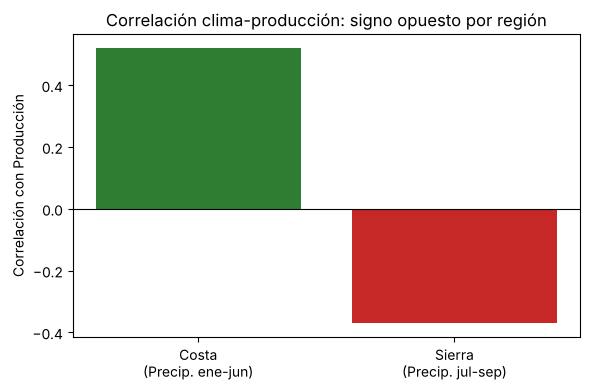

In [17]:
# Se excluyen 2016 y 2017: en ese punto del análisis su producción todavía está incompleta (Paso 1.13)
# y distorsionaría la correlación.
panel_exploratorio = panel_original[~panel_original["anio"].isin([2016, 2017])]
correlacion_costa = panel_exploratorio[panel_exploratorio["region"] == "Costa"][["Precip_S1_Costa", "produccion"]].corr().iloc[0, 1]
correlacion_sierra = panel_exploratorio[panel_exploratorio["region"] == "Sierra"][["Precip_Q3_Sierra", "produccion"]].corr().iloc[0, 1]

print(f"Correlación Precipitación (ene-jun) vs Producción, SOLO en Costa:  {correlacion_costa:+.3f}")
print(f"Correlación Precipitación (jul-sep) vs Producción, SOLO en Sierra: {correlacion_sierra:+.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Costa\n(Precip. ene-jun)", "Sierra\n(Precip. jul-sep)"], [correlacion_costa, correlacion_sierra],
       color=["#2E7D32", "#C62828"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Correlación con Producción")
ax.set_title("Correlación clima-producción: signo opuesto por región")
plt.tight_layout()
plt.show()

TABLAS_PARA_DESCARGAR["Etapa1_Panel_Modelado_Crudo"] = panel_original.assign(
    provincia_clave=panel_original["provincia_clave"].astype(str)
)


## 1.8.1 — ¿Aportan señal la humedad del suelo y la radiación solar?

Además de temperatura y precipitación, Copernicus entrega humedad del suelo (`swvl1`) y radiación
solar (`ssrd`) para el mismo periodo y las mismas provincias (identificadas y asignadas a su
provincia en el paso 1.6, en `ds_humedad`/`asignacion_humedad` y `ds_radiacion`/
`asignacion_radiacion`). Antes de decidir si entran al panel final, se les aplica la misma prueba
que se le acaba de aplicar a la precipitación: calcular su correlación con la producción, a nivel
nacional y separando por región (Costa/Sierra). Como no hay una hipótesis previa sobre qué meses
del año importarían más para estas dos variables (a diferencia de la precipitación, donde la
estacionalidad agrícola sí sugiere ventanas concretas), se usa aquí el promedio anual de cada
variable por provincia. Igual que en el Paso 1.8, se excluyen 2016 y 2017, cuya producción
todavía está incompleta en este punto del análisis (Paso 1.13).

Humedad del suelo procesada: True
Radiación solar procesada: True
Correlación Humedad del suelo vs Producción -> Nacional: -0.219 | Costa: +0.320 | Sierra: -0.813
Correlación Radiación solar vs Producción -> Nacional: -0.489 | Costa: -0.555 | Sierra: +0.517


,Nacional,Costa,Sierra
Humedad del suelo,-0.219222,0.319820,-0.813083
Radiación solar,-0.488979,-0.555192,0.516508


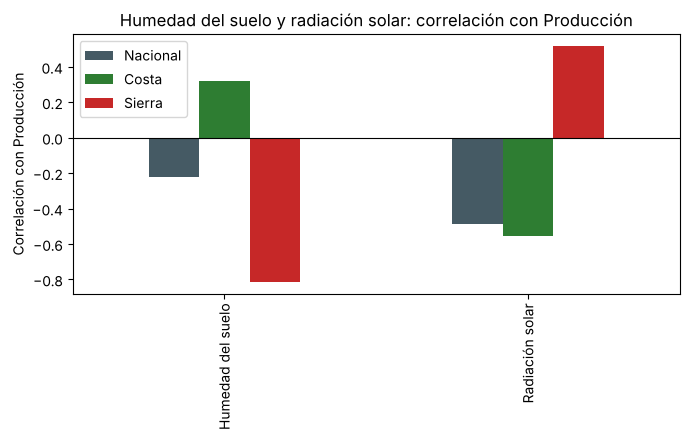

In [18]:
# Mismo procesamiento que a temperatura y precipitación (promediar_por_provincia_y_mes, definida
# en el paso 1.6), aplicado ahora a humedad del suelo y radiación solar.
tabla_humedad = tabla_radiacion = None

if ds_humedad is not None:
    tabla_humedad = promediar_por_provincia_y_mes(ds_humedad, "swvl1", asignacion_humedad, convertir_humedad)
    tabla_humedad["Fecha"] = pd.to_datetime(tabla_humedad["valid_time"]).dt.to_period("M").dt.to_timestamp()
    tabla_humedad["Año"] = tabla_humedad["Fecha"].dt.year
    tabla_humedad["provincia_clave"] = tabla_humedad["Provincia"].apply(normaliza_texto)

if ds_radiacion is not None:
    tabla_radiacion = promediar_por_provincia_y_mes(ds_radiacion, "ssrd", asignacion_radiacion, convertir_radiacion)
    tabla_radiacion["Fecha"] = pd.to_datetime(tabla_radiacion["valid_time"]).dt.to_period("M").dt.to_timestamp()
    tabla_radiacion["Año"] = tabla_radiacion["Fecha"].dt.year
    tabla_radiacion["provincia_clave"] = tabla_radiacion["Provincia"].apply(normaliza_texto)

print("Humedad del suelo procesada:", tabla_humedad is not None)
print("Radiación solar procesada:", tabla_radiacion is not None)

# Promedio anual por provincia (ver nota arriba sobre por qué no se usa una ventana estacional).
humedad_anual = (
    tabla_humedad.groupby(["Año", "provincia_clave"])["swvl1"].mean()
    .rename("humedad_promedio").reset_index()
) if tabla_humedad is not None else None

radiacion_anual = (
    tabla_radiacion.groupby(["Año", "provincia_clave"])["ssrd"].mean()
    .rename("radiacion_promedio").reset_index()
) if tabla_radiacion is not None else None

# Se cruzan contra la producción del panel ya armado en el paso 1.8 (panel_original), solo para
# esta comparación — no se modifica panel_original.
# Igual que en el Paso 1.8, se excluyen 2016-2017 (producción incompleta en ese punto, ver Paso 1.13).
comparacion_clima = panel_original[~panel_original["anio"].isin([2016, 2017])][["anio", "provincia_clave", "region", "produccion"]].rename(columns={"anio": "Año"})
if humedad_anual is not None:
    comparacion_clima = comparacion_clima.merge(humedad_anual, on=["Año", "provincia_clave"], how="left")
if radiacion_anual is not None:
    comparacion_clima = comparacion_clima.merge(radiacion_anual, on=["Año", "provincia_clave"], how="left")

resultados_humedad_radiacion = {}
for nombre_columna, etiqueta in [("humedad_promedio", "Humedad del suelo"), ("radiacion_promedio", "Radiación solar")]:
    if nombre_columna not in comparacion_clima.columns:
        continue
    corr_nacional = comparacion_clima[[nombre_columna, "produccion"]].corr().iloc[0, 1]
    corr_costa = comparacion_clima[comparacion_clima["region"] == "Costa"][[nombre_columna, "produccion"]].corr().iloc[0, 1]
    corr_sierra = comparacion_clima[comparacion_clima["region"] == "Sierra"][[nombre_columna, "produccion"]].corr().iloc[0, 1]
    resultados_humedad_radiacion[etiqueta] = {"Nacional": corr_nacional, "Costa": corr_costa, "Sierra": corr_sierra}
    print(f"Correlación {etiqueta} vs Producción -> Nacional: {corr_nacional:+.3f} | Costa: {corr_costa:+.3f} | Sierra: {corr_sierra:+.3f}")

tabla_comparacion_humedad_radiacion = pd.DataFrame(resultados_humedad_radiacion).T
display(tabla_comparacion_humedad_radiacion)

fig, ax = plt.subplots(figsize=(7, 4.5))
tabla_comparacion_humedad_radiacion.plot(kind="bar", ax=ax, color=["#455A64", "#2E7D32", "#C62828"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Correlación con Producción")
ax.set_title("Humedad del suelo y radiación solar: correlación con Producción")
plt.tight_layout()
plt.show()

**Resultado:** las correlaciones no salieron bajas. Humedad del suelo en la Sierra (-0.813) fue
la correlación más fuerte de todo el análisis climático, más del doble que la de precipitación en
esa misma región (-0.369). Radiación solar también mostró correlaciones moderadas en las tres
particiones (-0.489 nacional, -0.555 Costa, +0.517 Sierra), con signo opuesto entre Costa y
Sierra, igual que la precipitación (+0.520 Costa, -0.369 Sierra). Con este resultado, la
correlación por sí sola no permite descartar estas dos variables; por eso, en el Paso 1.17, se
prueban directamente dentro del modelo para ver si aportan valor predictivo una vez que
precipitación y temperatura ya están incluidas.

## 1.9 — Los dos esquemas de validación cruzada

- **Leave-One-Year-Out (LOYO)**: por cada año, se entrena con los otros 11 y se predice el año
  que se dejó afuera. Mide qué tan bien el modelo generaliza a **años** que nunca vio.
- **Group K-Fold (K=5) por provincia**: reparte las 23 provincias en 5 grupos (de 5, 5, 5, 4 y 4
  provincias); cada pliegue entrena con 4 grupos y predice el restante, que el modelo **nunca vio
  en ningún año**. Es el esquema más exigente para detectar sobreajuste.

**Reparto de provincias fijo y explícito.** El reparto se hace con una semilla (`semilla=42`)
en vez de dejarlo a `sklearn.model_selection.GroupKFold`. Como casi todas las provincias tienen
el mismo número de filas (12 años), `GroupKFold` resuelve los empates de forma distinta según la
versión de scikit-learn: con 1.6 y con 1.9 forma grupos distintos y entrega RMSE distintos para
el mismo modelo. Con el reparto explícito, el resultado no depende de la versión instalada. En
el Paso 1.17.4 se mide cuánto cambian las conclusiones si se usa otro reparto.

In [19]:
def crear_modelo(hiperparametros):
    return XGBRegressor(**hiperparametros, tree_method="hist", enable_categorical=True,
                         random_state=42, verbosity=0)

def prediccion_loyo(X, y, columna_anio, hiperparametros):
    predicciones = pd.Series(index=X.index, dtype=float)
    for anio in sorted(columna_anio.unique()):
        entrenar = columna_anio != anio
        probar = columna_anio == anio
        modelo = crear_modelo(hiperparametros)
        modelo.fit(X[entrenar], y[entrenar])
        predicciones[probar] = modelo.predict(X[probar])
    return predicciones

def pliegues_por_provincia(grupos, k=5, semilla=42):
    '''Asigna cada provincia a uno de k pliegues: baraja la lista de provincias con una semilla
    fija y las reparte en orden (0, 1, ..., k-1, 0, 1, ...). Devuelve el pliegue de cada fila.'''
    provincias = np.array(sorted(pd.unique(np.asarray(grupos))))
    np.random.default_rng(semilla).shuffle(provincias)
    asignacion = {provincia: i % k for i, provincia in enumerate(provincias)}
    return np.array([asignacion[g] for g in np.asarray(grupos)])

def prediccion_group_kfold(X, y, grupos, hiperparametros, k=5, semilla=42):
    predicciones = pd.Series(index=X.index, dtype=float)
    pliegue = pliegues_por_provincia(grupos, k, semilla)
    for f in range(k):
        probar = pliegue == f
        modelo = crear_modelo(hiperparametros)
        modelo.fit(X.loc[~probar], y.loc[~probar])
        predicciones.loc[probar] = modelo.predict(X.loc[probar])
    return predicciones

def rmse(y_real, y_pred):
    return mean_squared_error(y_real, y_pred) ** 0.5

def mejores_hiperparametros(resultados_grid):
    '''Toma la primera fila (menor suma de RMSE) de una búsqueda y la devuelve como diccionario.'''
    hp = resultados_grid.iloc[0][["n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree"]].to_dict()
    hp["n_estimators"], hp["max_depth"] = int(hp["n_estimators"]), int(hp["max_depth"])
    return hp

print("Funciones de validación cruzada definidas.")

Funciones de validación cruzada definidas.


## 1.10 — Búsqueda de hiperparámetros (192 combinaciones), primero sobre los datos tal cual salieron de la extracción

Probamos las 192 combinaciones de 5 hiperparámetros (`n_estimators`, `max_depth`,
`learning_rate`, `subsample`, `colsample_bytree`), sumando el RMSE de LOYO y de Group K-Fold, y
nos quedamos con la de menor suma.


In [20]:
def busqueda_hiperparametros(panel_a_usar, etiqueta=""):
    panel_a_usar = panel_a_usar.copy()
    panel_a_usar["provincia_clave"] = panel_a_usar["provincia_clave"].astype("category")
    columnas_predictoras = ["sembrada", "provincia_clave", "anio",
                             "Precip_S1_Costa", "Precip_Q3_Sierra", "Temp_Q1_Costa"]
    X = panel_a_usar[columnas_predictoras]
    y = panel_a_usar["produccion"]
    grupos_provincia = panel_a_usar["provincia_clave"].astype(str)

    GRILLA = {
        "n_estimators": [100, 200, 300, 500], "max_depth": [2, 3, 4],
        "learning_rate": [0.05, 0.10, 0.20, 0.30], "subsample": [0.8, 1.0], "colsample_bytree": [0.8, 1.0],
    }
    combinaciones = list(itertools.product(*GRILLA.values()))
    inicio = time.time()
    resultados = []
    for combo in combinaciones:
        params = dict(zip(GRILLA.keys(), combo))
        pred_loyo = prediccion_loyo(X, y, panel_a_usar["anio"], params)
        pred_gkf = prediccion_group_kfold(X, y, grupos_provincia, params, k=5)
        resultados.append({**params, "rmse_loyo": rmse(y, pred_loyo), "rmse_group_kfold": rmse(y, pred_gkf),
                            "suma_rmse": rmse(y, pred_loyo) + rmse(y, pred_gkf)})
    resultados = pd.DataFrame(resultados).sort_values("suma_rmse").reset_index(drop=True)
    print(f"{etiqueta}Búsqueda completada en {time.time() - inicio:.0f}s sobre {len(combinaciones)} combinaciones.")
    return resultados

resultados_grid_original = busqueda_hiperparametros(panel_original, etiqueta="[Datos tal cual la extracción] ")
resultados_grid_original.head(5)


[Datos tal cual la extracción] Búsqueda completada en 179s sobre 192 combinaciones.


,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,rmse_loyo,rmse_group_kfold,suma_rmse
0,100,4,0.2,1.0,1.0,57550.053034,82969.583388,140519.636422
1,200,4,0.2,1.0,1.0,57546.664574,83015.691655,140562.356228
2,300,4,0.2,1.0,1.0,57545.669298,83022.635593,140568.304892
3,500,4,0.2,1.0,1.0,57545.414269,83024.520816,140569.935085
4,200,3,0.2,1.0,1.0,59954.815491,83155.965249,143110.780740


In [21]:
mejores_hp_original = mejores_hiperparametros(resultados_grid_original)

panel_original["provincia_clave"] = panel_original["provincia_clave"].astype("category")
columnas_predictoras = ["sembrada", "provincia_clave", "anio", "Precip_S1_Costa", "Precip_Q3_Sierra", "Temp_Q1_Costa"]
X_original = panel_original[columnas_predictoras]
y_original = panel_original["produccion"]

pred_loyo_original = prediccion_loyo(X_original, y_original, panel_original["anio"], mejores_hp_original)

print("Mejores hiperparámetros encontrados:", mejores_hp_original)
print(f"R² LOYO: {r2_score(y_original, pred_loyo_original):.3f}")
print(f"RMSE LOYO: {rmse(y_original, pred_loyo_original):,.0f} Tm")

Mejores hiperparámetros encontrados: {'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.2, 'subsample': 1.0, 'colsample_bytree': 1.0}
R² LOYO: 0.858
RMSE LOYO: 57,550 Tm


## 1.11 — Verificación nacional: aquí aparece algo raro


In [22]:
tabla_verificacion = panel_original.copy()
tabla_verificacion["prediccion"] = pred_loyo_original
agregado_nacional_original = tabla_verificacion.groupby("anio", as_index=False).agg(
    produccion_real=("produccion", "sum"), produccion_predicha=("prediccion", "sum"))
print(agregado_nacional_original.round(0))


    anio  produccion_real  produccion_predicha
0   2014        1488750.0            1520832.0
1   2015        1802951.0            1362994.0
2   2016          85644.0             933725.0
3   2017          73564.0            1000757.0
4   2018        1324084.0             977760.0
5   2019        1479770.0             939503.0
6   2020        1304884.0            1179204.0
7   2021        1699370.0            1523423.0
8   2022        1641131.0            1325142.0
9   2023        1413382.0            1475473.0
10  2024        1195203.0            1040279.0
11  2025        1508854.0            1052573.0


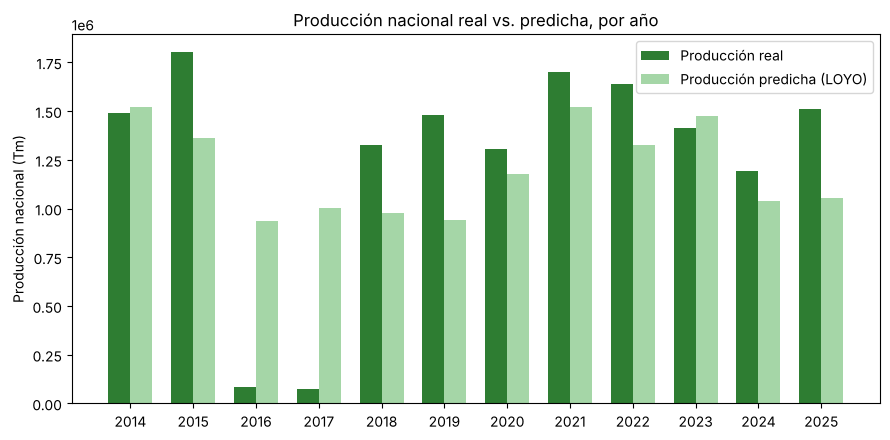

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ancho = 0.35
posiciones = range(len(agregado_nacional_original))
ax.bar([p - ancho/2 for p in posiciones], agregado_nacional_original["produccion_real"], width=ancho, label="Producción real", color="#2E7D32")
ax.bar([p + ancho/2 for p in posiciones], agregado_nacional_original["produccion_predicha"], width=ancho, label="Producción predicha (LOYO)", color="#A5D6A7")
ax.set_xticks(list(posiciones)); ax.set_xticklabels(agregado_nacional_original["anio"])
ax.set_ylabel("Producción nacional (Tm)"); ax.set_title("Producción nacional real vs. predicha, por año")
ax.legend(); plt.tight_layout(); plt.show()


**¿Ves la caída en 2016 y 2017?** Antes de aceptar esto como una mala racha real del maíz
ecuatoriano, lo investigamos.


## 1.12 — Investigando la anomalía: comparación contra FAOSTAT

Antes de aceptar la caída de 2016-2017 como una mala racha real del maíz ecuatoriano, se
contrasta contra FAOSTAT. Hay que tener presente que FAOSTAT **no es una fuente independiente**
de la ESPAC: la FAO compila las cifras oficiales que reporta cada país (para Ecuador, las del
INEC/MAG). Por eso esta comparación sirve para **localizar** la anomalía, no para corregirla.

In [24]:
fao_crudo = pd.read_excel(f"{RUTA_FAOSTAT}/{ARCHIVO_FAOSTAT}")
fao_crudo = fao_crudo[fao_crudo["Item"] == "Maize and products"]
fao_ancho = fao_crudo.pivot_table(index="Year", columns="Element", values="Value", aggfunc="first")
fao_ancho = fao_ancho * 1000   # FAOSTAT reporta en miles de toneladas
fao_ancho = fao_ancho.reset_index().rename(columns={"Year": "Año"})

produccion_espac_por_anio = panel_original.groupby("anio")["produccion"].sum().reset_index().rename(columns={"anio": "Año"})

validacion_faostat = produccion_espac_por_anio.merge(
    fao_ancho[["Año", "Production"]].rename(columns={"Production": "Producción FAOSTAT (TM)"}), on="Año", how="left"
).rename(columns={"produccion": "Producción ESPAC (TM)"})
validacion_faostat["Diferencia (%)"] = (
    validacion_faostat["Producción ESPAC (TM)"] / validacion_faostat["Producción FAOSTAT (TM)"] - 1
) * 100

print(validacion_faostat.to_string(index=False))
TABLAS_PARA_DESCARGAR["Etapa1_Validacion_ESPAC_vs_FAOSTAT"] = validacion_faostat


 Año  Producción ESPAC (TM)  Producción FAOSTAT (TM)  Diferencia (%)
2014           1.488750e+06                1668000.0      -10.746391
2015           1.802951e+06                1874000.0       -3.791286
2016           8.564450e+04                1091000.0      -92.149908
2017           7.356430e+04                1436000.0      -94.877138
2018           1.324084e+06                1324000.0        0.006325
2019           1.479770e+06                1480000.0       -0.015548
2020           1.304884e+06                1305000.0       -0.008859
2021           1.699370e+06                1699000.0        0.021754
2022           1.641131e+06                1641000.0        0.007997
2023           1.413382e+06                1413000.0        0.027046
2024           1.195203e+06                      NaN             NaN
2025           1.508854e+06                      NaN             NaN


**Lectura de la tabla:**

- **2018-2023:** ESPAC y FAOSTAT coinciden prácticamente (diferencias menores a 0.03%).
- **2014 y 2015:** hay diferencias de alrededor de -10.7% y -3.8%. Una parte se explica porque
  aquí ya se excluyeron las Zonas No Delimitadas (Paso 1.4): con ellas, la ESPAC da 1,510,343 Tm
  en 2014 (-9.5%) y 1,847,444 Tm en 2015 (-1.4%). La diferencia restante de 2014 no se investiga
  en este trabajo; no cambia el orden de magnitud.
- **2016 y 2017:** la extracción entrega apenas el 5-8% de lo que reporta FAOSTAT (diferencias de
  -92% y -95%). Esto no es un shock climático: la superficie sembrada de esos años sí es normal
  (~340-390 mil ha), lo que apunta a un problema en la variable de producción. El Paso 1.13 lo
  diagnostica.

## 1.13 — Diagnóstico: la variable `ct_prod` viene casi vacía en los `.csv` de 2016-2017

`ct_prod` (producción en Tm) es una variable **derivada** que el INEC calcula a partir de la
cantidad cosechada declarada por el productor: `ct_k516` (cantidad, en la unidad que usa el
productor: quintales, sacos, etc.) y `ct_k518` (peso de esa unidad, en libras). La celda siguiente
comprueba dos cosas:

1. En 2014 y 2015, `ct_prod` es exactamente `ct_k516 × ct_k518 / 2200` en todos los registros.
2. En 2016 y 2017, cuántos registros de maíz duro seco traen `ct_prod` y cuántos traen la
   cantidad cosechada cruda.

In [25]:
filas_diagnostico = []

for anio, archivo in [(2014, "ct_nac2014.sav"), (2015, "ctnac_2015.sav")]:
    df_sav, _ = pyreadstat.read_sav(f"{RUTA_ESPAC}/{archivo}",
                                    usecols=["ct_clacul", "ct_prod", "ct_k516", "ct_k518"])
    maiz_sav = df_sav[df_sav["ct_clacul"] == 548]
    regla = maiz_sav["ct_k516"] * maiz_sav["ct_k518"] / 2200
    filas_diagnostico.append({
        "Año": anio, "Registros maíz duro seco": len(maiz_sav),
        "Con ct_prod": maiz_sav["ct_prod"].notna().sum(),
        "Con cantidad cosechada (ct_k516 y ct_k518)": (maiz_sav["ct_k516"].notna() & maiz_sav["ct_k518"].notna()).sum(),
        "Máx. |ct_prod - ct_k516×ct_k518/2200|": (maiz_sav["ct_prod"] - regla).abs().max(),
    })

for anio, archivo in [(2016, "ctnac2016.csv"), (2017, "ctnac2017.csv")]:
    df_csv = pd.read_csv(f"{RUTA_ESPAC}/{archivo}", sep=";", decimal=",", encoding="utf-8-sig", low_memory=False)
    for columna in ["ct_nclavr", "ct_prod", "ct_k516", "ct_k518"]:
        df_csv[columna] = pd.to_numeric(df_csv[columna], errors="coerce")
    maiz_csv = df_csv[df_csv["ct_nclavr"] == 548]
    regla = maiz_csv["ct_k516"] * maiz_csv["ct_k518"] / 2200
    filas_diagnostico.append({
        "Año": anio, "Registros maíz duro seco": len(maiz_csv),
        "Con ct_prod": maiz_csv["ct_prod"].notna().sum(),
        "Con cantidad cosechada (ct_k516 y ct_k518)": (maiz_csv["ct_k516"].notna() & maiz_csv["ct_k518"].notna()).sum(),
        "Máx. |ct_prod - ct_k516×ct_k518/2200|": (maiz_csv["ct_prod"] - regla).abs().max(),
    })

diagnostico_ct_prod = pd.DataFrame(filas_diagnostico)
diagnostico_ct_prod["% con ct_prod"] = (diagnostico_ct_prod["Con ct_prod"] / diagnostico_ct_prod["Registros maíz duro seco"] * 100).round(1)
TABLAS_PARA_DESCARGAR["Etapa1_Diagnostico_ct_prod"] = diagnostico_ct_prod
diagnostico_ct_prod

,Año,Registros maíz duro seco,Con ct_prod,Con cantidad cosechada (ct_k516 y ct_k518),Máx. |ct_prod - ct_k516×ct_k518/2200|,% con ct_prod
0,2014,3117,3086,3086,4.545455e-07,99.0
1,2015,3427,3402,3402,4.545655e-09,99.3
2,2016,3273,87,3209,3.500000e+01,2.7
3,2017,3695,101,3646,0.000000e+00,2.7


**Causa encontrada:** en 2014-2015, `ct_prod` está completa y coincide con
`ct_k516 × ct_k518 / 2200` (está en el 99% de los registros y, donde está, la diferencia máxima
es menor a una millonésima de tonelada). En los `.csv` de 2016 y
2017, en cambio, `ct_prod` solo viene llena en el 2.7% de los registros de maíz duro seco, mientras
que la cantidad cosechada cruda está prácticamente completa. La caída de 2016-2017 no es un
fenómeno real ni un subregistro de la encuesta: es una **variable derivada incompleta en los
archivos publicados**, que se puede reconstruir con la misma regla que el INEC usa en los demás
años.

## 1.14 — Corrección: reconstruir la producción 2016-2017 desde el microdato, y validarla contra el INEC

Se vuelve a extraer 2016-2017 con `reconstruir_produccion=True` (Paso 1.2): donde `ct_prod` falta,
se calcula como `ct_k516 × ct_k518 / 2200`. Así se obtiene la producción de las **23
provincias** directamente del microdato oficial, con el mismo método que en 2014-2015, sin
repartos ni supuestos.

La reconstrucción se valida contra los Informes Ejecutivos de la ESPAC 2016 y 2017 (INEC), que
publican la producción de las 3 provincias líderes (Los Ríos, Manabí y Guayas, entre el 82% y el
86% del total nacional) y un agregado del resto:

| Año | Los Ríos | Manabí | Guayas | Resto de provincias | Total |
|---|---|---|---|---|---|
| 2016 | 437,196 Tm | 320,853 Tm | 134,526 Tm | 198,533 Tm | 1,091,108 Tm |
| 2017 | 566,043 Tm | 355,230 Tm | 315,390 Tm | 199,443 Tm | 1,436,106 Tm |

Fuentes:
- INEC, *Informe Ejecutivo ESPAC 2016*: https://www.ecuadorencifras.gob.ec/documentos/web-inec/Estadisticas_agropecuarias/espac/espac-2016/Informe%20ejecutivo%20ESPAC_2016.pdf
- INEC, *Informe Ejecutivo ESPAC 2017*: https://www.ecuadorencifras.gob.ec/documentos/web-inec/Estadisticas_agropecuarias/espac/espac_2017/Informe_Ejecutivo_ESPAC_2017.pdf

In [26]:
# 1) Re-extracción de 2016-2017 con la producción reconstruida.
maiz_2016_rec = extraer_espac_csv(f"{RUTA_ESPAC}/ctnac2016.csv", 2016, reconstruir_produccion=True)
maiz_2017_rec = extraer_espac_csv(f"{RUTA_ESPAC}/ctnac2017.csv", 2017, reconstruir_produccion=True)
maiz_1617 = pd.concat([maiz_2016_rec, maiz_2017_rec], ignore_index=True)
maiz_1617["provincia_clave"] = maiz_1617["provincia"].apply(normaliza_texto).replace(CORRECCIONES_PROVINCIA)
produccion_1617 = maiz_1617.groupby(["anio", "provincia_clave"])["produccion_expandida"].sum()

# 2) Validación contra los Informes Ejecutivos del INEC (incluye Zonas No Delimitadas, como el INEC).
PRODUCCION_OFICIAL_INEC = {
    2016: {"LOS RIOS": 437196, "MANABI": 320853, "GUAYAS": 134526, "RESTO": 198533},
    2017: {"LOS RIOS": 566043, "MANABI": 355230, "GUAYAS": 315390, "RESTO": 199443},
}
PROVINCIAS_TOP3 = ["LOS RIOS", "MANABI", "GUAYAS"]
filas_validacion = []
for anio, oficial in PRODUCCION_OFICIAL_INEC.items():
    reconstruido = produccion_1617.loc[anio]
    valores = {p: reconstruido.get(p, 0.0) for p in PROVINCIAS_TOP3}
    valores["RESTO"] = reconstruido.drop(PROVINCIAS_TOP3, errors="ignore").sum()
    valores["TOTAL"] = reconstruido.sum()
    oficial = {**oficial, "TOTAL": sum(oficial.values())}
    for grupo in PROVINCIAS_TOP3 + ["RESTO", "TOTAL"]:
        filas_validacion.append({"Año": anio, "Grupo": grupo, "Reconstruido (Tm)": round(valores[grupo]),
                                 "INEC Informe Ejecutivo (Tm)": oficial[grupo],
                                 "Diferencia (%)": round((valores[grupo] / oficial[grupo] - 1) * 100, 1)})
validacion_inec = pd.DataFrame(filas_validacion)
TABLAS_PARA_DESCARGAR["Etapa1_Validacion_2016_2017_vs_INEC"] = validacion_inec
print("Reconstrucción 2016-2017 vs. Informes Ejecutivos del INEC:")
print(validacion_inec.to_string(index=False))

# 3) Panel corregido: igual al original, reemplazando solo la producción de 2016 y 2017.
panel_corregido = panel_original.copy()
clave_texto = panel_corregido["provincia_clave"].astype(str)
filas_actualizadas = 0
for (anio, provincia), valor in produccion_1617.items():
    filtro = (panel_corregido["anio"] == anio) & (clave_texto == provincia)
    filas_actualizadas += int(filtro.sum())
    panel_corregido.loc[filtro, "produccion"] = valor
filas_1617 = int(panel_corregido["anio"].isin([2016, 2017]).sum())
print(f"\nFilas provincia-año actualizadas: {filas_actualizadas} de {filas_1617} filas de 2016-2017 en el panel.")

print("\nProducción nacional por año (sin Zonas No Delimitadas), ANTES vs. DESPUÉS de la corrección:")
comparacion_correccion = pd.DataFrame({
    "Antes (ct_prod incompleta)": panel_original.groupby("anio")["produccion"].sum(),
    "Después (reconstruida del microdato)": panel_corregido.groupby("anio")["produccion"].sum(),
}).round(0)
comparacion_correccion

Reconstrucción 2016-2017 vs. Informes Ejecutivos del INEC:
 Año    Grupo  Reconstruido (Tm)  INEC Informe Ejecutivo (Tm)  Diferencia (%)
2016 LOS RIOS             432679                       437196            -1.0
2016   MANABI             320412                       320853            -0.1
2016   GUAYAS             134531                       134526             0.0
2016    RESTO             221174                       198533            11.4
2016    TOTAL            1108796                      1091108             1.6
2017 LOS RIOS             558017                       566043            -1.4
2017   MANABI             355269                       355230             0.0
2017   GUAYAS             309453                       315390            -1.9
2017    RESTO             214912                       199443             7.8
2017    TOTAL            1437650                      1436106             0.1

Filas provincia-año actualizadas: 45 de 45 filas de 2016-2017 en el panel.

Produc

,Antes (ct_prod incompleta),Después (reconstruida del microdato)
anio,,
2014,1488750.0,1488750.0
2015,1802951.0,1802951.0
2016,85644.0,1108750.0
2017,73564.0,1437638.0
2018,1324084.0,1324084.0
2019,1479770.0,1479770.0
2020,1304884.0,1304884.0
2021,1699370.0,1699370.0
2022,1641131.0,1641131.0


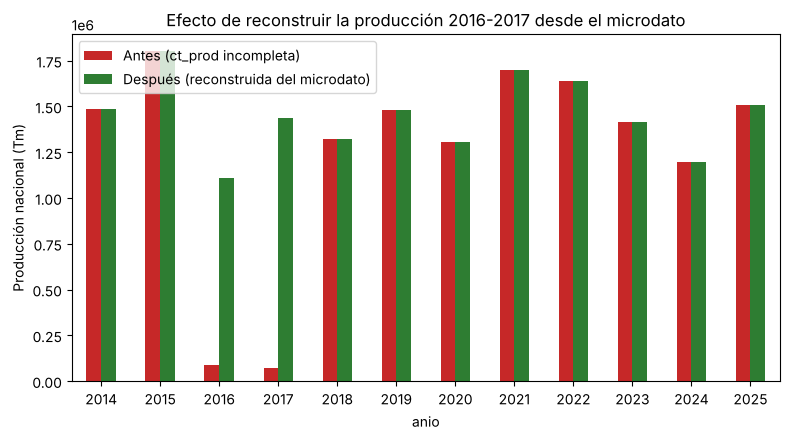

In [27]:
fig, ax = plt.subplots(figsize=(8, 4.5))
comparacion_correccion.plot(kind="bar", ax=ax, color=["#C62828", "#2E7D32"])
ax.set_ylabel("Producción nacional (Tm)")
ax.set_title("Efecto de reconstruir la producción 2016-2017 desde el microdato")
ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Resultado de la validación:** la producción reconstruida desde el microdato coincide con los
Informes Ejecutivos del INEC en las tres provincias líderes (Los Ríos -1.0% y -1.4%, Manabí -0.1% y
0.0%, Guayas 0.0% y -1.9%, en 2016 y 2017) y en el total nacional (+1.6% en 2016 y +0.1% en 2017).
La diferencia más grande está en el agregado "Resto de provincias" (+11.4% y +7.8%), que reúne 20
provincias pequeñas. Con esto, las 23 provincias de 2016-2017 salen del microdato oficial, con el
mismo método que 2014-2015, y no de un reparto aproximado.

## 1.15 — Reentrenar: ¿mejora de verdad, o es casualidad?

En vez de reutilizar los hiperparámetros que ganaron con el panel original, **repetimos la
búsqueda completa de 192 combinaciones**, ahora sobre el panel ya corregido. Esto es importante
por criterio técnico: si mantuviéramos fija una configuración de hiperparámetros que se ajustó a
un panel con un problema de datos, no podríamos saber si una mejora posterior viene de la
corrección de los datos o de haber "heredado" una configuración que ya no es la más adecuada.
Repetir la búsqueda desde cero aísla ambos efectos.


In [28]:
resultados_grid_corregido = busqueda_hiperparametros(panel_corregido, etiqueta="[Panel corregido] ")
print("\nLas 5 mejores combinaciones encontradas (panel CORREGIDO):")
resultados_grid_corregido.head(5)


[Panel corregido] Búsqueda completada en 178s sobre 192 combinaciones.

Las 5 mejores combinaciones encontradas (panel CORREGIDO):


,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,rmse_loyo,rmse_group_kfold,suma_rmse
0,100,2,0.30,1.0,1.0,28914.481480,75768.306309,104682.787789
1,200,2,0.30,1.0,1.0,28808.304164,76076.413133,104884.717297
2,300,2,0.30,1.0,1.0,28762.888363,76239.446113,105002.334476
3,500,2,0.30,1.0,1.0,28739.917270,76300.841130,105040.758400
4,200,2,0.05,0.8,1.0,30236.916606,76332.013820,106568.930426


In [29]:
mejores_hp = mejores_hiperparametros(resultados_grid_corregido)

print("Mejor combinación encontrada (panel corregido):", mejores_hp)
print("Mejor combinación encontrada (panel original, para contraste):", mejores_hp_original)

Mejor combinación encontrada (panel corregido): {'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.3, 'subsample': 1.0, 'colsample_bytree': 1.0}
Mejor combinación encontrada (panel original, para contraste): {'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.2, 'subsample': 1.0, 'colsample_bytree': 1.0}


## 1.16 — Métricas finales de Producción, con el panel corregido


In [30]:
panel_corregido["provincia_clave"] = panel_corregido["provincia_clave"].astype("category")
X_corregido = panel_corregido[columnas_predictoras]
y_corregido = panel_corregido["produccion"]
grupos_corregido = panel_corregido["provincia_clave"].astype(str)

pred_loyo_corregido = prediccion_loyo(X_corregido, y_corregido, panel_corregido["anio"], mejores_hp)
pred_gkf_corregido = prediccion_group_kfold(X_corregido, y_corregido, grupos_corregido, mejores_hp, k=5)

panel_corregido["prediccion_loyo"] = pred_loyo_corregido
panel_corregido["prediccion_group_kfold"] = pred_gkf_corregido

metricas_etapa1 = pd.DataFrame({
    "Panel original (sin corregir)": {
        "R2_LOYO": r2_score(y_original, pred_loyo_original), "RMSE_LOYO": rmse(y_original, pred_loyo_original),
        "MAE_LOYO": mean_absolute_error(y_original, pred_loyo_original),
        "R2_GroupKFold": np.nan, "RMSE_GroupKFold": np.nan, "MAE_GroupKFold": np.nan,
    },
    "Panel corregido (modelo final)": {
        "R2_LOYO": r2_score(y_corregido, pred_loyo_corregido), "RMSE_LOYO": rmse(y_corregido, pred_loyo_corregido),
        "MAE_LOYO": mean_absolute_error(y_corregido, pred_loyo_corregido),
        "R2_GroupKFold": r2_score(y_corregido, pred_gkf_corregido), "RMSE_GroupKFold": rmse(y_corregido, pred_gkf_corregido),
        "MAE_GroupKFold": mean_absolute_error(y_corregido, pred_gkf_corregido),
    },
}).round(3)

metricas_etapa1


,Panel original (sin corregir),Panel corregido (modelo final)
R2_LOYO,0.858,0.967
RMSE_LOYO,57550.053,28914.481
MAE_LOYO,19545.949,11053.136
R2_GroupKFold,NaN,0.775
RMSE_GroupKFold,NaN,75768.306
MAE_GroupKFold,NaN,30192.728


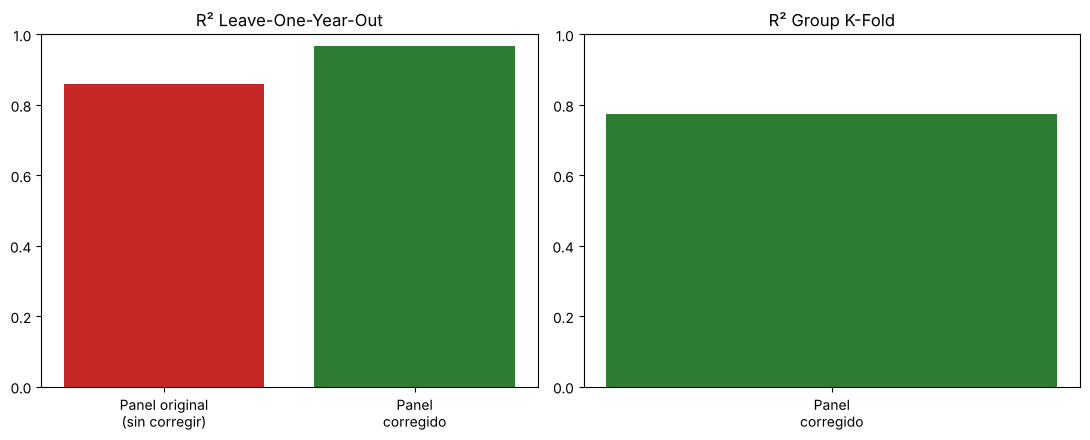

La barra roja ("sin corregir") queda vacía en Group K-Fold: ese número no se interpreta
antes de corregir el problema de origen.


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
etiquetas = ["Panel original\n(sin corregir)", "Panel\ncorregido"]

r2_loyo_vals = [metricas_etapa1.loc["R2_LOYO", "Panel original (sin corregir)"],
                metricas_etapa1.loc["R2_LOYO", "Panel corregido (modelo final)"]]
r2_gkf_vals = [np.nan, metricas_etapa1.loc["R2_GroupKFold", "Panel corregido (modelo final)"]]

axes[0].bar(etiquetas, r2_loyo_vals, color=["#C62828", "#2E7D32"])
axes[0].set_title("R² Leave-One-Year-Out")
axes[0].set_ylim(0, 1)

axes[1].bar(etiquetas, r2_gkf_vals, color=["#C62828", "#2E7D32"])
axes[1].set_title("R² Group K-Fold")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

print("La barra roja (\"sin corregir\") queda vacía en Group K-Fold: ese número no se interpreta")
print("antes de corregir el problema de origen.")


**Lectura:** con los mismos esquemas de validación y re-buscando los hiperparámetros, el RMSE LOYO
baja de 57,550 Tm (panel original) a 28,914 Tm (panel corregido), y el R² LOYO sube de 0.858 a
0.967. Lo único que cambió entre ambos paneles es la producción de 2016-2017, así que la mejora
se debe a la calidad del dato de entrada.

**Cómo leer el R² de 0.967:** se calcula sobre las 270 observaciones provincia-año, y buena parte de
esa varianza es la diferencia de tamaño entre provincias (Los Ríos produce cientos de veces más
que una provincia de la Sierra). Por eso el R² es alto aunque el error nacional no sea pequeño:
al sumar las predicciones por año (Paso 1.19), el R² nacional es 0.134 y el MAPE nacional 10.9%.
Ambas cifras se reportan en el resumen final.

## 1.17 — Prueba de ablación: ¿el clima realmente ayuda?

La forma correcta de comprobar si una variable aporta no es mirar su "importancia" nominal
dentro del modelo, sino una **prueba de ablación**: entrenar el mismo modelo, con los mismos
hiperparámetros, una vez **con** esa variable y otra vez **sin** ella, y comparar el resultado.
Usamos el esquema Group K-Fold (el más exigente) para esta prueba.


In [32]:
columnas_sin_clima = ["sembrada", "provincia_clave", "anio"]
X_sin_clima = panel_corregido[columnas_sin_clima]

pred_gkf_sin_clima = prediccion_group_kfold(X_sin_clima, y_corregido, grupos_corregido, mejores_hp, k=5)

r2_con_clima = r2_score(y_corregido, pred_gkf_corregido)
r2_sin_clima = r2_score(y_corregido, pred_gkf_sin_clima)

print(f"R² Group K-Fold CON variables climáticas: {r2_con_clima:.3f}")
print(f"R² Group K-Fold SIN variables climáticas: {r2_sin_clima:.3f}")
print(f"Diferencia: {r2_con_clima - r2_sin_clima:+.3f}")


R² Group K-Fold CON variables climáticas: 0.775
R² Group K-Fold SIN variables climáticas: 0.702
Diferencia: +0.073


**Resultado:** el R² Group K-Fold pasa de 0.702 sin clima a 0.775 con clima (+0.073).

**Si la diferencia sale positiva**, es evidencia de que el clima aporta información real al
modelo, aunque su contribución nominal ("gain") parezca chica cuando se mira variable por
variable — por eso la prueba de ablación es el criterio que usamos para decidir si una variable
se queda, no la importancia nominal por sí sola.


## 1.17.1 — ¿Mejora el modelo si se agregan humedad y radiación?

En el paso 1.8.1 se calculó la correlación de humedad del suelo y radiación solar con la
producción, separando por región. Humedad del suelo mostró una correlación notablemente más
fuerte en la Sierra que la que tiene precipitación en esa misma región, y radiación solar mostró
el mismo patrón de signo opuesto entre Costa y Sierra que ya se había encontrado para
precipitación. Antes de descartarlas definitivamente, se construyen para ambas las mismas
interacciones región-clima aplicadas en el paso 1.8 a precipitación y temperatura, y se repite la
búsqueda de hiperparámetros (192 combinaciones, mismo esquema LOYO + Group K-Fold) sobre un panel
que las incluye, para comparar su desempeño contra el modelo de tres variables climáticas del
paso 1.15.

Esta comparación es exploratoria y no reemplaza nada de lo ya calculado arriba: se guarda en
variables nuevas (`panel_corregido_extendido`, `resultados_grid_extendido`, etc.), por lo que
`panel_corregido`, `mejores_hp` y todo lo que viene después (1.18 en adelante) sigue funcionando
exactamente igual, sin importar el resultado de esta prueba.

In [33]:
# Se construyen las mismas interacciones región-clima ya aplicadas a precipitación y temperatura
# en el paso 1.8, ahora para humedad del suelo y radiación solar (calculadas en el paso 1.8.1).
panel_corregido_extendido = panel_corregido.copy()

humedad_para_panel = humedad_anual.rename(columns={"Año": "anio"})
radiacion_para_panel = radiacion_anual.rename(columns={"Año": "anio"})

panel_corregido_extendido = panel_corregido_extendido.merge(humedad_para_panel, on=["anio", "provincia_clave"], how="left")
panel_corregido_extendido = panel_corregido_extendido.merge(radiacion_para_panel, on=["anio", "provincia_clave"], how="left")

panel_corregido_extendido["Humedad_Costa"] = np.where(panel_corregido_extendido["region"] == "Costa", panel_corregido_extendido["humedad_promedio"], 0.0)
panel_corregido_extendido["Humedad_Sierra"] = np.where(panel_corregido_extendido["region"] == "Sierra", panel_corregido_extendido["humedad_promedio"], 0.0)
panel_corregido_extendido["Radiacion_Costa"] = np.where(panel_corregido_extendido["region"] == "Costa", panel_corregido_extendido["radiacion_promedio"], 0.0)
panel_corregido_extendido["Radiacion_Sierra"] = np.where(panel_corregido_extendido["region"] == "Sierra", panel_corregido_extendido["radiacion_promedio"], 0.0)

print(f"Panel extendido: {panel_corregido_extendido.shape[0]} filas, {panel_corregido_extendido.shape[1]} columnas")
print("Valores vacíos en las columnas nuevas (no debería haber ninguno):")
print(panel_corregido_extendido[["Humedad_Costa", "Humedad_Sierra", "Radiacion_Costa", "Radiacion_Sierra"]].isnull().sum())

Panel extendido: 270 filas, 17 columnas
Valores vacíos en las columnas nuevas (no debería haber ninguno):
Humedad_Costa       0
Humedad_Sierra      0
Radiacion_Costa     0
Radiacion_Sierra    0
dtype: int64


In [34]:
# Misma función que busqueda_hiperparametros (paso 1.10), generalizada para aceptar una lista de
# columnas predictoras distinta, sin modificar la función original.
def busqueda_hiperparametros_columnas(panel_a_usar, columnas_predictoras_usar, etiqueta=""):
    panel_a_usar = panel_a_usar.copy()
    panel_a_usar["provincia_clave"] = panel_a_usar["provincia_clave"].astype("category")
    X = panel_a_usar[columnas_predictoras_usar]
    y = panel_a_usar["produccion"]
    grupos_provincia = panel_a_usar["provincia_clave"].astype(str)

    GRILLA = {
        "n_estimators": [100, 200, 300, 500], "max_depth": [2, 3, 4],
        "learning_rate": [0.05, 0.10, 0.20, 0.30], "subsample": [0.8, 1.0], "colsample_bytree": [0.8, 1.0],
    }
    combinaciones = list(itertools.product(*GRILLA.values()))
    inicio = time.time()
    resultados = []
    for combo in combinaciones:
        params = dict(zip(GRILLA.keys(), combo))
        pred_loyo = prediccion_loyo(X, y, panel_a_usar["anio"], params)
        pred_gkf = prediccion_group_kfold(X, y, grupos_provincia, params, k=5)
        resultados.append({**params, "rmse_loyo": rmse(y, pred_loyo), "rmse_group_kfold": rmse(y, pred_gkf),
                            "suma_rmse": rmse(y, pred_loyo) + rmse(y, pred_gkf)})
    resultados = pd.DataFrame(resultados).sort_values("suma_rmse").reset_index(drop=True)
    print(f"{etiqueta}Búsqueda completada en {time.time() - inicio:.0f}s sobre {len(combinaciones)} combinaciones.")
    return resultados

columnas_predictoras_extendidas = columnas_predictoras + ["Humedad_Costa", "Humedad_Sierra", "Radiacion_Costa", "Radiacion_Sierra"]

resultados_grid_extendido = busqueda_hiperparametros_columnas(
    panel_corregido_extendido, columnas_predictoras_extendidas,
    etiqueta="[Panel corregido + humedad/radiación] ",
)
print("\nLas 5 mejores combinaciones encontradas (panel corregido + humedad/radiación):")
resultados_grid_extendido.head(5)

[Panel corregido + humedad/radiación] Búsqueda completada en 201s sobre 192 combinaciones.

Las 5 mejores combinaciones encontradas (panel corregido + humedad/radiación):


,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,rmse_loyo,rmse_group_kfold,suma_rmse
0,200,2,0.05,0.8,1.0,30724.345095,75236.164752,105960.509847
1,500,2,0.05,0.8,1.0,30927.161368,76095.955158,107023.116526
2,300,2,0.05,0.8,1.0,30774.646542,76433.607588,107208.254130
3,100,2,0.30,1.0,1.0,30729.094273,77328.301399,108057.395672
4,200,2,0.30,1.0,1.0,30986.538396,77684.539530,108671.077926


                 Precip. + Temp. (paso 1.15)  + Humedad + Radiación
RMSE_LOYO                            28914.5                30724.3
RMSE_GroupKFold                      75768.3                75236.2


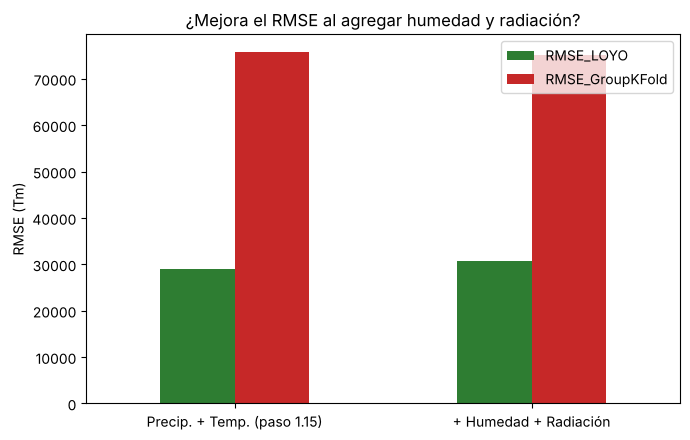

In [35]:
# Comparación directa contra el modelo de tres variables climáticas ya encontrado en el paso 1.15
# (resultados_grid_corregido), usando el mismo criterio: la mejor combinación de cada búsqueda.
comparacion_extension = pd.DataFrame({
    "Precip. + Temp. (paso 1.15)": {
        "RMSE_LOYO": resultados_grid_corregido.iloc[0]["rmse_loyo"],
        "RMSE_GroupKFold": resultados_grid_corregido.iloc[0]["rmse_group_kfold"],
    },
    "+ Humedad + Radiación": {
        "RMSE_LOYO": resultados_grid_extendido.iloc[0]["rmse_loyo"],
        "RMSE_GroupKFold": resultados_grid_extendido.iloc[0]["rmse_group_kfold"],
    },
}).round(1)

print(comparacion_extension)

fig, ax = plt.subplots(figsize=(7, 4.5))
comparacion_extension.T.plot(kind="bar", ax=ax, color=["#2E7D32", "#C62828"])
ax.set_ylabel("RMSE (Tm)")
ax.set_title("¿Mejora el RMSE al agregar humedad y radiación?")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Resultado:** al agregar humedad y radiación, el RMSE LOYO empeora (28,914.5 sin ellas vs. 30,724.3
con ellas), y el RMSE Group K-Fold apenas cambia (75,768.3 vs. 75,236.2, una diferencia de 0.7%).
A pesar de que ambas variables mostraban una correlación individual relevante en el Paso 1.8.1
(sobre todo humedad en la Sierra), no aportan información adicional una vez que el modelo ya
cuenta con precipitación y temperatura. La explicación más probable es la colinealidad entre
variables climáticas: más lluvia tiende a asociarse con más humedad del suelo y con menos
radiación solar, así que buena parte de esa señal ya la captura la precipitación.

## 1.17.2 — ¿Y si se reemplazan precipitación y temperatura, en vez de sumarles humedad y radiación?

En el paso 1.17.1 se probó **sumar** humedad y radiación a las tres variables climáticas ya
existentes, y el RMSE empeoró. Pero esa prueba no responde una pregunta distinta: ¿qué pasa si, en
vez de sumarlas, se **reemplazan** precipitación y temperatura por humedad y radiación? Tiene
sentido probarlo porque humedad en la Sierra mostró, en el paso 1.8.1, una correlación individual
más fuerte que la de precipitación en esa misma región — el problema podría no ser que humedad y
radiación no sirvan, sino que sumarlas genera redundancia con las variables que ya estaban.

Se repite la búsqueda de hiperparámetros una vez más, ahora con un panel que usa **únicamente**
`Humedad_Costa`, `Humedad_Sierra`, `Radiacion_Costa` y `Radiacion_Sierra` como variables
climáticas (sin `Precip_S1_Costa`, `Precip_Q3_Sierra` ni `Temp_Q1_Costa`), y se comparan las tres
versiones en una sola tabla.

In [36]:
# Mismo panel que en 1.17.1 (panel_corregido_extendido ya tiene las columnas de humedad y
# radiación), pero esta vez SIN precipitación ni temperatura entre las columnas predictoras.
columnas_predictoras_reemplazo = [
    "sembrada", "provincia_clave", "anio",
    "Humedad_Costa", "Humedad_Sierra", "Radiacion_Costa", "Radiacion_Sierra",
]

resultados_grid_reemplazo = busqueda_hiperparametros_columnas(
    panel_corregido_extendido, columnas_predictoras_reemplazo,
    etiqueta="[Panel corregido, humedad/radiación EN VEZ DE precip/temp] ",
)
print("\nLas 5 mejores combinaciones encontradas (reemplazo, sin precipitación ni temperatura):")
resultados_grid_reemplazo.head(5)

[Panel corregido, humedad/radiación EN VEZ DE precip/temp] Búsqueda completada en 183s sobre 192 combinaciones.

Las 5 mejores combinaciones encontradas (reemplazo, sin precipitación ni temperatura):


,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,rmse_loyo,rmse_group_kfold,suma_rmse
0,200,2,0.05,0.8,1.0,31215.252389,80343.692248,111558.944637
1,300,2,0.05,0.8,1.0,31455.158837,80260.877378,111716.036216
2,500,2,0.05,0.8,1.0,32076.172918,80552.874888,112629.047806
3,100,2,0.30,1.0,1.0,31668.042591,81516.132693,113184.175284
4,300,2,0.05,1.0,1.0,31529.550942,81820.367969,113349.918911


                 Precip. + Temp.\n(paso 1.15)  \
RMSE_LOYO                             28914.5   
RMSE_GroupKFold                       75768.3   

                 Precip. + Temp.\n+ Humedad + Radiación\n(paso 1.17.1)  \
RMSE_LOYO                                                  30724.3       
RMSE_GroupKFold                                            75236.2       

                 Humedad + Radiación\n(sin Precip. ni Temp.)  
RMSE_LOYO                                            31215.3  
RMSE_GroupKFold                                      80343.7  


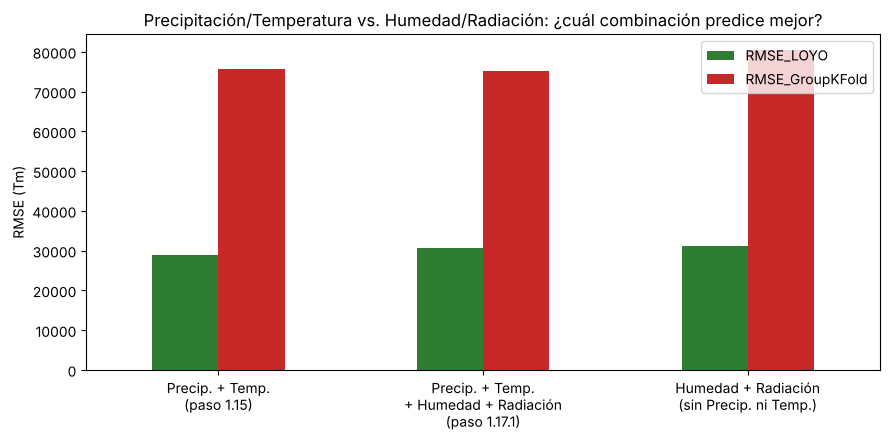

In [37]:
# Comparación de las tres versiones: la original (1.15), sumando humedad/radiación (1.17.1), y
# reemplazando precipitación/temperatura por humedad/radiación (esta celda).
comparacion_reemplazo = pd.DataFrame({
    "Precip. + Temp.\n(paso 1.15)": {
        "RMSE_LOYO": resultados_grid_corregido.iloc[0]["rmse_loyo"],
        "RMSE_GroupKFold": resultados_grid_corregido.iloc[0]["rmse_group_kfold"],
    },
    "Precip. + Temp.\n+ Humedad + Radiación\n(paso 1.17.1)": {
        "RMSE_LOYO": resultados_grid_extendido.iloc[0]["rmse_loyo"],
        "RMSE_GroupKFold": resultados_grid_extendido.iloc[0]["rmse_group_kfold"],
    },
    "Humedad + Radiación\n(sin Precip. ni Temp.)": {
        "RMSE_LOYO": resultados_grid_reemplazo.iloc[0]["rmse_loyo"],
        "RMSE_GroupKFold": resultados_grid_reemplazo.iloc[0]["rmse_group_kfold"],
    },
}).round(1)

print(comparacion_reemplazo)

fig, ax = plt.subplots(figsize=(9, 4.5))
comparacion_reemplazo.T.plot(kind="bar", ax=ax, color=["#2E7D32", "#C62828"])
ax.set_ylabel("RMSE (Tm)")
ax.set_title("Precipitación/Temperatura vs. Humedad/Radiación: ¿cuál combinación predice mejor?")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Resultado:** el reemplazo resulta peor que el panel original en ambos esquemas (RMSE LOYO:
31,215.3 frente a 28,914.5 de Precip. + Temp.; RMSE Group K-Fold: 80,343.7 frente a 75,768.3).

## 1.17.3 — Comparando todas las combinaciones no redundantes de variables climáticas

Con cuatro variables climáticas candidatas (precipitación, temperatura, humedad del suelo y
radiación solar), hay varias formas de combinarlas de dos en dos. Emparejar dos variables que
miden un fenómeno similar aporta poca información adicional entre sí, porque tienden a moverse
juntas: precipitación y humedad del suelo están ambas relacionadas con el agua disponible, y
temperatura y radiación solar están ambas relacionadas con la energía térmica. Por eso aquí solo
se comparan las combinaciones "cruzadas", que emparejan una variable de agua con una de energía
térmica, dejando fuera las combinaciones redundantes (precipitación con humedad, o temperatura con
radiación):

- Precipitación + Temperatura (el panel final ya elegido en el paso 1.15)
- Precipitación + Radiación
- Humedad + Temperatura
- Humedad + Radiación (ya probado en el paso 1.17.2)

Junto con la combinación de las cuatro juntas (paso 1.17.1), esto da una vista completa de qué
combinación climática predice mejor. Solo hace falta correr dos búsquedas nuevas (Precipitación +
Radiación, y Humedad + Temperatura); las otras tres ya están calculadas en `resultados_grid_corregido`,
`resultados_grid_reemplazo` y `resultados_grid_extendido`.

In [38]:
# Bloques de columnas por tipo de variable climática (cada una ya construida como interacción
# región-clima en los pasos 1.8 y 1.17.1). Temperatura solo tiene versión Costa por diseño
# original (no se construyó una versión Sierra en el paso 1.7-1.8).
COLUMNAS_BASE = ["sembrada", "provincia_clave", "anio"]
BLOQUE_PRECIPITACION = ["Precip_S1_Costa", "Precip_Q3_Sierra"]
BLOQUE_TEMPERATURA = ["Temp_Q1_Costa"]
BLOQUE_HUMEDAD = ["Humedad_Costa", "Humedad_Sierra"]
BLOQUE_RADIACION = ["Radiacion_Costa", "Radiacion_Sierra"]

columnas_precip_radiacion = COLUMNAS_BASE + BLOQUE_PRECIPITACION + BLOQUE_RADIACION
columnas_humedad_temp = COLUMNAS_BASE + BLOQUE_HUMEDAD + BLOQUE_TEMPERATURA

resultados_grid_precip_radiacion = busqueda_hiperparametros_columnas(
    panel_corregido_extendido, columnas_precip_radiacion,
    etiqueta="[Precipitación + Radiación] ",
)

resultados_grid_humedad_temp = busqueda_hiperparametros_columnas(
    panel_corregido_extendido, columnas_humedad_temp,
    etiqueta="[Humedad + Temperatura] ",
)

print("Ambas búsquedas nuevas completadas.")

[Precipitación + Radiación] Búsqueda completada en 180s sobre 192 combinaciones.


[Humedad + Temperatura] Búsqueda completada en 170s sobre 192 combinaciones.
Ambas búsquedas nuevas completadas.


                 Precip. + Temp.\n(1.15, original)  Precip. + Radiación  \
RMSE_LOYO                                  28914.5              32224.8   
RMSE_GroupKFold                            75768.3              75254.2   

                 Humedad + Temp.  Humedad + Radiación\n(1.17.2)  \
RMSE_LOYO                29635.3                        31215.3   
RMSE_GroupKFold          79306.3                        80343.7   

                 Las 4 juntas\n(1.17.1)  
RMSE_LOYO                       30724.3  
RMSE_GroupKFold                 75236.2  


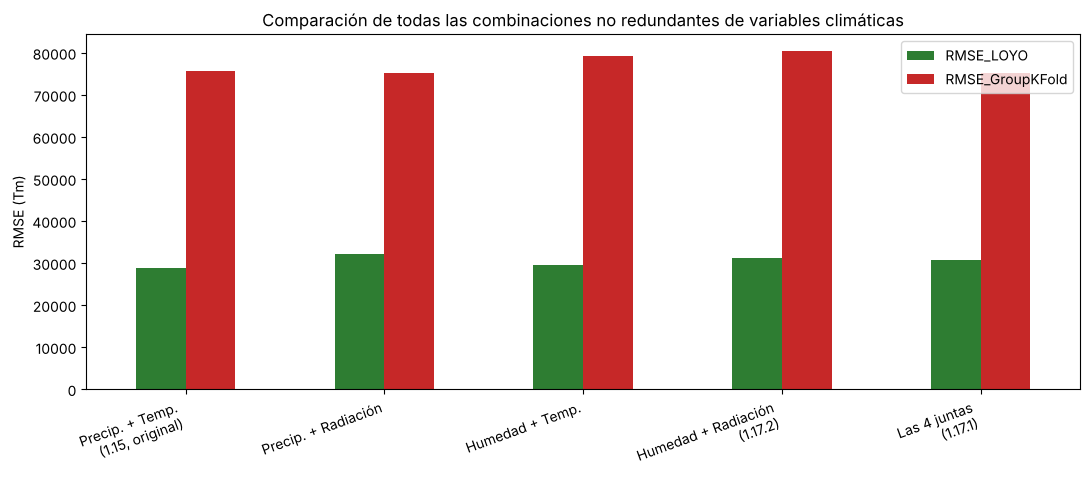

In [39]:
# Tabla comparativa con las 5 combinaciones: las 3 "cruzadas" nuevas de esta celda, más las 2 ya
# calculadas en pasos anteriores (no se vuelven a correr, se reutilizan sus resultados).
comparacion_combinaciones = pd.DataFrame({
    "Precip. + Temp.\n(1.15, original)": {
        "RMSE_LOYO": resultados_grid_corregido.iloc[0]["rmse_loyo"],
        "RMSE_GroupKFold": resultados_grid_corregido.iloc[0]["rmse_group_kfold"],
    },
    "Precip. + Radiación": {
        "RMSE_LOYO": resultados_grid_precip_radiacion.iloc[0]["rmse_loyo"],
        "RMSE_GroupKFold": resultados_grid_precip_radiacion.iloc[0]["rmse_group_kfold"],
    },
    "Humedad + Temp.": {
        "RMSE_LOYO": resultados_grid_humedad_temp.iloc[0]["rmse_loyo"],
        "RMSE_GroupKFold": resultados_grid_humedad_temp.iloc[0]["rmse_group_kfold"],
    },
    "Humedad + Radiación\n(1.17.2)": {
        "RMSE_LOYO": resultados_grid_reemplazo.iloc[0]["rmse_loyo"],
        "RMSE_GroupKFold": resultados_grid_reemplazo.iloc[0]["rmse_group_kfold"],
    },
    "Las 4 juntas\n(1.17.1)": {
        "RMSE_LOYO": resultados_grid_extendido.iloc[0]["rmse_loyo"],
        "RMSE_GroupKFold": resultados_grid_extendido.iloc[0]["rmse_group_kfold"],
    },
}).round(1)

print(comparacion_combinaciones)

fig, ax = plt.subplots(figsize=(11, 5))
comparacion_combinaciones.T.plot(kind="bar", ax=ax, color=["#2E7D32", "#C62828"])
ax.set_ylabel("RMSE (Tm)")
ax.set_title("Comparación de todas las combinaciones no redundantes de variables climáticas")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Resultado:** Precipitación + Temperatura es la combinación con menor RMSE en LOYO (28,914.5, la
más baja de las cinco) y también la de menor suma de ambos RMSE (104,682.8). En Group K-Fold, con
el reparto de provincias de referencia, tres combinaciones quedan prácticamente empatadas: las
cuatro juntas (75,236.2), Precipitación + Radiación (75,254.2) y Precipitación + Temperatura
(75,768.3); la diferencia entre ellas es menor al 1%. Humedad + Temperatura y Humedad + Radiación
quedan por detrás de Precipitación + Temperatura en ambos esquemas.

Para decidir qué variables climáticas usar se da prioridad a LOYO: mide la capacidad de
generalizar a un año nunca visto, que es exactamente el escenario del pronóstico 2026, mientras
que Group K-Fold mide la generalización a una provincia nunca vista, un escenario que no aplica al
pronosticar (las 23 provincias ya están en los datos históricos). Por ambas razones se mantiene
Precipitación + Temperatura como el conjunto final de variables climáticas.

## 1.17.4 — ¿Dependen estas conclusiones del reparto de provincias en Group K-Fold?

LOYO no tiene ninguna parte aleatoria: cada año se deja afuera una vez. Group K-Fold sí depende de
qué provincias quedan juntas en cada pliegue. Con solo 23 provincias, y con Los Ríos, Manabí y
Guayas concentrando la mayor parte de la producción, cambiar de pliegue una sola provincia
grande puede mover el RMSE varios miles de toneladas. Para saber si la comparación del Paso 1.17.3
es robusta, cada combinación climática (con sus mejores hiperparámetros) se evalúa con
**30 repartos distintos** de provincias (semillas 0 a 29) y se reporta la media, la desviación
estándar y cuántas veces gana cada combinación.

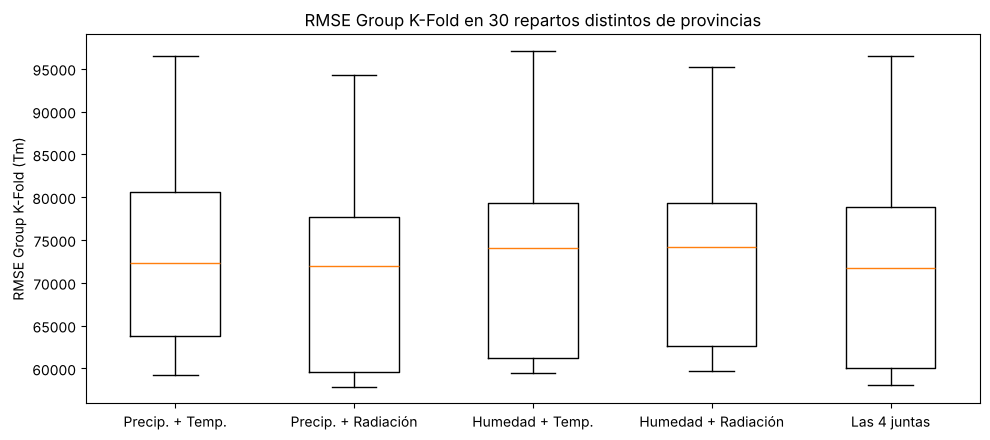

,RMSE GKF media,RMSE GKF desv. est.,RMSE GKF mín.,RMSE GKF máx.,Gana (de 30 repartos),RMSE LOYO
Combinación,,,,,,
Precip. + Temp.,74163.5,11742.5,59216.5,96532.5,5,28914.5
Precip. + Radiación,72063.4,11698.8,57872.3,94267.2,22,32224.8
Humedad + Temp.,74160.1,12133.3,59523.1,97040.9,0,29635.3
Humedad + Radiación,74104.6,11142.1,59661.4,95207.8,0,31215.3
Las 4 juntas,73030.4,12469.1,58106.4,96493.3,3,30724.3


In [40]:
CONFIGURACIONES_CLIMA = {
    "Precip. + Temp.": (columnas_predictoras, resultados_grid_corregido),
    "Precip. + Radiación": (columnas_precip_radiacion, resultados_grid_precip_radiacion),
    "Humedad + Temp.": (columnas_humedad_temp, resultados_grid_humedad_temp),
    "Humedad + Radiación": (columnas_predictoras_reemplazo, resultados_grid_reemplazo),
    "Las 4 juntas": (columnas_predictoras_extendidas, resultados_grid_extendido),
}
SEMILLAS_REPARTO = range(30)

panel_robustez = panel_corregido_extendido.copy()
panel_robustez["provincia_clave"] = panel_robustez["provincia_clave"].astype("category")
y_robustez = panel_robustez["produccion"]
grupos_robustez = panel_robustez["provincia_clave"].astype(str)

filas_robustez = []
for nombre, (columnas, resultados_grid) in CONFIGURACIONES_CLIMA.items():
    hp = mejores_hiperparametros(resultados_grid)
    for semilla in SEMILLAS_REPARTO:
        pred = prediccion_group_kfold(panel_robustez[columnas], y_robustez, grupos_robustez, hp, semilla=semilla)
        filas_robustez.append({"Combinación": nombre, "Semilla": semilla, "RMSE_GroupKFold": rmse(y_robustez, pred)})
robustez_gkf = pd.DataFrame(filas_robustez)

victorias = (robustez_gkf.loc[robustez_gkf.groupby("Semilla")["RMSE_GroupKFold"].idxmin(), "Combinación"]
             .value_counts().reindex(CONFIGURACIONES_CLIMA.keys(), fill_value=0))
tabla_robustez = robustez_gkf.groupby("Combinación")["RMSE_GroupKFold"].agg(["mean", "std", "min", "max"])
tabla_robustez = tabla_robustez.reindex(CONFIGURACIONES_CLIMA.keys())
tabla_robustez.columns = ["RMSE GKF media", "RMSE GKF desv. est.", "RMSE GKF mín.", "RMSE GKF máx."]
tabla_robustez["Gana (de 30 repartos)"] = victorias
tabla_robustez["RMSE LOYO"] = [CONFIGURACIONES_CLIMA[n][1].iloc[0]["rmse_loyo"] for n in tabla_robustez.index]
tabla_robustez = tabla_robustez.round(1)
TABLAS_PARA_DESCARGAR["Etapa1_Robustez_GroupKFold"] = tabla_robustez.reset_index()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([robustez_gkf.loc[robustez_gkf["Combinación"] == n, "RMSE_GroupKFold"] for n in CONFIGURACIONES_CLIMA])
ax.set_xticks(range(1, len(CONFIGURACIONES_CLIMA) + 1))
ax.set_xticklabels(list(CONFIGURACIONES_CLIMA.keys()))
ax.set_ylabel("RMSE Group K-Fold (Tm)")
ax.set_title("RMSE Group K-Fold en 30 repartos distintos de provincias")
plt.tight_layout()
plt.show()

tabla_robustez

**Resultado:** el RMSE Group K-Fold depende mucho del reparto de provincias. Para una misma
combinación varía entre unos 58,000 y 97,000 Tm según qué provincias queden juntas (desviación
estándar cercana a 12,000 Tm), mientras que las medias de las cinco combinaciones quedan entre
72,063 y 74,164 Tm, dentro de un rango del 3%. Precipitación + Radiación tiene la media más baja y
gana en 22 de los 30 repartos; Precipitación + Temperatura gana en 5. Es decir: en Group K-Fold
la ventaja de Precipitación + Radiación es consistente pero pequeña (unos 2,100 Tm, menos de una
quinta parte de la variación que produce el reparto), mientras que en LOYO, que no depende de
ningún reparto, Precipitación + Temperatura es 11% mejor (28,914 vs. 32,225 Tm). Se mantiene
Precipitación + Temperatura, y la conclusión queda documentada como una diferencia de
generalización por año frente a generalización por provincia, no como una superioridad absoluta.

## 1.18 — Importancia de las variables (gain)

XGBoost puede reportar cuánto contribuyó cada variable a mejorar las predicciones dentro de sus
árboles. Este número **no debe interpretarse como una medida absoluta de importancia** (depende
de cómo se construyeron los árboles, y puede subestimar variables correlacionadas entre sí) —
por eso lo complementamos con la prueba de ablación de arriba, en vez de usarlo solo.


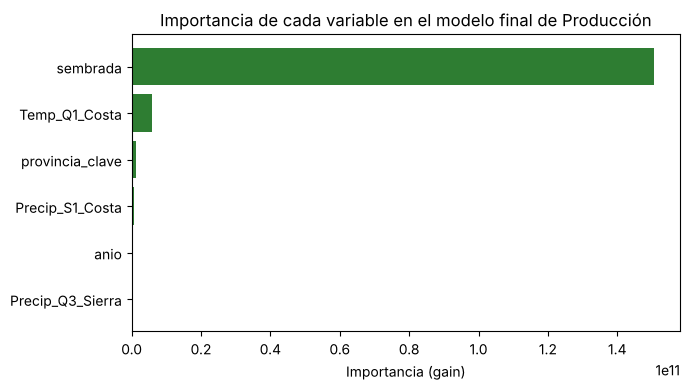

,variable,gain
0,sembrada,1.505556e+11
1,Temp_Q1_Costa,5.853535e+09
2,provincia_clave,1.311286e+09
3,Precip_S1_Costa,7.082090e+08
4,anio,4.977110e+08
5,Precip_Q3_Sierra,1.885490e+08


In [41]:
modelo_final_produccion = crear_modelo(mejores_hp)
modelo_final_produccion.fit(X_corregido, y_corregido)

importancia = modelo_final_produccion.get_booster().get_score(importance_type="gain")
importancia_df = pd.DataFrame(
    sorted(importancia.items(), key=lambda par: -par[1]), columns=["variable", "gain"]
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importancia_df["variable"], importancia_df["gain"], color="#2E7D32")
ax.invert_yaxis()
ax.set_xlabel("Importancia (gain)")
ax.set_title("Importancia de cada variable en el modelo final de Producción")
plt.tight_layout()
plt.show()

importancia_df


## 1.19 — Verificación nacional agregada, con el panel ya corregido

Se repite la verificación del Paso 1.11, ahora con los datos corregidos.


In [42]:
tabla_verificacion_corregida = panel_corregido.copy()
tabla_verificacion_corregida["prediccion"] = pred_loyo_corregido

agregado_nacional_corregido = tabla_verificacion_corregida.groupby("anio", as_index=False).agg(
    produccion_real=("produccion", "sum"),
    produccion_predicha=("prediccion", "sum"),
)
agregado_nacional_corregido["error_%"] = (
    (agregado_nacional_corregido["produccion_predicha"] - agregado_nacional_corregido["produccion_real"])
    / agregado_nacional_corregido["produccion_real"] * 100
)

r2_nacional_corregido = r2_score(agregado_nacional_corregido["produccion_real"], agregado_nacional_corregido["produccion_predicha"])
mape_nacional_corregido = agregado_nacional_corregido["error_%"].abs().mean()

print(agregado_nacional_corregido.round(1))
print(f"\nNacional agregado (LOYO) -> R²={r2_nacional_corregido:.3f}  MAPE={mape_nacional_corregido:.1f}%")


    anio  produccion_real  produccion_predicha  error_%
0   2014        1488750.2            1483293.0     -0.4
1   2015        1802951.3            1613610.9    -10.5
2   2016        1108749.8            1216351.9      9.7
3   2017        1437637.7            1444079.3      0.4
4   2018        1324083.7            1521176.3     14.9
5   2019        1479769.9            1314545.8    -11.2
6   2020        1304884.4            1423877.2      9.1
7   2021        1699369.6            1408148.5    -17.1
8   2022        1641131.2            1454399.1    -11.4
9   2023        1413382.2            1544344.9      9.3
10  2024        1195203.5             968156.5    -19.0
11  2025        1508853.8            1239312.1    -17.9

Nacional agregado (LOYO) -> R²=0.134  MAPE=10.9%


**Lectura:** a nivel nacional, el error LOYO por año va de -19.0% (2024) a +14.9% (2018), con un
MAPE de 10.9%. El R² nacional (0.134) es bajo porque la producción nacional varía poco de un año a
otro (entre 1.1 y 1.8 millones de Tm) y el modelo explica solo una parte de esa variación
interanual. El modelo distingue muy bien entre provincias, pero predice con menos precisión cuánto
sube o baja el total del país en un año dado. Para el pronóstico 2026 esto significa un error típico
del orden del 11% sobre el total nacional.

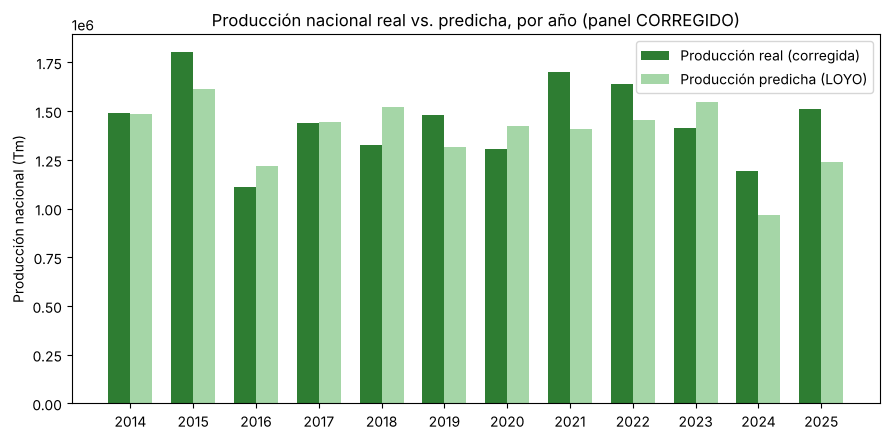

In [43]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ancho = 0.35
posiciones = range(len(agregado_nacional_corregido))
ax.bar([p - ancho/2 for p in posiciones], agregado_nacional_corregido["produccion_real"],
       width=ancho, label="Producción real (corregida)", color="#2E7D32")
ax.bar([p + ancho/2 for p in posiciones], agregado_nacional_corregido["produccion_predicha"],
       width=ancho, label="Producción predicha (LOYO)", color="#A5D6A7")
ax.set_xticks(list(posiciones))
ax.set_xticklabels(agregado_nacional_corregido["anio"])
ax.set_ylabel("Producción nacional (Tm)")
ax.set_title("Producción nacional real vs. predicha, por año (panel CORREGIDO)")
ax.legend()
plt.tight_layout()
plt.show()


## 1.20 — Pronóstico de Producción para 2026

Entrenamos el modelo final con **todos** los años disponibles (ya no es validación cruzada — es
el modelo que efectivamente se usaría para pronosticar el futuro), y lo aplicamos a las
variables de 2026 que ya trae preparadas el archivo de insumos: superficie sembrada estimada
como el promedio de los últimos 3 años, clima de enero-junio real, y julio-septiembre estimado
con el promedio histórico de esa misma variable (porque ese trimestre del año todavía no ha
ocurrido al momento de pronosticar).


In [44]:
provincias_info = panel_corregido[["provincia", "provincia_clave", "region"]].drop_duplicates().reset_index(drop=True)

# Temp_Q1_Costa 2026 y Precip_S1_Costa 2026: datos REALES (el archivo de clima ya incluye
# enero-junio de 2026, según lo que hayamos descargado de Copernicus).
temp_q1_2026 = promedio_meses(tabla_clima, [1, 2, 3], "Temperatura (°C)").reset_index()
temp_q1_2026 = temp_q1_2026[temp_q1_2026["Año"] == 2026][["provincia_clave", "Temperatura (°C)"]]
temp_q1_2026 = temp_q1_2026.rename(columns={"Temperatura (°C)": "temp_q1_2026"})

precip_s1_2026 = suma_meses(tabla_clima, [1, 2, 3, 4, 5, 6], "Precipitación (mm/mes)").reset_index()
precip_s1_2026 = precip_s1_2026[precip_s1_2026["Año"] == 2026][["provincia_clave", "Precipitación (mm/mes)"]]
precip_s1_2026 = precip_s1_2026.rename(columns={"Precipitación (mm/mes)": "precip_s1_2026"})

# Precip_Q3_Sierra 2026: julio-septiembre de 2026 todavía no existe en los datos climáticos;
# se estima con el promedio histórico 2014-2025 de esa misma variable, por provincia.
precip_q3_historico = suma_meses(tabla_clima[tabla_clima["Año"] <= 2025], [7, 8, 9], "Precipitación (mm/mes)").reset_index()
precip_q3_promedio = precip_q3_historico.groupby("provincia_clave")["Precipitación (mm/mes)"].mean().reset_index()
precip_q3_promedio = precip_q3_promedio.rename(columns={"Precipitación (mm/mes)": "precip_q3_promedio"})

# Superficie sembrada 2026: promedio de los últimos 3 años disponibles (2023-2025).
sembrada_promedio = (
    panel_corregido[panel_corregido["anio"].isin([2023, 2024, 2025])]
    .groupby("provincia_clave")["sembrada"].mean().reset_index()
    .rename(columns={"sembrada": "sembrada_promedio"})
)

pronostico_2026_features = provincias_info.merge(temp_q1_2026, on="provincia_clave", how="left")
pronostico_2026_features = pronostico_2026_features.merge(precip_s1_2026, on="provincia_clave", how="left")
pronostico_2026_features = pronostico_2026_features.merge(precip_q3_promedio, on="provincia_clave", how="left")
pronostico_2026_features = pronostico_2026_features.merge(sembrada_promedio, on="provincia_clave", how="left")

pronostico_2026_features["anio"] = 2026
pronostico_2026_features["sembrada"] = pronostico_2026_features["sembrada_promedio"]
pronostico_2026_features["Precip_S1_Costa"] = np.where(pronostico_2026_features["region"] == "Costa", pronostico_2026_features["precip_s1_2026"], 0.0)
pronostico_2026_features["Precip_Q3_Sierra"] = np.where(pronostico_2026_features["region"] == "Sierra", pronostico_2026_features["precip_q3_promedio"], 0.0)
pronostico_2026_features["Temp_Q1_Costa"] = np.where(pronostico_2026_features["region"] == "Costa", pronostico_2026_features["temp_q1_2026"], 0.0)

pronostico_2026_features["provincia_clave"] = pd.Categorical(
    pronostico_2026_features["provincia_clave"], categories=panel_corregido["provincia_clave"].cat.categories
)

produccion_2026_por_provincia = pronostico_2026_features.copy()
produccion_2026_por_provincia["produccion_estimada_2026"] = modelo_final_produccion.predict(
    pronostico_2026_features[columnas_predictoras]
)
produccion_2026_estimada = produccion_2026_por_provincia["produccion_estimada_2026"].sum()

print(f"Producción nacional estimada para 2026: {produccion_2026_estimada:,.0f} Tm")


Producción nacional estimada para 2026: 1,493,945 Tm


## Resumen de la Etapa 1

La Etapa 1 se extrae y calcula de principio a fin desde los archivos crudos. Pasan al resto del
notebook dos resultados: `panel_corregido` (con la predicción LOYO por provincia y año, insumo de
la Etapa 3) y `produccion_2026_estimada` (1,493,945 Tm).

In [45]:
TABLAS_PARA_DESCARGAR["Etapa1_Panel_Corregido"] = panel_corregido.assign(
    provincia_clave=panel_corregido["provincia_clave"].astype(str)
)
TABLAS_PARA_DESCARGAR["Etapa1_Comparacion_Hiperparametros"] = resultados_grid_corregido.head(20)
TABLAS_PARA_DESCARGAR["Etapa1_Metricas_Modelo"] = metricas_etapa1.reset_index().rename(columns={"index": "Métrica"})
TABLAS_PARA_DESCARGAR["Etapa1_Verificacion_Nacional"] = agregado_nacional_corregido
TABLAS_PARA_DESCARGAR["Etapa1_Importancia_Variables"] = importancia_df
TABLAS_PARA_DESCARGAR["Etapa1_Pronostico_2026"] = produccion_2026_por_provincia[
    ["provincia", "region", "sembrada", "Precip_S1_Costa", "Precip_Q3_Sierra", "Temp_Q1_Costa", "produccion_estimada_2026"]
]

produccion_nacional_loyo = panel_corregido.groupby("anio")["prediccion_loyo"].sum().rename("Produccion_LOYO_TM")
produccion_nacional_real = panel_corregido.groupby("anio")["produccion"].sum().rename("Produccion_Real_TM")

print("Etapa 1 completa. Avanzamos a los insumos de comercio exterior.")


Etapa 1 completa. Avanzamos a los insumos de comercio exterior.


# Parte 2 — Insumos compartidos: Importaciones (BCE) y Precio internacional

Tanto la Etapa 2 (para el "cálculo propio" de la Demanda) como la Etapa 3 necesitan la misma
serie de Importaciones reales del BCE, y la Etapa 3 además necesita el Precio internacional. Los
preparamos una sola vez aquí, leyendo directamente los archivos de `datos/`, y de ahí en adelante todas las
etapas siguientes los usan desde la memoria del notebook.


## Insumo A — Importaciones reales del BCE (filtradas a Maíz Amarillo)

El archivo que exporta la página del BCE trae unas filas de encabezado antes de la tabla real, y
mezcla todas las subpartidas de maíz. Nos quedamos solo con el código arancelario
**1005901100** ("Amarillo"), que es la subpartida específica del maíz duro amarillo.


In [46]:
bce_crudo = pd.read_excel(f"{RUTA_BCE}/{ARCHIVO_BCE}", header=6)
bce_crudo = bce_crudo.iloc[:, 1:]
bce_crudo.columns = [str(c).strip() for c in bce_crudo.columns]
bce_crudo["Código Subpartida"] = bce_crudo["Código Subpartida"].astype(str).str.strip()

CODIGO_ARANCELARIO_AMARILLO = "1005901100"
bce_amarillo = bce_crudo[bce_crudo["Código Subpartida"] == CODIGO_ARANCELARIO_AMARILLO].copy()
bce_amarillo["Año"] = bce_amarillo["Período"].str.extract(r"(\d{4})").astype(int)

bce_anual = bce_amarillo.groupby("Año", as_index=False).agg(
    **{"TM (Peso Neto)": ("TM (Peso Neto)", "sum"), "FOB": ("FOB", "sum"), "CIF": ("CIF", "sum")}
).round(2)

bce_anual_historico = bce_anual[bce_anual["Año"] <= 2025].copy()   # 2026 queda incompleto en la fuente

print(f"Importaciones de maíz Amarillo, {bce_anual['Año'].min()}-{bce_anual['Año'].max()}:")
bce_anual


Importaciones de maíz Amarillo, 2014-2026:


,Año,TM (Peso Neto),FOB,CIF
0,2014,113655.65,23931.21,28728.73
1,2015,32953.83,5920.50,7278.74
2,2016,63397.82,11235.50,12794.22
3,2017,78578.21,13739.37,16283.57
4,2018,57309.19,9174.24,10989.68
5,2019,27584.53,4984.72,5789.71
6,2020,49255.04,9096.71,10798.50
7,2021,57199.92,12113.00,15109.17
8,2022,180629.67,48890.82,63639.98
9,2023,172416.14,50958.72,59164.66


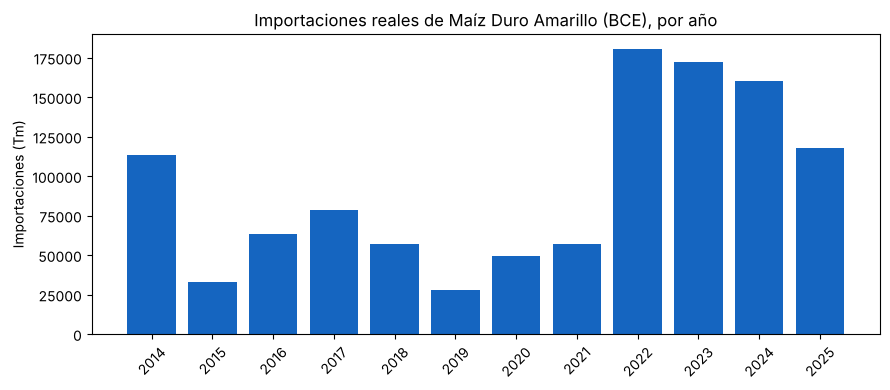

In [47]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(bce_anual_historico["Año"].astype(str), bce_anual_historico["TM (Peso Neto)"], color="#1565C0")
ax.set_ylabel("Importaciones (Tm)"); ax.set_title("Importaciones reales de Maíz Duro Amarillo (BCE), por año")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()


## Insumo B — Precio internacional del maíz (FMI vía FRED)


In [48]:
precio_crudo = pd.read_excel(f"{RUTA_FRED}/{ARCHIVO_PRECIO}", sheet_name="Annual")
precio_crudo["Año"] = pd.to_datetime(precio_crudo["observation_date"]).dt.year
precio_internacional = precio_crudo[["Año", "PMAIZMTUSDA"]].rename(columns={"PMAIZMTUSDA": "Precio_Internacional_USD_Tm"})
precio_internacional["Precio_Internacional_USD_Tm"] = precio_internacional["Precio_Internacional_USD_Tm"].round(2)

print(f"Precio internacional, {precio_internacional['Año'].min()}-{precio_internacional['Año'].max()}:")
precio_internacional.tail(12)


Precio internacional, 1992-2025:


,Año,Precio_Internacional_USD_Tm
22,2014,192.94
23,2015,169.84
24,2016,159.22
25,2017,154.60
26,2018,164.51
27,2019,170.17
28,2020,165.58
29,2021,259.39
30,2022,318.36
31,2023,251.46


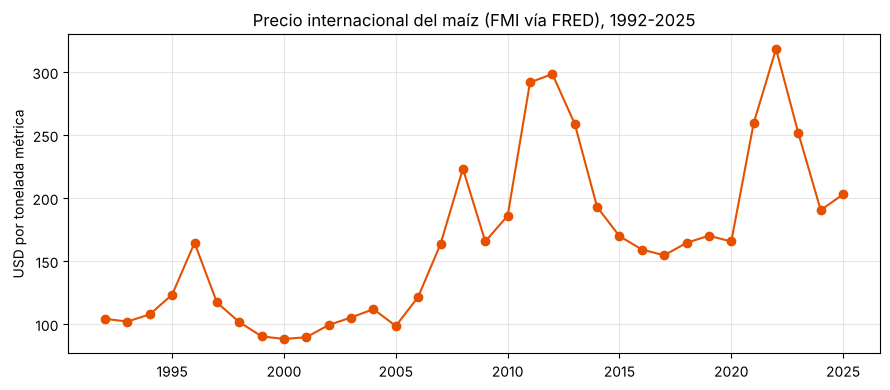

Insumos transversales listos.


In [49]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(precio_internacional["Año"], precio_internacional["Precio_Internacional_USD_Tm"], marker="o", color="#E65100")
ax.set_ylabel("USD por tonelada métrica"); ax.set_title("Precio internacional del maíz (FMI vía FRED), 1992-2025")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

TABLAS_PARA_DESCARGAR["Insumos_BCE_Maiz_Amarillo_Anual"] = bce_anual
TABLAS_PARA_DESCARGAR["Insumos_Precio_Internacional_Anual"] = precio_internacional
print("Insumos transversales listos.")


# Parte 3 — Etapa 2: Demanda Nacional

## Objetivo de esta etapa

Estimar cuánto maíz duro amarillo consume Ecuador cada año. A diferencia de la Producción
(Etapa 1), aquí no se entrena un modelo de Machine Learning complejo: se construyen y comparan
**tres series de Demanda** desde fuentes independientes, se prueban varios métodos de pronóstico
de series de tiempo, y se elige el método más simple que sea consistentemente confiable.

## Fuentes evaluadas

| Fuente | Qué aporta | Resultado de la evaluación |
|---|---|---|
| **USDA-PSD** (API oficial) | Balance oferta-demanda completo, por año agrícola | Fuente principal (descarga de la API oficial) |
| **Cálculo propio**: Producción(ESPAC) + Importaciones(BCE) | Una aproximación construida con fuentes nacionales | Su correlación con USDA depende directamente de la calidad de la Producción de la Etapa 1 (lo verificamos más abajo) |
| **FAOSTAT** | Producción y Oferta Doméstica | Producción coincide con ESPAC en 2018-2023 (diferencias < 0.03%); difiere en 2014-2015 (Paso 1.12) |


## 2.1 — Demanda oficial: balance USDA-PSD

Se consulta el sistema PSD (Production, Supply and Distribution) del USDA-FAS para el maíz (código
`0440000`) en Ecuador (`EC`). La clave de la API se lee de la variable de entorno `USDA_API_KEY`
(o del secreto `USDA_API_KEY` en Colab) y nunca se escribe en el notebook. Si no hay clave o no
hay conexión, se usa la copia local `datos/USDA/usda_psd_maiz_ecuador.csv`, que es la última
descarga de la API.

In [50]:
API_KEY = os.environ.get("USDA_API_KEY", "")
if not API_KEY and EN_COLAB:
    try:
        from google.colab import userdata
        API_KEY = userdata.get("USDA_API_KEY") or ""
    except Exception:
        API_KEY = ""

HEADERS = {"Accept": "application/json", "X-Api-Key": API_KEY}
BASE_URL = "https://api.fas.usda.gov/api/psd/commodity/0440000/country/EC/year/{}"

MAPEO = {
    20: "Beginning_Stocks_MT", 28: "Production_MT", 57: "Imports_MT", 88: "Exports_MT",
    86: "Total_Supply_MT", 130: "Feed_Residual_MT", 192: "FSI_Consumption_MT",
    125: "Total_Consumption_MT", 176: "Ending_Stocks_MT", 178: "Total_Distribution_MT",
    4: "Area_Harvested_1000HA", 184: "Yield_MT_HA",
}

registros_crudos = []
if API_KEY:
    try:
        for anio in range(2015, 2026):   # marketYear que termina entre 2015 y 2025 (=> MY 2014/15 a 2024/25)
            r = requests.get(BASE_URL.format(anio), headers=HEADERS, timeout=20)
            if r.status_code == 200:
                registros_crudos.extend(r.json())
            else:
                print(f"  AVISO: falló el año {anio} -> código {r.status_code}")
            time.sleep(0.3)
        print(f"Descarga en vivo completada: {len(registros_crudos)} registros crudos.")
    except requests.exceptions.RequestException as error:
        registros_crudos = []
        print(f"No se pudo consultar la API del USDA ({type(error).__name__}); se usará la copia local.")
else:
    print("Sin USDA_API_KEY: se usará la copia local del balance USDA-PSD.")

Sin USDA_API_KEY: se usará la copia local del balance USDA-PSD.


In [51]:
if registros_crudos:
    # Pasamos de "formato largo" (una fila por variable y año) a "formato ancho" (una fila por año).
    filas = {}
    for reg in registros_crudos:
        my_num = int(reg["marketYear"])
        my_label = f"{my_num - 1}/{str(my_num)[2:]}"
        attr = reg["attributeId"]
        if attr not in MAPEO:
            continue
        if my_label not in filas:
            filas[my_label] = {"MY": my_label, "MY_Start_Year": my_num - 1, "MY_End_Year": my_num}
        filas[my_label][MAPEO[attr]] = reg["value"]

    df_ancho = pd.DataFrame(list(filas.values())).sort_values("MY_Start_Year").reset_index(drop=True)

    NOMBRES_FINALES = {
        "MY": "Año Agrícola (MY)", "MY_Start_Year": "Año Calendario Inicio", "MY_End_Year": "Año Calendario Fin",
        "Beginning_Stocks_MT": "Existencias Iniciales (TM)", "Production_MT": "Producción (TM)",
        "Imports_MT": "Importaciones (TM)", "Exports_MT": "Exportaciones (TM)", "Total_Supply_MT": "Oferta Total (TM)",
        "Feed_Residual_MT": "Uso Forraje y Residual (TM)", "FSI_Consumption_MT": "Consumo FSI (TM)",
        "Total_Consumption_MT": "Consumo Total (TM) - Demanda", "Ending_Stocks_MT": "Existencias Finales (TM)",
        "Total_Distribution_MT": "Distribución Total (TM)", "Area_Harvested_1000HA": "Superficie Cosechada (miles Ha)",
        "Yield_MT_HA": "Rendimiento (TM/Ha)",
    }
    usda = df_ancho.rename(columns=NOMBRES_FINALES)

    # El USDA reporta en miles de toneladas; convertimos a toneladas (excepto superficie y rendimiento).
    columnas_a_convertir = ["Existencias Iniciales (TM)", "Producción (TM)", "Importaciones (TM)", "Exportaciones (TM)",
                             "Oferta Total (TM)", "Uso Forraje y Residual (TM)", "Consumo FSI (TM)",
                             "Consumo Total (TM) - Demanda", "Existencias Finales (TM)", "Distribución Total (TM)"]
    for columna in columnas_a_convertir:
        usda[columna] = usda[columna] * 1000

    usda = usda.sort_values("Año Calendario Inicio").reset_index(drop=True)
    os.makedirs(os.path.dirname(RUTA_USDA_LOCAL), exist_ok=True)
    usda.to_csv(RUTA_USDA_LOCAL, index=False)
    print(f"Balance USDA-PSD descargado en vivo y guardado en {RUTA_USDA_LOCAL}")
else:
    usda = pd.read_csv(RUTA_USDA_LOCAL)
    print(f"Balance USDA-PSD leído de la copia local: {RUTA_USDA_LOCAL}")

print(f"Balance USDA-PSD: {usda.shape[0]} años agrícolas.")
usda[["Año Agrícola (MY)", "Año Calendario Fin", "Producción (TM)", "Importaciones (TM)",
      "Exportaciones (TM)", "Consumo Total (TM) - Demanda"]]

Balance USDA-PSD leído de la copia local: datos/USDA/usda_psd_maiz_ecuador.csv
Balance USDA-PSD: 11 años agrícolas.


,Año Agrícola (MY),Año Calendario Fin,Producción (TM),Importaciones (TM),Exportaciones (TM),Consumo Total (TM) - Demanda
0,2014/15,2015,1760000,13000,0,1740000
1,2015/16,2016,1091000,158000,0,1385000
2,2016/17,2017,1436000,69000,0,1480000
3,2017/18,2018,1324000,43000,0,1380000
4,2018/19,2019,1480000,59000,5000,1485000
5,2019/20,2020,1305000,73000,0,1435000
6,2020/21,2021,1699000,197000,5000,1875000
7,2021/22,2022,1641000,188000,0,1785000
8,2022/23,2023,1413000,118000,0,1585000
9,2023/24,2024,1195000,191000,0,1355000


## 2.2 — "Cálculo propio": Producción(ESPAC) + Importaciones(BCE)

Definimos esta serie alternativa como una identidad simplificada:

```
Cálculo propio = Producción (ESPAC) + Importaciones (BCE) − Exportaciones ± Variación de Stock
```

Como no existe una fuente separada de Exportaciones ni de Variación de Stock específica para el
maíz amarillo ecuatoriano, esos dos términos se asumen aproximadamente cero (Ecuador exporta
cantidades mínimas de este grano).

**Aquí es donde se ve la conexión entre etapas**: usamos directamente `produccion_nacional_real`
(la producción real ya corregida en la Parte 1) y `bce_anual_historico` (que
preparamos en la Parte 2) — sin leer ningún archivo intermedio de nuevo.


In [52]:
calculo_propio = pd.DataFrame({
    "Año": produccion_nacional_real.index,
    "Produccion_ESPAC_TM": produccion_nacional_real.values,
}).merge(
    bce_anual_historico[["Año", "TM (Peso Neto)"]].rename(columns={"TM (Peso Neto)": "Importaciones_BCE_TM"}),
    on="Año",
)
calculo_propio["Demanda_Calculo_Propio_TM"] = (
    calculo_propio["Produccion_ESPAC_TM"] + calculo_propio["Importaciones_BCE_TM"]
)

calculo_propio


,Año,Produccion_ESPAC_TM,Importaciones_BCE_TM,Demanda_Calculo_Propio_TM
0,2014,1.488750e+06,113655.65,1.602406e+06
1,2015,1.802951e+06,32953.83,1.835905e+06
2,2016,1.108750e+06,63397.82,1.172148e+06
3,2017,1.437638e+06,78578.21,1.516216e+06
4,2018,1.324084e+06,57309.19,1.381393e+06
5,2019,1.479770e+06,27584.53,1.507354e+06
6,2020,1.304884e+06,49255.04,1.354139e+06
7,2021,1.699370e+06,57199.92,1.756570e+06
8,2022,1.641131e+06,180629.67,1.821761e+06
9,2023,1.413382e+06,172416.14,1.585798e+06


## 2.3 — FAOSTAT, como tercera fuente real (no como sustituto)

Reutilizamos aquí el archivo de FAOSTAT que ya cargamos en el Paso 1.12 (como `fao_ancho`) para
validar la anomalía de 2016-2017, tomando la variable `"Domestic supply quantity"` (Oferta
Doméstica) como la tercera serie de Demanda genuina — sin tener que releer ningún archivo.


In [53]:
demanda_faostat = fao_ancho[["Año", "Domestic supply quantity"]].rename(
    columns={"Domestic supply quantity": "Demanda_FAOSTAT_TM"}
)
print(f"Demanda FAOSTAT (Oferta Doméstica): {len(demanda_faostat)} años ({demanda_faostat['Año'].min()}-{demanda_faostat['Año'].max()})")
demanda_faostat


Demanda FAOSTAT (Oferta Doméstica): 10 años (2014-2023)


Element,Año,Demanda_FAOSTAT_TM
0,2014,1820000.0
1,2015,1900000.0
2,2016,1318000.0
3,2017,1516000.0
4,2018,1435000.0
5,2019,1476000.0
6,2020,1463000.0
7,2021,1784000.0
8,2022,1827000.0
9,2023,1687000.0


In [54]:
# Armamos la tabla de las TRES fuentes de Demanda, alineadas por año calendario.
# USDA reporta en Año Agrícola (Marketing Year); "Año Calendario Fin" es el año calendario
# equivalente — la forma correcta de comparar esta serie con ESPAC y FAOSTAT, que sí usan
# año calendario.
demanda_usda = usda[["Año Calendario Fin", "Consumo Total (TM) - Demanda"]].rename(
    columns={"Año Calendario Fin": "Año", "Consumo Total (TM) - Demanda": "Demanda_USDA_PSD"}
)

tabla_tres_fuentes = (
    demanda_usda
    .merge(calculo_propio[["Año", "Demanda_Calculo_Propio_TM"]], on="Año", how="outer")
    .merge(demanda_faostat, on="Año", how="outer")
    .sort_values("Año").reset_index(drop=True)
)
tabla_tres_fuentes


,Año,Demanda_USDA_PSD,Demanda_Calculo_Propio_TM,Demanda_FAOSTAT_TM
0,2014,NaN,1.602406e+06,1820000.0
1,2015,1740000.0,1.835905e+06,1900000.0
2,2016,1385000.0,1.172148e+06,1318000.0
3,2017,1480000.0,1.516216e+06,1516000.0
4,2018,1380000.0,1.381393e+06,1435000.0
5,2019,1485000.0,1.507354e+06,1476000.0
6,2020,1435000.0,1.354139e+06,1463000.0
7,2021,1875000.0,1.756570e+06,1784000.0
8,2022,1785000.0,1.821761e+06,1827000.0
9,2023,1585000.0,1.585798e+06,1687000.0


In [55]:
# Correlación entre "cálculo propio" y la Demanda oficial de USDA, en los años donde ambas existen.
comparables = tabla_tres_fuentes.dropna(subset=["Demanda_USDA_PSD", "Demanda_Calculo_Propio_TM"])
correlacion_calculo_propio = comparables[["Demanda_USDA_PSD", "Demanda_Calculo_Propio_TM"]].corr().iloc[0, 1]

# Y, ya que la tenemos real, también la correlación de FAOSTAT contra USDA.
comparables_fao = tabla_tres_fuentes.dropna(subset=["Demanda_USDA_PSD", "Demanda_FAOSTAT_TM"])
correlacion_faostat = comparables_fao[["Demanda_USDA_PSD", "Demanda_FAOSTAT_TM"]].corr().iloc[0, 1]

print(f"Correlación 'Cálculo propio' (ESPAC corregido + BCE) vs. USDA-PSD: {correlacion_calculo_propio:.3f}")
print(f"Correlación FAOSTAT (Oferta Doméstica) vs. USDA-PSD:              {correlacion_faostat:.3f}")
print()
print("Una correlación alta es coherente con que la Producción corregida en la Parte 1 sea consistente")
print("con el balance del USDA-PSD. No es una prueba totalmente independiente: el USDA también parte")
print("de las cifras oficiales del país, como muestra su Producción 2016-2017 (1,091,000 y 1,436,000 Tm).")


Correlación 'Cálculo propio' (ESPAC corregido + BCE) vs. USDA-PSD: 0.915
Correlación FAOSTAT (Oferta Doméstica) vs. USDA-PSD:              0.924

Una correlación alta es coherente con que la Producción corregida en la Parte 1 sea consistente
con el balance del USDA-PSD. No es una prueba totalmente independiente: el USDA también parte
de las cifras oficiales del país, como muestra su Producción 2016-2017 (1,091,000 y 1,436,000 Tm).


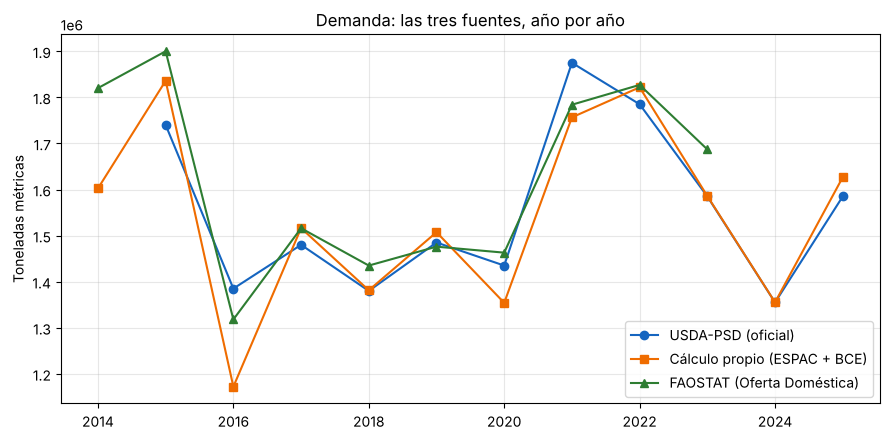

In [56]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(tabla_tres_fuentes["Año"], tabla_tres_fuentes["Demanda_USDA_PSD"], marker="o", label="USDA-PSD (oficial)", color="#1565C0")
ax.plot(tabla_tres_fuentes["Año"], tabla_tres_fuentes["Demanda_Calculo_Propio_TM"], marker="s", label="Cálculo propio (ESPAC + BCE)", color="#EF6C00")
ax.plot(tabla_tres_fuentes["Año"], tabla_tres_fuentes["Demanda_FAOSTAT_TM"], marker="^", label="FAOSTAT (Oferta Doméstica)", color="#2E7D32")
ax.set_ylabel("Toneladas métricas")
ax.set_title("Demanda: las tres fuentes, año por año")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

TABLAS_PARA_DESCARGAR["Etapa2_Tres_Fuentes_Demanda"] = tabla_tres_fuentes


## 2.4 — Comparación de métodos de pronóstico

Con series de solo 10-12 datos, conviene probar varios métodos —desde el más simple hasta
algunos más sofisticados— y comparar su error con validación cruzada **Leave-One-Out**: por cada
año, se esconde ese año, se entrena con los demás, y se compara la predicción contra el valor
real escondido.

**Una aclaración honesta:** para los métodos que dependen del orden temporal (Random Walk,
AR(1), Holt, Auto-ARIMA), al esconder un año que no es el último, "cerramos el hueco" (los años
restantes quedan como una secuencia continua) y le pedimos al método predecir "un paso más allá"
de esa secuencia recortada. Es una simplificación práctica y común para series muy cortas, pero
distinta de "esconder solo el último año" — hay que tenerlo presente al interpretar los números
absolutos de esta comparación.

**Nota sobre un sexto método posible (XGBoost con Población+PIB+Pollos+Huevos):** no se incluye
aquí porque requiere series adicionales (Banco Mundial, BCE, CONAVE) que no forman parte de los 4
archivos de entrada de este notebook. Con más de 4 predictores y apenas 9-12 observaciones
anuales, un modelo de este tipo tiene muy pocos grados de libertad para generalizar y tiende a
sobreajustar severamente — descartarlo por esta razón, antes incluso de probarlo, es una decisión
de criterio técnico razonable dado el tamaño de la muestra.


In [57]:
def pred_promedio_historico(train_vals, train_t, t_objetivo):
    # El pronóstico "naive": el promedio de todos los años que sí conoce. No le importa el
    # orden ni la posición del año a predecir — es la referencia contra la que se comparan
    # todos los demás métodos.
    return np.mean(train_vals)

def pred_random_walk(train_vals, train_t, t_objetivo):
    # Persistencia ("mañana va a ser igual que hoy"): predice el último valor de la
    # secuencia de entrenamiento, después de cerrar el hueco del año escondido.
    return train_vals[-1]

def pred_regresion_lineal(train_vals, train_t, t_objetivo):
    # Ajusta una línea recta (Demanda = a + b × año). Es el único método de esta lista que
    # sí respeta la posición REAL del año escondido (no necesita "cerrar el hueco").
    X = np.array(train_t).reshape(-1, 1)
    y = np.array(train_vals)
    modelo = LinearRegression().fit(X, y)
    return modelo.predict([[t_objetivo]])[0]

def pred_ar1(train_vals, train_t, t_objetivo):
    # AR(1): el valor de este año depende linealmente del valor del año anterior (lags=1).
    modelo = AutoReg(np.array(train_vals, dtype=float), lags=1).fit()
    return modelo.forecast(1)[0]

def pred_holt(train_vals, train_t, t_objetivo):
    # Suavizado exponencial doble: combina un "nivel" y una "tendencia", ambos suavizados.
    modelo = Holt(np.array(train_vals, dtype=float), initialization_method="estimated").fit()
    return modelo.forecast(1)[0]

def pred_auto_arima(train_vals, train_t, t_objetivo):
    # Prueba automáticamente varias combinaciones ARIMA y elige la de mejor ajuste (criterio AIC).
    modelo = pm.auto_arima(np.array(train_vals, dtype=float), seasonal=False,
                            suppress_warnings=True, error_action="ignore")
    pronostico = modelo.predict(n_periods=1)
    return pronostico.iloc[0] if hasattr(pronostico, "iloc") else pronostico[0]

METODOS_DEMANDA = {
    "Promedio histórico": pred_promedio_historico,
    "Random Walk": pred_random_walk,
    "Regresión lineal": pred_regresion_lineal,
    "AR(1)": pred_ar1,
    "Holt": pred_holt,
    "Auto-ARIMA": pred_auto_arima,
}

def evaluar_metodo_loocv(valores, anios, funcion_prediccion):
    '''Corre Leave-One-Out sobre una serie: por cada año, lo esconde, predice con el resto,
    y guarda el error. Al final devuelve el RMSE de todos los años.'''
    errores = []
    for i in range(len(valores)):
        train_vals = [v for j, v in enumerate(valores) if j != i]
        train_t = [t for j, t in enumerate(anios) if j != i]
        try:
            prediccion = funcion_prediccion(train_vals, train_t, anios[i])
        except Exception:
            prediccion = np.nan   # si un método falla en un año puntual, no se detiene todo el proceso
        errores.append(valores[i] - prediccion)
    errores = np.array(errores, dtype=float)
    return np.sqrt(np.nanmean(errores ** 2))

print("Métodos y función de evaluación definidos.")


Métodos y función de evaluación definidos.


In [58]:
series_demanda = {
    "USDA-PSD": comparables[["Año", "Demanda_USDA_PSD"]].rename(columns={"Demanda_USDA_PSD": "valor"}),
    "Cálculo Propio": comparables[["Año", "Demanda_Calculo_Propio_TM"]].rename(columns={"Demanda_Calculo_Propio_TM": "valor"}),
    "FAOSTAT": comparables_fao[["Año", "Demanda_FAOSTAT_TM"]].rename(columns={"Demanda_FAOSTAT_TM": "valor"}),
}

resultados_comparacion_demanda = {}
for nombre_serie, tabla in series_demanda.items():
    valores = tabla["valor"].tolist()
    anios = tabla["Año"].tolist()
    fila = {nombre_metodo: evaluar_metodo_loocv(valores, anios, funcion) for nombre_metodo, funcion in METODOS_DEMANDA.items()}
    resultados_comparacion_demanda[nombre_serie] = fila

tabla_comparacion_demanda = pd.DataFrame(resultados_comparacion_demanda).round(0)
tabla_comparacion_demanda


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


,USDA-PSD,Cálculo Propio,FAOSTAT
Promedio histórico,186368.0,223521.0,215715.0
Random Walk,185736.0,236517.0,215402.0
Regresión lineal,206209.0,259513.0,264243.0
AR(1),190633.0,231486.0,208094.0
Holt,192925.0,216858.0,234848.0
Auto-ARIMA,186368.0,235051.0,208104.0


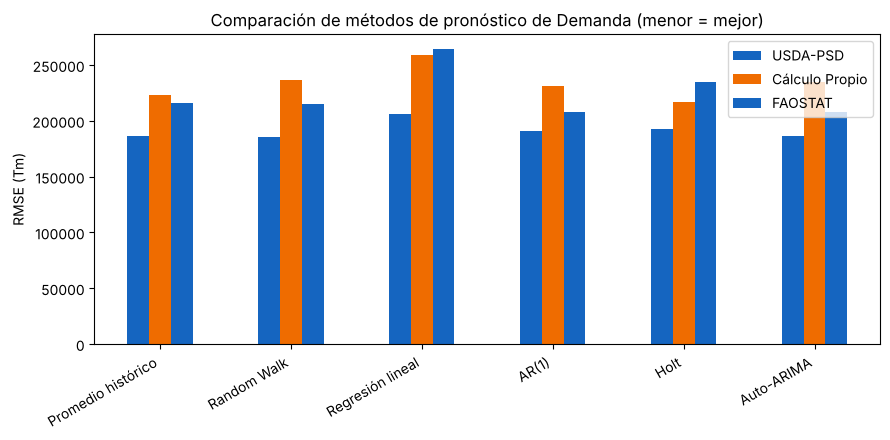

Método con menor RMSE (mejor) en cada serie:
USDA-PSD          Random Walk
Cálculo Propio           Holt
FAOSTAT                 AR(1)
dtype: str


In [59]:
fig, ax = plt.subplots(figsize=(9, 4.5))
tabla_comparacion_demanda.plot(kind="bar", ax=ax, color=["#1565C0", "#EF6C00"])
ax.set_ylabel("RMSE (Tm)")
ax.set_title("Comparación de métodos de pronóstico de Demanda (menor = mejor)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print("Método con menor RMSE (mejor) en cada serie:")
print(tabla_comparacion_demanda.idxmin())


**Lectura:** ningún método gana en las tres series. El menor RMSE lo obtiene Random Walk en USDA-PSD
(185,736 Tm), Holt en Cálculo Propio (216,858 Tm) y AR(1) en FAOSTAT (208,094 Tm). Pero en las tres
series la ventaja sobre el promedio histórico simple es pequeña: 0.3% en USDA-PSD (frente a
186,368 Tm), 3.0% en Cálculo Propio (223,521 Tm) y 3.5% en FAOSTAT (215,715 Tm). En USDA-PSD,
Auto-ARIMA elige un modelo sin dinámica y su pronóstico es igual al promedio histórico. La
conclusión es que **ningún método de series de tiempo supera de forma consistente al promedio
histórico simple**: las diferencias son de pocos puntos porcentuales y el método ganador cambia
según la serie. Es evidencia de volatilidad estructural del mercado ecuatoriano de maíz, no una
falla de modelado.

## 2.5 — Decisión final: promedio móvil de los últimos 3 años

Como ningún método mostró, en la comparación anterior, una ventaja consistente sobre el promedio
histórico simple, se adopta un método de la familia del promedio: el **promedio de los últimos 3
años** de la Demanda oficial (USDA-PSD). Se prefiere a un promedio de toda la serie porque da más
peso a la situación reciente del mercado, y es simple y estable. Hay que precisar que el promedio
móvil de 3 años no forma parte de la comparación del Paso 2.4: es una decisión de criterio dentro
del grupo de métodos con desempeño similar, no el ganador de esa tabla.

In [60]:
usda_ordenado = comparables.sort_values("Año").reset_index(drop=True)
ultimos_3_anios = usda_ordenado.tail(3)

demanda_estimada = ultimos_3_anios["Demanda_USDA_PSD"].mean()

print("Años usados para el promedio móvil:")
print(ultimos_3_anios[["Año", "Demanda_USDA_PSD"]].to_string(index=False))
print()
print(f"DEMANDA ESTIMADA (promedio móvil de 3 años) = {demanda_estimada:,.0f} Tm")


Años usados para el promedio móvil:
 Año  Demanda_USDA_PSD
2023         1585000.0
2024         1355000.0
2025         1585000.0

DEMANDA ESTIMADA (promedio móvil de 3 años) = 1,508,333 Tm


**Nota sobre la estabilidad de este número:** la API del USDA revisa y actualiza sus cifras
periódicamente. Si este notebook se vuelve a ejecutar más adelante y el USDA ya publicó un año
agrícola adicional (o revisó alguno de los últimos 3), el promedio móvil resultante cambiará
ligeramente — es el comportamiento esperado del método, no un error de cálculo.

Si el notebook se ejecuta sin clave de la API, usa la copia local `datos/USDA/usda_psd_maiz_ecuador.csv`,
que reproduce exactamente los números publicados aquí.

## Resumen de la Etapa 2

Demanda estimada: **1,508,333 Tm** (promedio 2023-2025 del USDA-PSD).


In [61]:
TABLAS_PARA_DESCARGAR["Etapa2_Comparacion_Metodos"] = tabla_comparacion_demanda.reset_index().rename(columns={"index": "Método"})
TABLAS_PARA_DESCARGAR["Etapa2_Demanda_Estimada_Final"] = pd.DataFrame({
    "Año": list(ultimos_3_anios["Año"]) + ["Estimado (promedio 3 años)"],
    "Demanda (Tm)": list(ultimos_3_anios["Demanda_USDA_PSD"]) + [demanda_estimada],
})

print(f"Etapa 2 completa. Demanda estimada = {demanda_estimada:,.0f} Tm.")
print("Avanzamos a la Etapa 3: Importaciones Necesarias.")


Etapa 2 completa. Demanda estimada = 1,508,333 Tm.
Avanzamos a la Etapa 3: Importaciones Necesarias.


# Parte 4 — Etapa 3: Importaciones Necesarias

## Objetivo de esta etapa

Estimar cuántas toneladas de maíz duro amarillo necesita importar Ecuador cada año. Es la etapa
que **combina** los resultados de las dos anteriores: usa la Producción pronosticada (Etapa 1) y,
en el camino, se apoya en la lógica de balance que también usa la Demanda (Etapa 2) para entender
por qué el enfoque más obvio (una simple resta contable) no funciona bien, antes de llegar al
modelo que sí funciona.

## La idea más intuitiva (y por qué falla)

Contablemente, las Importaciones deberían poder despejarse de la identidad de balance:

```
Importaciones = Demanda + Exportaciones + Stock Final − Stock Inicial − Producción
```

Esta identidad no es solo un ejercicio académico: es, en esencia, el mismo principio que usa el
propio Ministerio de Agricultura y Ganadería (MAG) para calcular los cupos de importación de maíz
en Ecuador (Acuerdo Ministerial 134, "Reglamento de comercialización del maíz amarillo duro").
Es una ecuación exacta *si todos sus términos fueran exactos*. El problema es que **todos** esos
términos, salvo el stock, son en la práctica **estimaciones con error** — y cuando se despeja
Importaciones (que suele ser el término más chico de la ecuación), cualquier error relativamente
pequeño en las otras variables se amplifica varias veces. Por ejemplo, un error del 10% en
Producción puede traducirse en un error mucho mayor en la Importación despejada, simplemente por
aritmética de la identidad (Producción es un término mucho más grande que Importaciones).

Vamos a comprobar esto con datos reales, no solo a razonarlo en abstracto.


## 3.1 — Armar el panel de la Etapa 3 (todo en memoria, sin releer ningún Excel)

Juntamos, usando exclusivamente variables que ya existen en la memoria de este mismo notebook:

- `produccion_nacional_loyo` — Producción pronosticada fuera de muestra, **Parte 1** (Etapa 1).
- `bce_anual_historico` y `precio_internacional` — **Parte 2** (insumos transversales).
- `Demanda`, `Exportaciones`, `Existencias Iniciales/Finales` — de la tabla `usda` que ya
  cargamos en la **Parte 3** (Etapa 2).

**Por qué se usa la Producción *pronosticada* (LOYO) y no la real:** para el año 2026 todavía no
existe una Producción real — solo un pronóstico. Si entrenáramos este modelo con la Producción
REAL de los años históricos, pero luego lo usáramos con una Producción PRONOSTICADA para 2026,
estaríamos evaluando el modelo en condiciones distintas a como se usa en producción. Usar LOYO
para los años históricos mantiene la comparación justa entre lo que se usa para entrenar y lo que
se usará en producción real.


In [62]:
usda_indexado = usda.set_index("Año Calendario Fin")

panel_etapa3 = pd.concat([
    produccion_nacional_loyo,
    bce_anual_historico.set_index("Año")["TM (Peso Neto)"].rename("Importaciones_TM"),
    precio_internacional.set_index("Año")["Precio_Internacional_USD_Tm"],
    usda_indexado["Consumo Total (TM) - Demanda"].rename("Demanda"),
    usda_indexado["Exportaciones (TM)"].rename("Exportaciones"),
    usda_indexado["Existencias Iniciales (TM)"].rename("StockInicial"),
    usda_indexado["Existencias Finales (TM)"].rename("StockFinal"),
], axis=1, join="inner").sort_index()
panel_etapa3.index.name = "Año"

print(f"Panel de la Etapa 3: {len(panel_etapa3)} años ({panel_etapa3.index.min()}-{panel_etapa3.index.max()})")
panel_etapa3.round(0)


Panel de la Etapa 3: 11 años (2015-2025)


,Produccion_LOYO_TM,Importaciones_TM,Precio_Internacional_USD_Tm,Demanda,Exportaciones,StockInicial,StockFinal
Año,,,,,,,
2015,1613611.0,32954.0,170.0,1740000,0,127000,160000
2016,1216352.0,63398.0,159.0,1385000,0,160000,24000
2017,1444079.0,78578.0,155.0,1480000,0,24000,49000
2018,1521176.0,57309.0,165.0,1380000,0,49000,36000
2019,1314546.0,27585.0,170.0,1485000,5000,36000,85000
2020,1423877.0,49255.0,166.0,1435000,0,85000,28000
2021,1408149.0,57200.0,259.0,1875000,5000,28000,44000
2022,1454399.0,180630.0,318.0,1785000,0,44000,88000
2023,1544345.0,172416.0,251.0,1585000,0,88000,34000


## 3.2 — Función de métricas (se reutiliza para las 6 variantes que siguen)


In [63]:
def calcular_metricas(y_real, y_pred):
    '''Calcula las 5 métricas de error estándar (MAE, MAPE, MdAPE, R², RMSE) que usamos para
    comparar las variantes de este modelo.'''
    error = np.asarray(y_pred) - np.asarray(y_real)
    return {
        "MAE (Tm)": np.mean(np.abs(error)),
        "MAPE (%)": np.mean(np.abs(error / y_real)) * 100,
        "MdAPE (%)": np.median(np.abs(error / y_real)) * 100,
        "R2": r2_score(y_real, y_pred),
        "RMSE (Tm)": np.sqrt(np.mean(error ** 2)),
    }

resultados_evolucion = {}   # aquí vamos a ir guardando el resultado de cada variante
y_real_importaciones = panel_etapa3["Importaciones_TM"].values
n_anios = len(panel_etapa3)


## 3.3 — Variante 1: Identidad de balance contable

Despejamos Importaciones de la ecuación contable, usando la Producción **pronosticada** (LOYO)
en el lugar de Producción, tal como haría alguien que quisiera aplicar esta identidad hacia el
futuro (donde la Producción real todavía no existe).


In [64]:
prediccion_identidad = (
    panel_etapa3["Demanda"] + panel_etapa3["Exportaciones"] + panel_etapa3["StockFinal"]
    - panel_etapa3["StockInicial"] - panel_etapa3["Produccion_LOYO_TM"]
)
resultados_evolucion["1. Identidad de balance"] = calcular_metricas(y_real_importaciones, prediccion_identidad.values)

print("Identidad de balance:")
for k, v in resultados_evolucion["1. Identidad de balance"].items():
    print(f"  {k}: {v:,.1f}")
print()
print("Comparamos este error con el de la siguiente variante (promedio histórico simple) para ver")
print("si, en la práctica, la identidad contable amplifica tanto el error que termina siendo peor")
print("que simplemente adivinar con el promedio histórico.")


Identidad de balance:
  MAE (Tm): 177,396.6
  MAPE (%): 275.8
  MdAPE (%): 173.8
  R2: -13.7
  RMSE (Tm): 207,976.6

Comparamos este error con el de la siguiente variante (promedio histórico simple) para ver
si, en la práctica, la identidad contable amplifica tanto el error que termina siendo peor
que simplemente adivinar con el promedio histórico.


## 3.4 — Variante 2: Promedio histórico (línea base)

El punto de comparación obligado para cualquier modelo: si no supiéramos nada de Producción ni
de Precio, ¿qué tan mal nos iría con solo predecir "el promedio de lo que ha pasado antes"?
Validado con Leave-One-Out (igual que en la Etapa 2).


In [65]:
prediccion_promedio = np.array([
    np.mean(np.delete(y_real_importaciones, i)) for i in range(n_anios)
])
resultados_evolucion["2. Promedio histórico"] = calcular_metricas(y_real_importaciones, prediccion_promedio)

print("Promedio histórico:")
for k, v in resultados_evolucion["2. Promedio histórico"].items():
    print(f"  {k}: {v:,.1f}")

mae_identidad = resultados_evolucion["1. Identidad de balance"]["MAE (Tm)"]
mae_promedio = resultados_evolucion["2. Promedio histórico"]["MAE (Tm)"]
print()
if mae_identidad > mae_promedio:
    print(f"--> Confirmado con datos reales: la identidad de balance (MAE={mae_identidad:,.0f} Tm) resulta")
    print(f"    PEOR que el promedio histórico simple (MAE={mae_promedio:,.0f} Tm). La amplificación de")
    print("    errores de la identidad contable no es solo teórica: se ve en el dato.")
else:
    print(f"--> En este caso la identidad de balance (MAE={mae_identidad:,.0f} Tm) tuvo un error menor que")
    print(f"    el promedio histórico simple (MAE={mae_promedio:,.0f} Tm).")


Promedio histórico:
  MAE (Tm): 53,661.5
  MAPE (%): 82.6
  MdAPE (%): 54.8
  R2: -0.2
  RMSE (Tm): 59,766.4

--> Confirmado con datos reales: la identidad de balance (MAE=177,397 Tm) resulta
    PEOR que el promedio histórico simple (MAE=53,662 Tm). La amplificación de
    errores de la identidad contable no es solo teórica: se ve en el dato.


## 3.5 — Variante 3: Regresión directa (Producción + Importaciones del año anterior)

Un primer intento de modelo directo: en vez de despejar de una identidad contable, se entrena
una regresión que aprende la relación entre Producción y Importaciones, agregando también el
valor de Importaciones del año anterior como predictor (una forma simple de capturar inercia).

Esta variante consume un año de la muestra (el primer año no tiene "año anterior" disponible).


In [66]:
panel_con_rezago = panel_etapa3.copy()
panel_con_rezago["Importaciones_Año_Anterior"] = panel_con_rezago["Importaciones_TM"].shift(1)
panel_con_rezago = panel_con_rezago.dropna(subset=["Importaciones_Año_Anterior"])

X_rezago = panel_con_rezago[["Produccion_LOYO_TM", "Importaciones_Año_Anterior"]].values
y_rezago = panel_con_rezago["Importaciones_TM"].values

predicciones_rezago = np.zeros(len(panel_con_rezago))
for i in range(len(panel_con_rezago)):
    entrenar = np.arange(len(panel_con_rezago)) != i
    modelo = LinearRegression().fit(X_rezago[entrenar], y_rezago[entrenar])
    predicciones_rezago[i] = modelo.predict(X_rezago[[i]])[0]

resultados_evolucion["3. Regresión directa (+ Importaciones año anterior)"] = calcular_metricas(y_rezago, predicciones_rezago)

print("Regresión directa con rezago:")
for k, v in resultados_evolucion["3. Regresión directa (+ Importaciones año anterior)"].items():
    print(f"  {k}: {v:,.1f}")
print()
print("Guardamos este resultado para compararlo más abajo (Paso 3.9) contra la Variante 6, que no")
print("usa este término de rezago — si el rezago no aporta una mejora medible, es una señal de que")
print("aporta más ruido que información real, y el criterio técnico es dejarlo fuera del modelo final.")


Regresión directa con rezago:
  MAE (Tm): 38,923.4
  MAPE (%): 51.0
  MdAPE (%): 29.1
  R2: 0.1
  RMSE (Tm): 51,116.5

Guardamos este resultado para compararlo más abajo (Paso 3.9) contra la Variante 6, que no
usa este término de rezago — si el rezago no aporta una mejora medible, es una señal de que
aporta más ruido que información real, y el criterio técnico es dejarlo fuera del modelo final.


## 3.6 — Variante 4: Mezcla ponderada (identidad + promedio histórico)

Una forma de "domesticar" la identidad contable es mezclarla con el promedio histórico: usar una
fracción de la identidad y el resto del promedio, buscando el punto donde la mezcla generaliza
mejor. Buscamos nosotros mismos el peso óptimo, probando distintas proporciones entre 0 y 1 y
quedándonos con la que minimiza el MAE — una decisión basada enteramente en el error medido, no
en un valor supuesto de antemano.


In [67]:
pesos_a_probar = np.arange(0, 1.01, 0.05)
mejor_peso, mejor_mae = None, np.inf
for peso_identidad in pesos_a_probar:
    mezcla = peso_identidad * prediccion_identidad.values + (1 - peso_identidad) * prediccion_promedio
    mae = calcular_metricas(y_real_importaciones, mezcla)["MAE (Tm)"]
    if mae < mejor_mae:
        mejor_peso, mejor_mae = peso_identidad, mae

prediccion_mezcla = mejor_peso * prediccion_identidad.values + (1 - mejor_peso) * prediccion_promedio
resultados_evolucion["4. Mezcla ponderada (identidad + promedio)"] = calcular_metricas(y_real_importaciones, prediccion_mezcla)

print(f"Mejor peso encontrado para la identidad: {mejor_peso:.2f} (resto = promedio histórico)")
for k, v in resultados_evolucion["4. Mezcla ponderada (identidad + promedio)"].items():
    print(f"  {k}: {v:,.1f}")

mejora_vs_promedio = mae_promedio - resultados_evolucion["4. Mezcla ponderada (identidad + promedio)"]["MAE (Tm)"]
print()
print(f"Mejora en MAE respecto al promedio histórico solo: {mejora_vs_promedio:,.0f} Tm")
print("(si el peso óptimo encontrado arriba es cercano a 0, significa que la identidad no aporta")
print(" nada útil a la mezcla, y el promedio histórico por sí solo ya es difícil de superar).")


Mejor peso encontrado para la identidad: 0.15 (resto = promedio histórico)
  MAE (Tm): 45,690.5
  MAPE (%): 83.3
  MdAPE (%): 32.9
  R2: -0.2
  RMSE (Tm): 58,831.1

Mejora en MAE respecto al promedio histórico solo: 7,971 Tm
(si el peso óptimo encontrado arriba es cercano a 0, significa que la identidad no aporta
 nada útil a la mezcla, y el promedio histórico por sí solo ya es difícil de superar).


## 3.7 — Variante 5: Producción + Precio internacional (en nivel, sin transformar)

Dejamos de lado la identidad contable por completo, y probamos algo distinto: ¿la Producción y
el Precio internacional, por sí solos, predicen bien las Importaciones? La intuición económica:
cuando la Producción nacional es baja o el precio internacional es favorable, el país tiende a
importar más.


In [68]:
X_produccion_precio = panel_etapa3[["Produccion_LOYO_TM", "Precio_Internacional_USD_Tm"]].values

predicciones_nivel = np.zeros(n_anios)
for i in range(n_anios):
    entrenar = np.arange(n_anios) != i
    modelo = LinearRegression().fit(X_produccion_precio[entrenar], y_real_importaciones[entrenar])
    predicciones_nivel[i] = modelo.predict(X_produccion_precio[[i]])[0]

resultados_evolucion["5. Producción + Precio (nivel)"] = calcular_metricas(y_real_importaciones, predicciones_nivel)

print("Producción + Precio (nivel):")
for k, v in resultados_evolucion["5. Producción + Precio (nivel)"].items():
    print(f"  {k}: {v:,.1f}")


Producción + Precio (nivel):
  MAE (Tm): 39,080.1
  MAPE (%): 57.6
  MdAPE (%): 35.9
  R2: 0.2
  RMSE (Tm): 49,961.5


## 3.8 — Variante 6: Producción + Precio, con el objetivo en logaritmo

Una mejora simple sobre la variante anterior: en vez de predecir las Importaciones directamente,
predecimos su **logaritmo**. ¿Por qué ayuda esto? Las Importaciones varían mucho de un año a otro
(en nuestros datos, de ~28,000 a ~180,000 Tm) — trabajar en escala logarítmica evita que los años
con Importaciones muy grandes dominen el ajuste, y suele capturar mejor relaciones donde los
cambios son proporcionales (multiplicativos) más que absolutos.

Evaluamos en el Paso 3.9, junto con todas las variantes anteriores, si esta transformación
efectivamente resulta en el menor error de todas las probadas.


In [69]:
y_log_importaciones = np.log(y_real_importaciones)

predicciones_log = np.zeros(n_anios)
for i in range(n_anios):
    entrenar = np.arange(n_anios) != i
    modelo = LinearRegression().fit(X_produccion_precio[entrenar], y_log_importaciones[entrenar])
    predicciones_log[i] = modelo.predict(X_produccion_precio[[i]])[0]

prediccion_final = np.exp(predicciones_log)   # deshacemos el logaritmo para volver a toneladas
resultados_evolucion["6. Producción + Precio, log-target"] = calcular_metricas(y_real_importaciones, prediccion_final)

print("Producción + Precio, log-target:")
for k, v in resultados_evolucion["6. Producción + Precio, log-target"].items():
    print(f"  {k}: {v:,.1f}")


Producción + Precio, log-target:
  MAE (Tm): 38,603.4
  MAPE (%): 52.8
  MdAPE (%): 45.7
  R2: 0.1
  RMSE (Tm): 50,510.5


## 3.9 — La tabla de evolución completa: cómo se llegó al resultado más preciso

Esta tabla resume todo el camino recorrido en la Etapa 3: cada fila representa un intento
sucesivo, y permite comparar directamente, con las 5 métricas calculadas de forma consistente,
cuál variante tiene el menor error. El criterio, fijado de antemano, es el menor MAE entre las
variantes que se pueden aplicar a 2026 (las variantes 1 y 4 necesitan Demanda y Stocks de 2026,
que todavía no existen).


In [70]:
tabla_evolucion = pd.DataFrame(resultados_evolucion).T.round(2)
tabla_evolucion


,MAE (Tm),MAPE (%),MdAPE (%),R2,RMSE (Tm)
1. Identidad de balance,177396.60,275.77,173.77,-13.65,207976.56
2. Promedio histórico,53661.53,82.65,54.79,-0.21,59766.42
3. Regresión directa (+ Importaciones año anterior),38923.38,50.96,29.07,0.09,51116.53
4. Mezcla ponderada (identidad + promedio),45690.47,83.27,32.92,-0.17,58831.13
5. Producción + Precio (nivel),39080.09,57.56,35.86,0.15,49961.51
"6. Producción + Precio, log-target",38603.42,52.79,45.68,0.14,50510.52


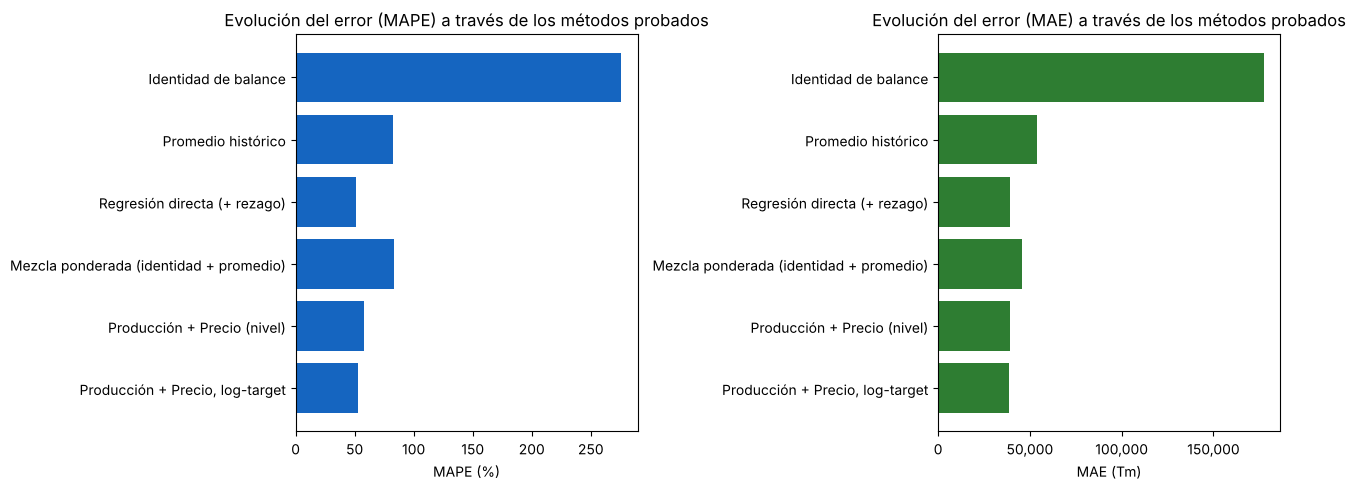

In [71]:
from matplotlib.ticker import MaxNLocator, FuncFormatter

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

nombres_cortos = [n.split(". ", 1)[1] if ". " in n else n for n in tabla_evolucion.index]
nombres_cortos = [n.replace("Regresión directa (+ Importaciones año anterior)", "Regresión directa (+ rezago)") for n in nombres_cortos]

axes[0].barh(nombres_cortos, tabla_evolucion["MAPE (%)"], color="#1565C0")
axes[0].set_xlabel("MAPE (%)")
axes[0].set_title("Evolución del error (MAPE) a través de los métodos probados")
axes[0].invert_yaxis()

axes[1].barh(nombres_cortos, tabla_evolucion["MAE (Tm)"], color="#2E7D32")
axes[1].set_xlabel("MAE (Tm)")
axes[1].set_title("Evolución del error (MAE) a través de los métodos probados")
axes[1].invert_yaxis()
axes[1].xaxis.set_major_locator(MaxNLocator(4))
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

plt.tight_layout()
plt.show()


In [72]:
# Criterio de selección: menor MAE fuera de muestra (Leave-One-Out). Solo pueden ser modelo final
# las variantes que se pueden aplicar a 2026 con información disponible al momento de pronosticar:
# la 1 y la 4 necesitan Demanda y Stocks de 2026, que todavía no existen.
VARIANTES_APLICABLES_2026 = ["2.", "3.", "5.", "6."]
ranking_mae = tabla_evolucion["MAE (Tm)"].sort_values()
print("Variantes ordenadas por MAE (menor = mejor):")
print(ranking_mae.round(0).to_string())

variante_final = next(v for v in ranking_mae.index if v[:2] in VARIANTES_APLICABLES_2026)
print(f"\nModelo final elegido (menor MAE entre las aplicables a 2026): {variante_final}")

metricas_modelo_final_etapa3 = pd.DataFrame({
    f"Modelo final: {variante_final}": resultados_evolucion[variante_final],
}).round(2)
metricas_modelo_final_etapa3

Variantes ordenadas por MAE (menor = mejor):
6. Producción + Precio, log-target                      38603.0
3. Regresión directa (+ Importaciones año anterior)     38923.0
5. Producción + Precio (nivel)                          39080.0
4. Mezcla ponderada (identidad + promedio)              45690.0
2. Promedio histórico                                   53662.0
1. Identidad de balance                                177397.0

Modelo final elegido (menor MAE entre las aplicables a 2026): 6. Producción + Precio, log-target


,"Modelo final: 6. Producción + Precio, log-target"
MAE (Tm),38603.42
MAPE (%),52.79
MdAPE (%),45.68
R2,0.14
RMSE (Tm),50510.52


**Resultado:** la Variante 6 (Producción + Precio, log-target) tiene el menor MAE (38,603 Tm), pero
por un margen muy pequeño: la Variante 3 (regresión con rezago, 38,923 Tm) y la Variante 5
(Producción + Precio en nivel, 39,080 Tm) quedan a menos del 1.3%, y la Variante 5 tiene el menor
RMSE (49,962 vs. 50,511 Tm). Con 11 años de datos, estas tres variantes deben leerse como
prácticamente empatadas; las tres superan claramente al promedio histórico (MAE 53,662 Tm) y a la
identidad contable (MAE 177,397 Tm). La Variante 3 se evalúa sobre 10 años, porque pierde el
primero al construir el rezago, así que su MAE no es exactamente comparable. Se aplica la regla
definida de antemano (menor MAE) y se elige la Variante 6.

## 3.10 — Por qué queda un margen de error (y por qué eso también es un resultado honesto)

Con una muestra de apenas 10-12 años, un par de años atípicos pesan desproporcionadamente en un
promedio porcentual (MAPE, MdAPE), aunque los errores absolutos (MAE, RMSE) se mantengan en un
rango razonable. Una explicación plausible, consistente con cómo funciona realmente el mercado
ecuatoriano de maíz, es que una parte de las Importaciones no depende solo de variables de
mercado (Producción, Precio), sino de **decisiones institucionales**: en Ecuador, el Consejo
Consultivo de la Cadena de Maíz Amarillo (MAG, junto con gremios de productores, avicultores y
balanceados) fija periódicamente un precio mínimo de sustentación y autoriza cupos de importación
en tramos discrecionales — no de forma continua ni puramente reactiva al mercado. Esa dinámica de
política sectorial es, con la evidencia que tenemos, la explicación más plausible del margen de
error que ningún modelo puramente estadístico puede eliminar del todo sin datos sobre esas
decisiones. Retomamos este punto en la comparación con la literatura, al final del notebook.


## 3.11 — Pronóstico de Importaciones Necesarias para 2026

Se usa la Producción 2026 estimada en la Etapa 1 (`produccion_2026_estimada`). Como el Precio
internacional de 2026 todavía no existe (el FMI publica el promedio una vez que el año cierra), se
usa el último valor real conocido (2025) como supuesto de partida, no como un pronóstico de precio.
El pronóstico oficial es el del modelo elegido en el Paso 3.9; la tabla muestra también lo que
darían las demás variantes aplicables, como análisis de sensibilidad.

In [73]:
precio_2026_supuesto = precio_internacional.loc[precio_internacional["Año"] == 2025, "Precio_Internacional_USD_Tm"].iloc[0]
X_2026 = np.array([[produccion_2026_estimada, precio_2026_supuesto]])

def pronostico_importaciones_2026(variante):
    '''Entrena la variante con TODOS los años disponibles y la aplica a 2026.'''
    if variante.startswith("2."):
        return y_real_importaciones.mean()
    if variante.startswith("3."):
        modelo = LinearRegression().fit(X_rezago, y_rezago)
        return modelo.predict([[produccion_2026_estimada, panel_etapa3["Importaciones_TM"].iloc[-1]]])[0]
    if variante.startswith("5."):
        return LinearRegression().fit(X_produccion_precio, y_real_importaciones).predict(X_2026)[0]
    if variante.startswith("6."):
        return np.exp(LinearRegression().fit(X_produccion_precio, y_log_importaciones).predict(X_2026))[0]
    return np.nan

sensibilidad_2026 = pd.DataFrame({
    "Variante": [v for v in tabla_evolucion.index if v[:2] in VARIANTES_APLICABLES_2026],
})
sensibilidad_2026["MAE (Tm)"] = sensibilidad_2026["Variante"].map(tabla_evolucion["MAE (Tm)"]).round(0)
sensibilidad_2026["Importaciones 2026 (Tm)"] = sensibilidad_2026["Variante"].apply(pronostico_importaciones_2026).round(0)
sensibilidad_2026["Modelo final"] = np.where(sensibilidad_2026["Variante"] == variante_final, "<- elegido", "")

importaciones_2026_estimadas = pronostico_importaciones_2026(variante_final)

print(f"Producción 2026 estimada (Etapa 1):        {produccion_2026_estimada:,.0f} Tm")
print(f"Precio internacional supuesto para 2026:    {precio_2026_supuesto:.2f} USD/Tm (= último dato real, 2025)")
print(f"Modelo final:                               {variante_final}")
print(f"IMPORTACIONES NECESARIAS ESTIMADAS 2026:    {importaciones_2026_estimadas:,.0f} Tm")
print()
print("Este número arrastra la incertidumbre de la Producción 2026 (Parte 1), el supuesto de")
print("Precio y el margen de error propio del modelo: debe leerse como un orden de magnitud.")
sensibilidad_2026

Producción 2026 estimada (Etapa 1):        1,493,945 Tm
Precio internacional supuesto para 2026:    203.01 USD/Tm (= último dato real, 2025)
Modelo final:                               6. Producción + Precio, log-target
IMPORTACIONES NECESARIAS ESTIMADAS 2026:    65,404 Tm

Este número arrastra la incertidumbre de la Producción 2026 (Parte 1), el supuesto de
Precio y el margen de error propio del modelo: debe leerse como un orden de magnitud.


,Variante,MAE (Tm),Importaciones 2026 (Tm),Modelo final
0,2. Promedio histórico,53662.0,90655.0,
1,3. Regresión directa (+ Importaciones año ante...,38923.0,120782.0,
2,5. Producción + Precio (nivel),39080.0,79698.0,
3,"6. Producción + Precio, log-target",38603.0,65404.0,<- elegido


**Sensibilidad del pronóstico:** aunque las variantes 3, 5 y 6 tienen errores históricos casi
iguales, sus pronósticos para 2026 son muy distintos: 65,404 Tm (Variante 6, la elegida), 79,698 Tm
(Variante 5) y 120,782 Tm (Variante 3). El promedio histórico daría 90,655 Tm. Esta dispersión es
en sí misma un resultado: con la información disponible, las Importaciones Necesarias de 2026 se
ubican en un rango aproximado de 65,000 a 120,000 Tm, y la cifra puntual del modelo elegido debe
leerse dentro de ese rango.

## Resumen de la Etapa 3

Modelo final: Producción + Precio internacional, con el objetivo en logaritmo (MAE 38,603 Tm,
RMSE 50,511 Tm, validación Leave-One-Out). Importaciones Necesarias estimadas para 2026:
**65,404 Tm**, con un rango de sensibilidad de 65,000 a 120,000 Tm según la variante.

In [74]:
TABLAS_PARA_DESCARGAR["Etapa3_Panel_Modelo"] = panel_etapa3.reset_index()
TABLAS_PARA_DESCARGAR["Etapa3_Evolucion_Metodos"] = tabla_evolucion.reset_index().rename(columns={"index": "Método"})
TABLAS_PARA_DESCARGAR["Etapa3_Metricas_Modelo_Final"] = metricas_modelo_final_etapa3.reset_index().rename(columns={"index": "Métrica"})
TABLAS_PARA_DESCARGAR["Etapa3_Pronostico_2026"] = pd.DataFrame({
    "Concepto": ["Producción 2026 (Tm)", "Precio internacional supuesto (USD/Tm)", "Importaciones Necesarias 2026 (Tm)"],
    "Valor": [round(produccion_2026_estimada, 0), round(precio_2026_supuesto, 2), round(importaciones_2026_estimadas, 0)],
})
TABLAS_PARA_DESCARGAR["Etapa3_Sensibilidad_2026"] = sensibilidad_2026

print("Etapa 3 completa.")


Etapa 3 completa.


# Parte 5 — Conclusiones generales

## Resumen de resultados, las 3 etapas juntas


In [75]:
resumen_general = pd.DataFrame({
    "Etapa": [
        "1. Producción — R² LOYO (provincia-año)",
        "1. Producción — R² LOYO nacional agregado",
        "1. Producción — MAPE nacional (LOYO)",
        "1. Producción 2026 (Tm)",
        "2. Demanda estimada (Tm)",
        "3. Importaciones — modelo final",
        "3. Importaciones — MAE (Tm)", "3. Importaciones — RMSE (Tm)",
        "3. Importaciones Necesarias 2026 (Tm)",
    ],
    "Resultado del modelo": [
        f"{r2_score(y_corregido, pred_loyo_corregido):.3f}",
        f"{r2_nacional_corregido:.3f}",
        f"{mape_nacional_corregido:.1f}%",
        f"{produccion_2026_estimada:,.0f}",
        f"{demanda_estimada:,.0f}",
        variante_final,
        f"{resultados_evolucion[variante_final]['MAE (Tm)']:,.0f}",
        f"{resultados_evolucion[variante_final]['RMSE (Tm)']:,.0f}",
        f"{importaciones_2026_estimadas:,.0f}",
    ],
})
resumen_general

,Etapa,Resultado del modelo
0,1. Producción — R² LOYO (provincia-año),0.967
1,1. Producción — R² LOYO nacional agregado,0.134
2,1. Producción — MAPE nacional (LOYO),10.9%
3,1. Producción 2026 (Tm),"1,493,945"
4,2. Demanda estimada (Tm),"1,508,333"
5,3. Importaciones — modelo final,"6. Producción + Precio, log-target"
6,3. Importaciones — MAE (Tm),"38,603"
7,3. Importaciones — RMSE (Tm),"50,511"
8,3. Importaciones Necesarias 2026 (Tm),"65,404"


## Qué se aprendió, sin saltarse los tropiezos

1. **El clima solo revela su efecto si se analiza por región.** Sin separar por región, la
   correlación entre precipitación anual y producción es prácticamente nula (+0.022). Separando
   por región, la precipitación de enero-junio en la Costa (+0.520) y la de julio-septiembre en la
   Sierra (-0.369) correlacionan con la Producción con signos opuestos. Quitar el clima del modelo
   baja el R² Group K-Fold de 0.775 a 0.702.

2. **La caída de 2016-2017 venía de una variable incompleta en los archivos publicados, no de la
   realidad.** En los `.csv` de la ESPAC 2016 y 2017, la producción derivada (`ct_prod`) solo está
   en el 2.7% de los registros de maíz duro seco, mientras que la cantidad cosechada cruda está
   completa. Reconstruyéndola con la misma regla del INEC (`ct_k516 × ct_k518 / 2200`), la
   producción coincide con los Informes Ejecutivos del INEC (total nacional +1.6% y +0.1%), con el
   detalle de las 23 provincias. Corregirla bajó el RMSE LOYO de 57,550 a 28,914 Tm.

3. **La producción corregida es consistente con otras fuentes.** El "cálculo propio" de Demanda
   (ESPAC corregida + importaciones del BCE) correlaciona 0.915 con el USDA-PSD, un nivel similar
   al de FAOSTAT (0.924).

4. **El R² provincia-año (0.967) y el error nacional cuentan historias distintas.** El modelo
   distingue muy bien entre provincias, pero su error nacional por año es de 10.9% en promedio
   (R² nacional 0.134). Para el pronóstico de 2026, la cifra relevante es el error nacional.

5. **La identidad contable de balance es un mal predictor de Importaciones** (MAE 177,397 Tm,
   peor que el promedio histórico simple: 53,662 Tm). Los modelos directos con Producción y Precio
   reducen el MAE a unos 38,600-39,100 Tm; tres variantes quedan prácticamente empatadas, y sus
   pronósticos para 2026 van de 65,000 a 120,000 Tm.

6. **En Demanda, ningún método de series de tiempo le ganó de forma consistente al promedio
   histórico simple** (diferencias de 0.3% a 3.5%, con un ganador distinto en cada serie). En
   Importaciones, en cambio, los modelos con Producción y Precio sí mejoran al promedio histórico,
   aunque con un error que sigue siendo alto (MAPE ~53%). Una explicación plausible del error que
   queda son las decisiones institucionales (precios de sustentación y cupos de importación
   fijados por el Consejo Consultivo de la Cadena de Maíz Amarillo), que no están en los datos.

## Limitaciones que siguen abiertas

- **Validación no anidada.** Los hiperparámetros de la Etapa 1 se eligen con los mismos esquemas
  LOYO y Group K-Fold con los que se reportan las métricas, así que estas son algo optimistas. Una
  validación anidada (elegir hiperparámetros dentro de cada pliegue) daría una estimación más
  conservadora.
- **Group K-Fold depende del reparto de provincias.** Con 23 provincias muy desiguales en tamaño,
  el RMSE Group K-Fold cambia en ±12,000 Tm según qué provincias queden juntas (Paso 1.17.4).
- **Desfase temporal entre fuentes.** La serie de Importaciones de la Etapa 3 es la del BCE en año
  calendario, mientras que el balance del USDA-PSD se reporta en año agrícola; se usa el año
  calendario de cierre del USDA como aproximación.
- **Muestras pequeñas.** La Etapa 3 cuenta con 11 años; con ese tamaño, varias variantes quedan
  empatadas y el pronóstico 2026 es sensible a la variante elegida.
- **Supuestos del pronóstico 2026.** Superficie sembrada igual al promedio 2023-2025, precipitación
  de julio-septiembre igual a su promedio histórico, y precio internacional igual al de 2025.

## Contraste con la literatura académica (2021 en adelante)

Con los resultados propios ya cerrados (arriba), la pregunta natural es: ¿son razonables estos
números frente a lo que reporta la literatura especializada para problemas similares? Esta
sección no busca "validar" el notebook contra una cifra externa fija, sino ubicar nuestros
resultados dentro del rango de lo que otros estudios —publicados de 2021 en adelante— han
encontrado en tareas comparables: pronóstico de rendimiento/producción agrícola con variables
climáticas, pronóstico de demanda con series cortas, y modelos de importación de cereales.

### Etapa 1 — Producción: ¿qué tan razonable es nuestro R² LOYO para maíz con XGBoost?

Varios estudios recientes reportan el desempeño de XGBoost para pronosticar rendimiento o
producción de maíz usando variables climáticas, en contextos con muestras igualmente moderadas:

- Ennaji, Baha, Vergutz y El Allali (2024, *PLOS ONE*) compararon 7 algoritmos para el híbrido de
  maíz ZhengDan 958 y encontraron que XGBoost fue el de mejor desempeño, con R²=0.84 (RMSE=0.40
  t/ha, MAE=0.29 t/ha), superando a Random Forest (R²=0.72), SVR y regresión lineal.
- Lionel, Musabe, Gatera y Twizere (2026, *Algorithms*, MDPI) pronosticaron rendimiento de maíz en
  el distrito de Kayonza (Ruanda) usando 13 años de datos climáticos (26 observaciones
  estacionales): Random Forest, SVM y XGBoost obtuvieron R² entre 0.95 y 0.96, muy por encima de
  una regresión LASSO (R²=0.26) — evidencia de que los modelos no lineales capturan mucho mejor la
  interacción clima-rendimiento que un modelo lineal simple, en línea con nuestra propia decisión
  de usar XGBoost en vez de una regresión para la Etapa 1.
- Caviedes, Albán, Velásquez y Carvajal (2024, *Avances en Ciencias e Ingenierías*, USFQ) —
  específico de Ecuador— reportan una producción nacional de maíz amarillo duro de entre 1.32 y
  1.64 millones de toneladas para 2018-2023, con un crecimiento proyectado de ~3% anual hasta
  2029 — un orden de magnitud consistente con nuestro propio pronóstico para 2026 (Paso 1.20),
  aunque ese estudio usa una regresión lineal simple sobre el tiempo, no un modelo de Machine
  Learning con variables climáticas por provincia.

El R² LOYO provincia-año de este trabajo (0.967, Paso 1.16) queda en la parte alta del rango de
referencia (aproximadamente 0.7-0.96 en la literatura reciente), pero la comparación debe hacerse
con cuidado: buena parte de ese R² proviene de la diferencia de tamaño entre provincias, y a nivel
nacional el R² es 0.134 (MAPE 10.9%). Es razonable que el ajuste nacional sea más modesto: trabajamos con un panel
de solo 12 años (interanual, no estacional) que combina dos regímenes climáticos muy distintos
(Costa y Sierra) en un único modelo nacional, en vez de una sola parcela u homogeneidad
climática con muchas observaciones por temporada, como en los estudios citados.

### Etapa 2 — Demanda: ¿por qué los métodos sofisticados no superan al promedio histórico?

El hallazgo de que ningún método de series de tiempo (Holt, AR(1), Auto-ARIMA, regresión lineal,
Random Walk) superó de forma consistente al promedio histórico simple (ventajas de 0.3% a 3.5%,
con un ganador distinto en cada serie) no es una anomalía del caso
ecuatoriano: es consistente con hallazgos recientes en pronóstico de series cortas y volátiles.

- Makridakis, Petropoulos y Spiliotis (2022, *International Journal of Forecasting*) —
  conclusiones de la competencia M5, la referencia más citada en la disciplina desde 2021—
  encontraron que los métodos sofisticados solo superan de forma consistente a los simples
  (naive, suavizado exponencial) cuando pueden "aprender" simultáneamente de miles de series
  relacionadas (cross-learning); esa ventaja desaparece cuando se pronostica una sola serie
  nacional con pocos años de historia, como en nuestro caso.
- Wang y Zhang (2026, preprint arXiv) evaluaron 17 métodos de pronóstico sobre precios mensuales
  de maíz, soya, trigo y algodón del USDA (1997-2025). Entre los métodos que, como los nuestros,
  no dependen de un preentrenamiento externo masivo, el método Naive (puesto 6 de 17) superó a
  Random Forest, XGBoost y a los cuatro modelos de deep learning entrenados desde cero (LSTM,
  N-BEATS, TFT, DeepAR), porque estos últimos sobreajustan con apenas 100-400 observaciones de
  entrenamiento — un tamaño de muestra del mismo orden que el de nuestra propia serie de Demanda
  (10-12 años).

Esto respalda, con evidencia externa e independiente, la decisión metodológica de este notebook
de usar el promedio móvil de 3 años en vez de un método más sofisticado.

### Etapa 3 — Importaciones: ¿qué tan grande es nuestro margen de error, comparado con otros modelos de importación de cereales?

- Too, Bett y Gitau (2023, *African Journal of Agricultural Research*) estimaron un modelo de
  importaciones de trigo para Kenia usando cointegración, con rendimiento, precios relativos,
  existencias finales e importaciones rezagadas como predictores — variables muy similares a las
  que probamos en nuestras Variantes 3 y 5 —, apoyados en 20 años de datos (2000-2019).
- Valencia-Romero, Trejo-García y Ríos-Bolívar (2023, *Agriculture*, MDPI) modelaron la demanda de
  importación de trigo en México desde 1994 con un enfoque ARDL, usando actividad económica y
  tipo de cambio real como predictores — de nuevo, con varias décadas de datos disponibles.
- Ibarra-Velásquez, Ramírez-Flores, Molina-Villamar y Zuñiga-Moreno (2023, *Polo del
  Conocimiento*) calcularon el balance oferta-demanda de maíz duro en Ecuador usando exactamente
  la misma identidad contable que probamos en nuestra Variante 1 — la que efectivamente usa el MAG
  para calcular cupos de importación, según el Acuerdo Ministerial 134 — sin reportar un error de
  pronóstico validado, porque su objetivo era un cálculo puntual para una temporada, no un modelo
  evaluado con validación cruzada como el nuestro.

La comparación deja dos lecturas honestas: (1) los modelos directos de Importaciones (Producción +
Precio) generalizan sustancialmente mejor que la identidad contable — el mismo patrón
que sugiere la literatura de modelos de importación bien especificados frente a balances
contables simples —, y (2) buena parte del error que queda (MAPE alto en una serie corta) es
esperable dado el tamaño de muestra: los estudios de Kenia y México logran mejor ajuste apoyados
en 20-30 años de datos, mientras que nuestra serie de Importaciones-BCE cubre poco más de una
década. Esto no invalida el modelo: es una limitación de datos disponibles, no de la metodología
elegida, y es consistente con la explicación institucional (cupos y precios de sustentación
fijados por el Consejo Consultivo de la Cadena de Maíz Amarillo, ver Paso 3.10) para el margen de
error que queda incluso en el mejor modelo probado.


### Referencias de esta comparación

- Ennaji, O., Baha, S., Vergutz, L., & El Allali, A. (2024). Gradient boosting for yield
  prediction of elite maize hybrid ZhengDan 958. *PLOS ONE, 19*(12), e0315493.
- Lionel, B. M., Musabe, R., Gatera, O., & Twizere, C. (2026). Performance Analysis of Machine
  Learning Techniques in Predicting Maize Crop Yield: Case Study of Kayonza District—Rwanda.
  *Algorithms, 19*(6), 448.
- Caviedes, M., Albán, M. G., Velásquez, J., & Carvajal, F. (2024). Estudio de la eficiencia
  productiva del maíz (Zea mays L.) amiláceo y duro en el Ecuador. *Avances en Ciencias e
  Ingenierías, 16*(2), e3401.
- Makridakis, S., Petropoulos, F., & Spiliotis, E. (2022). The M5 competition: Conclusions.
  *International Journal of Forecasting.*
- Wang, L., & Zhang, B. (2026). The Promise of Time-Series Foundation Models for Agricultural
  Forecasting: Evidence from Commodity Prices. *arXiv preprint arXiv:2601.06371.*
- Too, H. K., Bett, H. K., & Gitau, R. (2023). Determination of import demand of wheat in Kenya;
  A time series analysis from 2000 to 2019. *African Journal of Agricultural Research, 19*(3),
  287-297.
- Valencia-Romero, R., Trejo-García, J. C., & Ríos-Bolívar, H. (2023). Wheat Import Demand in
  Mexico: Evidence of Quantile Cointegration. *Agriculture, 13*(5), 980.
- Ibarra-Velásquez, A. A., Ramírez-Flores, L. C., Molina-Villamar, J., & Zuñiga-Moreno, L. E.
  (2023). Análisis de la cadena agroalimentaria del maíz en Ecuador. *Polo del Conocimiento,
  8*(1), 1862-1873.

**Nota:** todas las cifras citadas de estos estudios se presentan de forma agregada y
parafraseada, como contexto para interpretar los resultados propios de este notebook — no como
una validación externa de los números, ya que cada estudio usa un país, cultivo, periodo y
metodología distintos.


## Análisis exploratorio y pruebas sobre la naturaleza de los datos

Esta sección reproduce las cifras, tablas y figuras del capítulo de metodología de la tesis (justificación y aplicación de la metodología). Trabaja con los datos ya depurados: el panel provincia-año con la producción de 2016-2017 reconstruida y las series nacionales de las Etapas 2 y 3. Incluye estadísticos descriptivos, detección de atípicos, normalidad (Shapiro-Wilk), linealidad (Pearson frente a Spearman), estacionariedad (Dickey-Fuller aumentada y KPSS), multicolinealidad (VIF) y matrices de correlación. Las figuras se guardan en `resultados/figuras/`.

/tmp/ipykernel_908/2375955212.py:69: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  k = kpss(s, regression="c", nlags=1)
/tmp/ipykernel_908/2375955212.py:69: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  k = kpss(s, regression="c", nlags=1)
/tmp/ipykernel_908/2375955212.py:69: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  k = kpss(s, regression="c", nlags=1)


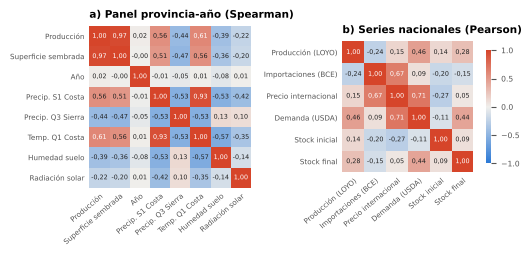

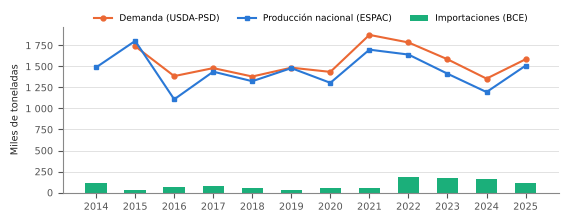

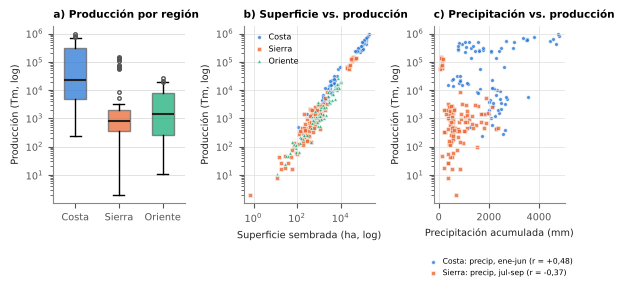

Concentración Los Ríos + Manabí + Guayas: 87.5% | asimetría de la producción: 3.06
Atípicos (> Q3 + 1,5 RIC): 50 observaciones de ['ESMERALDAS', 'GUAYAS', 'LOJA', 'LOS RIOS', 'MANABI']
Shapiro-Wilk producción: W = 0.465, p = 1.06e-27 | ln(producción): W = 0.969, p = 1.61e-05
Superficie vs. producción: Pearson = 0.983, Spearman = 0.965
Clima vs. producción (Pearson, Spearman): {'Precip_S1_Costa': [0.481, 0.059], 'Precip_Q3_Sierra': [-0.374, -0.177], 'Temp_Q1_Costa': [0.31, 0.479]}
Rendimiento mediano por región (t/ha): {'Costa': 4.04, 'Oriente': 1.46, 'Sierra': 1.66}
Coeficiente de variación -> producción 0.14 | demanda 0.11 | importaciones 0.59
VIF (producción LOYO, precio): 1.02


,Serie,n,ADF,p_ADF,KPSS,p_KPSS
0,Producción nacional (2014-2025),12,-3.027,0.032,0.076,0.100
1,Demanda USDA-PSD (2015-2025),11,-1.914,0.325,0.103,0.100
2,Importaciones BCE (2014-2025),12,-1.433,0.566,0.349,0.099
3,Precio internacional (1992-2025),34,-2.378,0.148,0.976,0.010


In [76]:
import matplotlib
OUT = f"{RUTA_RESULTADOS}/figuras"
os.makedirs(OUT, exist_ok=True)
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.outliers_influence import variance_inflation_factor
from matplotlib.colors import LinearSegmentedColormap
panel = panel_corregido_extendido.copy()
e3 = panel_etapa3.reset_index()
dem = tabla_tres_fuentes
bce = bce_anual_historico
precio = precio_internacional
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA2, GRILLA = "#222222", "#555555", "#dddddd"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 7, "axes.edgecolor": "#888888",
                     "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 7.5,
                     "axes.titleweight": "bold", "legend.frameon": False})
miles = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v/1000:,.0f}".replace(",", " "))

R = {}

# ------------------------------------------------------------------ descriptivos y faltantes
num = {"produccion": "Producción (Tm)", "sembrada": "Superficie sembrada (ha)",
       "Precip_S1_Costa": "Precip. ene-jun Costa (mm)", "Precip_Q3_Sierra": "Precip. jul-sep Sierra (mm)",
       "Temp_Q1_Costa": "Temp. ene-mar Costa (°C)", "humedad_promedio": "Humedad del suelo (%)",
       "radiacion_promedio": "Radiación solar (kWh/m²/día)"}
desc = panel[list(num)].describe().T
R["descriptivos"] = desc.round(2).to_dict()
R["faltantes_panel"] = int(panel.isna().sum().sum())
R["n_panel"] = len(panel); R["n_prov"] = panel["provincia_clave"].nunique()
# concentración
prov_tot = panel.groupby("provincia_clave")["produccion"].sum().sort_values(ascending=False)
R["top3_share"] = float(prov_tot.head(3).sum() / prov_tot.sum())
R["asimetria_prod"] = float(stats.skew(panel["produccion"]))
q1, q3 = panel["produccion"].quantile([.25, .75]); iqr = q3 - q1
atip = panel[panel["produccion"] > q3 + 1.5 * iqr]
R["atipicos_n"] = len(atip); R["atipicos_prov"] = sorted(atip["provincia_clave"].unique().tolist())

# ------------------------------------------------------------------ normalidad y linealidad
sw = stats.shapiro(panel["produccion"]); swl = stats.shapiro(np.log1p(panel["produccion"]))
R["shapiro_prod"] = [float(sw.statistic), float(sw.pvalue)]
R["shapiro_logprod"] = [float(swl.statistic), float(swl.pvalue)]
R["pearson_sem_prod"] = float(stats.pearsonr(panel["sembrada"], panel["produccion"])[0])
R["spearman_sem_prod"] = float(stats.spearmanr(panel["sembrada"], panel["produccion"])[0])
lin = {}
for reg, col in [("Costa", "Precip_S1_Costa"), ("Sierra", "Precip_Q3_Sierra"), ("Costa", "Temp_Q1_Costa")]:
    s = panel[(panel["region"] == reg) & ~panel["anio"].isin([])]
    lin[col] = [float(stats.pearsonr(s[col], s["produccion"])[0]), float(stats.spearmanr(s[col], s["produccion"])[0])]
R["lin_clima"] = lin
# rendimiento implícito por región (linealidad producción-superficie)
panel["rend"] = panel["produccion"] / panel["sembrada"]
R["rend_region"] = panel.groupby("region")["rend"].median().round(2).to_dict()

# ------------------------------------------------------------------ series nacionales: ADF y KPSS
nac = pd.DataFrame({"Año": range(2014, 2026)})
nac["Produccion"] = panel.groupby("anio")["produccion"].sum().values
nac = nac.merge(dem[["Año", "Demanda_USDA_PSD"]], on="Año", how="left")
nac = nac.merge(bce[["Año", "TM (Peso Neto)"]].rename(columns={"TM (Peso Neto)": "Importaciones"}), on="Año", how="left")
nac = nac.merge(precio.rename(columns={"Precio_Internacional_USD_Tm": "Precio"}), on="Año", how="left")
series = {"Producción nacional (2014-2025)": nac["Produccion"],
          "Demanda USDA-PSD (2015-2025)": nac["Demanda_USDA_PSD"].dropna(),
          "Importaciones BCE (2014-2025)": nac["Importaciones"],
          "Precio internacional (1992-2025)": precio["Precio_Internacional_USD_Tm"]}
est = []
for nombre, s in series.items():
    s = pd.Series(s).dropna().astype(float).values
    a = adfuller(s, maxlag=1, autolag=None, regression="c")
    k = kpss(s, regression="c", nlags=1)
    est.append({"Serie": nombre, "n": len(s), "ADF": round(a[0], 3), "p_ADF": round(a[1], 3),
                "KPSS": round(k[0], 3), "p_KPSS": round(k[1], 3)})
R["estacionariedad"] = est

# ------------------------------------------------------------------ multicolinealidad etapa 3
e3x = e3[["Produccion_LOYO_TM", "Precio_Internacional_USD_Tm"]].astype(float)
Xc = np.column_stack([np.ones(len(e3x)), e3x.values])
R["vif"] = [float(variance_inflation_factor(Xc, i)) for i in (1, 2)]
R["corr_e3"] = float(e3x.corr().iloc[0, 1])

# ------------------------------------------------------------------ matrices de correlación
etiq = {"produccion": "Producción", "sembrada": "Superficie\nsembrada", "anio": "Año",
        "Precip_S1_Costa": "Precip. S1\nCosta", "Precip_Q3_Sierra": "Precip. Q3\nSierra",
        "Temp_Q1_Costa": "Temp. Q1\nCosta", "humedad_promedio": "Humedad\nsuelo", "radiacion_promedio": "Radiación\nsolar"}
cm1 = panel[list(etiq)].corr(method="spearman")
nac2 = e3.set_index("Año")[["Produccion_LOYO_TM", "Importaciones_TM", "Precio_Internacional_USD_Tm", "Demanda", "StockInicial", "StockFinal"]].astype(float)
etiq2 = {"Produccion_LOYO_TM": "Producción\n(LOYO)", "Importaciones_TM": "Importaciones\n(BCE)",
         "Precio_Internacional_USD_Tm": "Precio\ninternacional", "Demanda": "Demanda\n(USDA)",
         "StockInicial": "Stock\ninicial", "StockFinal": "Stock\nfinal"}
cm2 = nac2.corr(method="pearson")
R["corr_panel"] = cm1.round(3).to_dict(); R["corr_nac"] = cm2.round(3).to_dict()

div = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#d6452a"])
fig, axes = plt.subplots(1, 2, figsize=(5.3, 2.1), gridspec_kw={"width_ratios": [1.25, 1], "wspace": .62})
for ax, cm, et, tit in [(axes[0], cm1, etiq, "a) Panel provincia-año (Spearman)"),
                        (axes[1], cm2, etiq2, "b) Series nacionales (Pearson)")]:
    im = ax.imshow(cm.values, cmap=div, vmin=-1, vmax=1)
    labs = [et[c] for c in cm.columns]
    ax.set_xticks(range(len(labs))); ax.set_xticklabels([l.replace("\n"," ") for l in labs], fontsize=5.2, rotation=40, ha="right", rotation_mode="anchor")
    ax.set_yticks(range(len(labs))); ax.set_yticklabels([l.replace("\n"," ") for l in labs], fontsize=5.2)
    for i in range(len(labs)):
        for j in range(len(labs)):
            v = cm.values[i, j]
            ax.text(j, i, f"{v:.2f}".replace(".", ","), ha="center", va="center", fontsize=4.6,
                    color="white" if abs(v) > .6 else TINTA)
    ax.set_title(tit, loc="left"); ax.spines[:].set_visible(False); ax.tick_params(length=0)
cb = fig.colorbar(im, ax=axes, shrink=.7, pad=.03, fraction=.03); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=5.5)
fig.savefig(f"{OUT}/fig_correlacion.png", dpi=300, bbox_inches="tight"); plt.show()

# ------------------------------------------------------------------ figura: situación del problema
fig, ax = plt.subplots(figsize=(6.4, 2.15))
x = nac["Año"]
ax.plot(x, nac["Demanda_USDA_PSD"], color=NARANJA, lw=1.5, marker="o", ms=3.5, label="Demanda (USDA-PSD)")
ax.plot(x, nac["Produccion"], color=AZUL, lw=1.5, marker="s", ms=3.5, label="Producción nacional (ESPAC)")
ax.bar(x, nac["Importaciones"], color=AQUA, width=.55, label="Importaciones (BCE)", zorder=0)
ax.yaxis.set_major_formatter(miles); ax.set_ylabel("Miles de toneladas")
ax.grid(axis="y", color=GRILLA, lw=.6); ax.set_axisbelow(True); ax.set_xticks(x)
ax.legend(loc="upper center", bbox_to_anchor=(.5, 1.13), ncol=3, fontsize=6.5)
fig.savefig(f"{OUT}/fig_problema.png", dpi=300, bbox_inches="tight"); plt.show()
R["brecha"] = (nac["Demanda_USDA_PSD"] - nac["Produccion"]).dropna().round(0).tolist()
R["cv_prod"] = float(nac["Produccion"].std() / nac["Produccion"].mean())
R["cv_imp"] = float(nac["Importaciones"].std() / nac["Importaciones"].mean())
R["cv_dem"] = float(nac["Demanda_USDA_PSD"].std() / nac["Demanda_USDA_PSD"].mean())

# ------------------------------------------------------------------ figura: distribución, linealidad y clima
colores = {"Costa": AZUL, "Sierra": NARANJA, "Oriente": AQUA}
marc = {"Costa": "o", "Sierra": "s", "Oriente": "^"}
fig, axes = plt.subplots(1, 3, figsize=(6.6, 2.3), gridspec_kw={"wspace": .45})
ax = axes[0]
orden = ["Costa", "Sierra", "Oriente"]
bp = ax.boxplot([panel.loc[panel["region"] == r, "produccion"] for r in orden], widths=.5, patch_artist=True,
                medianprops={"color": TINTA, "lw": 1.5}, flierprops={"marker": "o", "ms": 2.5, "mfc": "none", "mec": TINTA2})
for p, r in zip(bp["boxes"], orden):
    p.set_facecolor(colores[r]); p.set_alpha(.75); p.set_edgecolor("#666666")
ax.set_xticklabels(orden); ax.set_yscale("log"); ax.set_ylabel("Producción (Tm, log)")
ax.set_title("a) Producción por región", loc="left"); ax.grid(axis="y", color=GRILLA, lw=.6)
ax = axes[1]
for r in orden:
    s = panel[panel["region"] == r]
    ax.scatter(s["sembrada"], s["produccion"], s=7, color=colores[r], marker=marc[r], alpha=.8, label=r, edgecolor="white", lw=.4)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Superficie sembrada (ha, log)"); ax.set_ylabel("Producción (Tm, log)")
ax.set_title("b) Superficie vs. producción", loc="left"); ax.legend(fontsize=5.8, loc="upper left", handletextpad=.2); ax.grid(color=GRILLA, lw=.5)
ax = axes[2]
s = panel[panel["region"] == "Costa"]
ax.scatter(s["Precip_S1_Costa"], s["produccion"], s=7, color=AZUL, marker="o", alpha=.8, edgecolor="white", lw=.4,
           label=f"Costa: precip. ene-jun (r = {lin['Precip_S1_Costa'][0]:+.2f})".replace(".", ","))
s2 = panel[panel["region"] == "Sierra"]
ax.scatter(s2["Precip_Q3_Sierra"], s2["produccion"], s=7, color=NARANJA, marker="s", alpha=.8, edgecolor="white", lw=.4,
           label=f"Sierra: precip. jul-sep (r = {lin['Precip_Q3_Sierra'][0]:+.2f})".replace(".", ","))
ax.set_xlabel("Precipitación acumulada (mm)"); ax.set_ylabel("Producción (Tm, log)"); ax.set_yscale("log")
ax.set_title("c) Precipitación vs. producción", loc="left"); ax.legend(fontsize=5.5, loc="upper center", bbox_to_anchor=(.5, -.27), ncol=1, handletextpad=.2); ax.grid(color=GRILLA, lw=.5)
fig.savefig(f"{OUT}/fig_eda.png", dpi=300, bbox_inches="tight"); plt.show()


print(f"Concentración Los Ríos + Manabí + Guayas: {R['top3_share']:.1%} | asimetría de la producción: {R['asimetria_prod']:.2f}")
print(f"Atípicos (> Q3 + 1,5 RIC): {R['atipicos_n']} observaciones de {R['atipicos_prov']}")
print(f"Shapiro-Wilk producción: W = {R['shapiro_prod'][0]:.3f}, p = {R['shapiro_prod'][1]:.2e} | ln(producción): W = {R['shapiro_logprod'][0]:.3f}, p = {R['shapiro_logprod'][1]:.2e}")
print(f"Superficie vs. producción: Pearson = {R['pearson_sem_prod']:.3f}, Spearman = {R['spearman_sem_prod']:.3f}")
print("Clima vs. producción (Pearson, Spearman):", {k: [round(v, 3) for v in vs] for k, vs in R['lin_clima'].items()})
print("Rendimiento mediano por región (t/ha):", R['rend_region'])
print(f"Coeficiente de variación -> producción {R['cv_prod']:.2f} | demanda {R['cv_dem']:.2f} | importaciones {R['cv_imp']:.2f}")
print(f"VIF (producción LOYO, precio): {R['vif'][0]:.2f}")
tabla_estacionariedad = pd.DataFrame(R["estacionariedad"])
TABLAS_PARA_DESCARGAR["Metodologia_Estacionariedad"] = tabla_estacionariedad
TABLAS_PARA_DESCARGAR["Metodologia_Descriptivos"] = desc.round(2).reset_index().rename(columns={"index": "Variable"})
tabla_estacionariedad


# Parte 5B — Resultados comparativos, inferencia estadística y escenarios

Esta sección reproduce las cifras de los capítulos 8 (Resultados) y 9 (Discusión y propuesta de
solución) de la tesis. Usa los modelos ya ajustados en las Partes 1 a 3 y agrega cinco análisis:

1. **Réplica de las soluciones alternativas de la literatura para la Etapa 1**, con los mismos
   pliegues LOYO y Group K-Fold del modelo propuesto: Random Forest con hiperparámetros por defecto
   (Ennaji et al., 2024; Shahhosseini et al., 2021) y regresión lineal múltiple (Li et al., 2023;
   Shahhosseini et al., 2021). En el total nacional se replican la tendencia lineal con la que
   Alban et al. (2024) proyectan la producción y el ARIMA de Noorunnahar et al. (2023). Como los
   artículos no publican todos sus hiperparámetros, se usan los valores por defecto de cada librería.
   La diferencia de errores se contrasta con la prueba de rangos con signo de Wilcoxon.
2. **Evaluación con origen móvil de la demanda (Etapa 2):** el promedio móvil de 3 años elegido se
   compara año a año con el promedio histórico, el Random Walk y la tendencia lineal, usando solo
   los años anteriores a cada pronóstico.
3. **Inferencia del modelo final de importaciones (Etapa 3):** coeficientes, errores estándar,
   intervalos de confianza, pruebas de los supuestos y el intervalo de predicción para 2026.
4. **Traducción monetaria del error:** el MAE de cada modelo de importaciones se valora al precio
   internacional y a la prima de escasez interna.
5. **Escenarios 2026:** matriz de importaciones según el error de la producción y el precio.

In [77]:
from sklearn.ensemble import RandomForestRegressor
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt

FIGURAS = f"{RUTA_RESULTADOS}/figuras"
os.makedirs(FIGURAS, exist_ok=True)
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a8a"
TINTA, TINTA2, GRILLA = "#222222", "#555555", "#dddddd"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 7, "axes.edgecolor": "#888888",
                     "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 7.5,
                     "axes.titleweight": "bold", "legend.frameon": False})
miles = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v/1000:,.0f}".replace(",", " "))

def metricas_regresion(y_real, y_pred):
    y_real, y_pred = np.asarray(y_real, float), np.asarray(y_pred, float)
    return {"R2": r2_score(y_real, y_pred), "RMSE": rmse(y_real, y_pred),
            "MAE": mean_absolute_error(y_real, y_pred),
            "MAPE (%)": np.mean(np.abs((y_pred - y_real) / y_real)) * 100}

def wilcoxon_errores(error_propuesto, error_alternativo):
    '''Prueba de rangos con signo de Wilcoxon (bilateral) sobre los errores absolutos pareados.
    H0: la mediana de la diferencia |e_alternativo| - |e_propuesto| es cero.'''
    a, b = np.abs(np.asarray(error_alternativo)), np.abs(np.asarray(error_propuesto))
    prueba = stats.wilcoxon(a, b, alternative="two-sided")
    return {"W": prueba.statistic, "p": prueba.pvalue, "Mediana de la diferencia": np.median(a - b)}

print("Funciones de la Parte 5B listas.")

Funciones de la Parte 5B listas.


## 5B.1 — Etapa 1: réplica de las soluciones alternativas a nivel provincia-año

Random Forest y la regresión lineal de scikit-learn no reciben variables categóricas, así que la
provincia entra como variables dummy. Los pliegues son exactamente los mismos del modelo XGBoost:
un año fuera por vez (LOYO) y las provincias repartidas con `pliegues_por_provincia(semilla=42)`.

In [78]:
X_dummies = pd.get_dummies(X_corregido, columns=["provincia_clave"], drop_first=True, dtype=float)
anios_panel = panel_corregido["anio"]

def validar_alternativa(fabrica, X, y, anios, grupos, k=5, semilla=42):
    pred_loyo = pd.Series(index=X.index, dtype=float)
    for anio in sorted(anios.unique()):
        probar = anios == anio
        pred_loyo[probar] = fabrica().fit(X[~probar], y[~probar]).predict(X[probar])
    pred_gkf = pd.Series(index=X.index, dtype=float)
    pliegue = pliegues_por_provincia(grupos, k, semilla)
    for f in range(k):
        probar = pliegue == f
        pred_gkf.loc[probar] = fabrica().fit(X.loc[~probar], y.loc[~probar]).predict(X.loc[probar])
    return pred_loyo, pred_gkf

MODELOS_ETAPA1 = {
    "XGBoost (modelo propuesto)": (pred_loyo_corregido, pred_gkf_corregido),
    "Random Forest (Ennaji et al., 2024)": validar_alternativa(
        lambda: RandomForestRegressor(random_state=42, n_jobs=-1), X_dummies, y_corregido, anios_panel, grupos_corregido),
    "Regresión lineal múltiple (Li et al., 2023)": validar_alternativa(
        LinearRegression, X_dummies, y_corregido, anios_panel, grupos_corregido),
}

filas = []
for nombre, (p_loyo, p_gkf) in MODELOS_ETAPA1.items():
    nacional = pd.DataFrame({"real": y_corregido, "pred": p_loyo, "anio": anios_panel}).groupby("anio").sum()
    m_loyo, m_gkf = metricas_regresion(y_corregido, p_loyo), metricas_regresion(y_corregido, p_gkf)
    m_nac = metricas_regresion(nacional["real"], nacional["pred"])
    fila = {"Modelo": nombre, "R2 LOYO": m_loyo["R2"], "RMSE LOYO": m_loyo["RMSE"], "MAE LOYO": m_loyo["MAE"],
            "R2 GKF": m_gkf["R2"], "RMSE GKF": m_gkf["RMSE"], "MAE GKF": m_gkf["MAE"],
            "MAPE nacional (%)": m_nac["MAPE (%)"], "R2 nacional": m_nac["R2"]}
    if not nombre.startswith("XGBoost"):
        w_loyo = wilcoxon_errores(y_corregido - pred_loyo_corregido, y_corregido - p_loyo)
        w_gkf = wilcoxon_errores(y_corregido - pred_gkf_corregido, y_corregido - p_gkf)
        fila.update({"p Wilcoxon LOYO": w_loyo["p"], "Mediana dif. LOYO": w_loyo["Mediana de la diferencia"],
                     "p Wilcoxon GKF": w_gkf["p"], "Mediana dif. GKF": w_gkf["Mediana de la diferencia"]})
    filas.append(fila)
comparacion_alternativas_etapa1 = pd.DataFrame(filas).set_index("Modelo")
comparacion_alternativas_etapa1.round(3)

,R2 LOYO,RMSE LOYO,MAE LOYO,R2 GKF,RMSE GKF,MAE GKF,MAPE nacional (%),R2 nacional,p Wilcoxon LOYO,Mediana dif. LOYO,p Wilcoxon GKF,Mediana dif. GKF
Modelo,,,,,,,,,,,,
XGBoost (modelo propuesto),0.967,28914.481,11053.136,0.775,75768.306,30192.728,10.903,0.134,NaN,NaN,NaN,NaN
"Random Forest (Ennaji et al., 2024)",0.962,30986.454,10629.578,0.798,71926.695,25649.425,11.959,0.059,0.001,-257.602,0.000,-2109.306
"Regresión lineal múltiple (Li et al., 2023)",0.969,28232.200,12320.143,0.944,37883.307,20057.411,11.232,0.125,0.000,1788.531,0.024,2345.193


## 5B.2 — Etapa 1: alternativas sobre la serie nacional (12 años)

Alban et al. (2024) proyectan la producción nacional con una tendencia lineal y Noorunnahar et al.
(2023) comparan XGBoost con ARIMA sobre la serie anual. Ambas se evalúan con el mismo LOYO anual
que la agregación nacional del XGBoost, junto con el promedio histórico como referencia mínima.
Se reutilizan las funciones de la Etapa 2 (`METODOS_DEMANDA`), con el mismo criterio: para el ARIMA
se cierra el hueco del año excluido y se pronostica un paso.

      XGBoost agregado (modelo propuesto)  Random Forest agregado  Regresión lineal múltiple agregado  Tendencia lineal (Alban et al., 2024)  ARIMA automático (Noorunnahar et al., 2023)  Promedio histórico (referencia)  Variación real vs año anterior (%)
anio                                                                                                                                                                                                                                                          
2014                                 -0.4                     5.9                               -11.7                                   -1.6                                         -2.8                             -2.8                                 NaN
2015                                -10.5                   -13.9                               -15.7                                  -23.9                                        -21.3                            -21.3                 

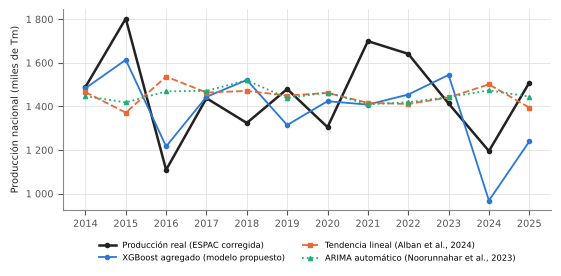

,R2,RMSE,MAE,MAPE (%),p Wilcoxon
Modelo,,,,,
XGBoost agregado (modelo propuesto),0.134,180008.318,157971.277,10.903,NaN
Random Forest agregado,0.059,187593.133,169004.111,11.959,0.791
Regresión lineal múltiple agregado,0.125,180888.141,160638.965,11.232,1.000
"Tendencia lineal (Alban et al., 2024)",-0.466,234195.087,183605.525,13.070,0.733
"ARIMA automático (Noorunnahar et al., 2023)",-0.251,216339.657,174953.945,12.407,0.569
Promedio histórico (referencia),-0.190,211000.163,166989.526,11.875,0.910


In [79]:
serie_nacional = agregado_nacional_corregido.set_index("anio")["produccion_real"]
METODOS_NACIONALES = {
    "Tendencia lineal (Alban et al., 2024)": METODOS_DEMANDA["Regresión lineal"],
    "ARIMA automático (Noorunnahar et al., 2023)": METODOS_DEMANDA["Auto-ARIMA"],
    "Promedio histórico (referencia)": METODOS_DEMANDA["Promedio histórico"],
}
predicciones_nacionales = {"XGBoost agregado (modelo propuesto)": agregado_nacional_corregido.set_index("anio")["produccion_predicha"]}
# Las alternativas de 5B.1 también se agregan al total nacional con sus predicciones LOYO
for nombre, (p_loyo, _) in MODELOS_ETAPA1.items():
    if not nombre.startswith("XGBoost"):
        predicciones_nacionales[nombre.split(" (")[0] + " agregado"] = p_loyo.groupby(anios_panel).sum()
for nombre, funcion in METODOS_NACIONALES.items():
    pred = {}
    for anio in serie_nacional.index:
        entrenar = serie_nacional.drop(anio)
        pred[anio] = funcion(entrenar.tolist(), entrenar.index.tolist(), anio)
    predicciones_nacionales[nombre] = pd.Series(pred)

filas = []
error_xgb_nacional = serie_nacional - predicciones_nacionales["XGBoost agregado (modelo propuesto)"]
for nombre, pred in predicciones_nacionales.items():
    fila = {"Modelo": nombre, **metricas_regresion(serie_nacional, pred.loc[serie_nacional.index])}
    if not nombre.startswith("XGBoost"):
        fila["p Wilcoxon"] = wilcoxon_errores(error_xgb_nacional, serie_nacional - pred)["p"]
    filas.append(fila)
comparacion_alternativas_nacional = pd.DataFrame(filas).set_index("Modelo")

# Error porcentual por año de cada modelo: permite ver el comportamiento en los años de choque
# (2016 y 2024, caídas de producción de 38% y 15% frente al año anterior).
errores_porcentuales_nacionales = pd.DataFrame({
    nombre: (pred.loc[serie_nacional.index] - serie_nacional) / serie_nacional * 100
    for nombre, pred in predicciones_nacionales.items()}).round(1)
errores_porcentuales_nacionales["Variación real vs año anterior (%)"] = (serie_nacional.pct_change() * 100).round(1)
print(errores_porcentuales_nacionales.to_string())

fig, ax = plt.subplots(figsize=(6.3, 2.6))
ax.plot(serie_nacional.index, serie_nacional, color=TINTA, lw=1.8, marker="o", ms=3, label="Producción real (ESPAC corregida)")
estilos = {"XGBoost agregado (modelo propuesto)": (AZUL, "-", "o"),
           "Tendencia lineal (Alban et al., 2024)": (NARANJA, "--", "s"),
           "ARIMA automático (Noorunnahar et al., 2023)": (AQUA, ":", "^")}
for nombre, (color, ls, mk) in estilos.items():
    ax.plot(serie_nacional.index, predicciones_nacionales[nombre].loc[serie_nacional.index], color=color, ls=ls,
            marker=mk, ms=3, lw=1.3, label=nombre)
ax.yaxis.set_major_formatter(miles); ax.set_ylabel("Producción nacional (miles de Tm)")
ax.set_xticks(serie_nacional.index); ax.grid(color=GRILLA, lw=.5)
ax.legend(fontsize=6, ncol=2, loc="upper center", bbox_to_anchor=(.5, -.12))
fig.savefig(f"{FIGURAS}/fig_alternativas_etapa1.png", dpi=300, bbox_inches="tight"); plt.show()
comparacion_alternativas_nacional.round(3)

## 5B.3 — Etapa 2: evaluación con origen móvil de la demanda

En cada año t desde 2018, cada método pronostica la demanda USDA-PSD usando solo los años anteriores
(2015 a t-1). Así se evalúa el promedio móvil de 3 años (PM3) que se adoptó como modelo final,
que no formaba parte de la comparación Leave-One-Out de la Etapa 2.

In [80]:
demanda_serie = comparables.set_index("Año")["Demanda_USDA_PSD"].sort_index()
METODOS_ORIGEN_MOVIL = {
    "Promedio móvil 3 años (modelo final)": lambda h: h.tail(3).mean(),
    "Promedio histórico": lambda h: h.mean(),
    "Random Walk": lambda h: h.iloc[-1],
    "Tendencia lineal": lambda h: LinearRegression().fit(np.array(h.index).reshape(-1, 1), h.values).predict([[h.index[-1] + 1]])[0],
}
anios_origen = [a for a in demanda_serie.index if a >= 2018]
pronosticos_origen = pd.DataFrame({nombre: [f(demanda_serie.loc[:a - 1]) for a in anios_origen]
                                   for nombre, f in METODOS_ORIGEN_MOVIL.items()}, index=anios_origen)
pronosticos_origen.index.name = "Año"
real_origen = demanda_serie.loc[anios_origen]
evaluacion_origen_movil = pd.DataFrame({nombre: metricas_regresion(real_origen, pronosticos_origen[nombre])
                                        for nombre in pronosticos_origen}).T
evaluacion_origen_movil["p Wilcoxon vs PM3"] = [np.nan] + [
    wilcoxon_errores(real_origen - pronosticos_origen.iloc[:, 0], real_origen - pronosticos_origen[n])["p"]
    for n in pronosticos_origen.columns[1:]]
evaluacion_origen_movil.round(3)

,R2,RMSE,MAE,MAPE (%),p Wilcoxon vs PM3
Promedio móvil 3 años (modelo final),-0.729,230941.611,172916.667,10.962,NaN
Promedio histórico,-0.171,190062.701,140897.569,8.723,0.297
Random Walk,-0.504,215355.810,180625.000,11.302,1.000
Tendencia lineal,-1.064,252299.930,200469.742,12.634,0.461


## 5B.4 — Etapa 3: inferencia estadística del modelo final de importaciones

El modelo final, ln(I) = β0 + β1·Producción + β2·Precio, se estima con `statsmodels` sobre los 11
años para obtener errores estándar, pruebas t, intervalos de confianza y las pruebas de los
supuestos de mínimos cuadrados: normalidad de los residuos (Shapiro-Wilk), homocedasticidad
(Breusch-Pagan) y ausencia de autocorrelación (Durbin-Watson). Para facilitar la lectura, la
producción entra en cientos de miles de toneladas y el precio en decenas de USD/Tm (los
coeficientes se multiplican por 10^5 y 10, respectivamente; el ajuste es idéntico).

In [81]:
X_inferencia = pd.DataFrame({
    "Producción (100 000 Tm)": panel_etapa3["Produccion_LOYO_TM"] / 1e5,
    "Precio (10 USD/Tm)": panel_etapa3["Precio_Internacional_USD_Tm"] / 10,
})
X_inferencia = sm.add_constant(X_inferencia).rename(columns={"const": "Intercepto"})
modelo_log_ols = sm.OLS(np.log(panel_etapa3["Importaciones_TM"]), X_inferencia).fit()
modelo_nivel_ols = sm.OLS(panel_etapa3["Importaciones_TM"], X_inferencia).fit()
print(modelo_log_ols.summary())

ic = modelo_log_ols.conf_int(alpha=0.05)
inferencia_etapa3 = pd.DataFrame({
    "Coeficiente": modelo_log_ols.params, "Error estándar": modelo_log_ols.bse,
    "t": modelo_log_ols.tvalues, "p": modelo_log_ols.pvalues,
    "IC 95% inferior": ic[0], "IC 95% superior": ic[1],
    "Efecto % sobre las importaciones": (np.exp(modelo_log_ols.params) - 1) * 100,
})
inferencia_etapa3.loc["Intercepto", "Efecto % sobre las importaciones"] = np.nan

residuos = modelo_log_ols.resid
bp = het_breuschpagan(residuos, X_inferencia)
diagnostico_etapa3 = pd.Series({
    "n": int(modelo_log_ols.nobs), "R2": modelo_log_ols.rsquared, "R2 ajustado": modelo_log_ols.rsquared_adj,
    "F": modelo_log_ols.fvalue, "p(F)": modelo_log_ols.f_pvalue,
    "Shapiro-Wilk W": stats.shapiro(residuos).statistic, "Shapiro-Wilk p": stats.shapiro(residuos).pvalue,
    "Breusch-Pagan LM": bp[0], "Breusch-Pagan p": bp[1], "Durbin-Watson": durbin_watson(residuos),
    "R2 modelo en nivel": modelo_nivel_ols.rsquared, "p(F) modelo en nivel": modelo_nivel_ols.f_pvalue,
})
# Elasticidades en la media muestral: e = beta * x_media (modelo semilogarítmico)
elasticidades_etapa3 = pd.Series({
    "Producción": modelo_log_ols.params["Producción (100 000 Tm)"] * X_inferencia["Producción (100 000 Tm)"].mean(),
    "Precio": modelo_log_ols.params["Precio (10 USD/Tm)"] * X_inferencia["Precio (10 USD/Tm)"].mean(),
})

# Comparación pareada de los errores Leave-One-Out del modelo final contra las alternativas
error_final = y_real_importaciones - prediccion_final
pruebas_etapa3 = pd.DataFrame({
    "Identidad contable (MAG)": wilcoxon_errores(error_final, y_real_importaciones - prediccion_identidad.values),
    "Promedio histórico": wilcoxon_errores(error_final, y_real_importaciones - prediccion_promedio),
    "Producción + Precio (nivel)": wilcoxon_errores(error_final, y_real_importaciones - predicciones_nivel),
}).T
print(diagnostico_etapa3.round(4).to_string())
print("\nElasticidades en la media:", elasticidades_etapa3.round(3).to_dict())
inferencia_etapa3.round(4)

                            OLS Regression Results                            
Dep. Variable:       Importaciones_TM   R-squared:                       0.499
Model:                            OLS   Adj. R-squared:                  0.374
Method:                 Least Squares   F-statistic:                     3.983
Date:                Mon, 12 Oct 2026   Prob (F-statistic):             0.0630
Time:                        07:31:33   Log-Likelihood:                -6.6083
No. Observations:                  11   AIC:                             19.22
Df Residuals:                       8   BIC:                             20.41
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercepto                

,Coeficiente,Error estándar,t,p,IC 95% inferior,IC 95% superior,Efecto % sobre las importaciones
Intercepto,11.4679,1.3169,8.7083,0.0000,8.4312,14.5047,NaN
Producción (100 000 Tm),-0.1351,0.0905,-1.4926,0.1739,-0.3438,0.0736,-12.6377
Precio (10 USD/Tm),0.0807,0.0311,2.5925,0.0320,0.0089,0.1525,8.4074


## 5B.5 — Intervalo de predicción y escenarios para 2026

El intervalo de predicción se calcula en la escala logarítmica y se transforma con la exponencial,
por lo que es asimétrico en toneladas. La matriz de escenarios combina tres niveles de producción
(el pronóstico ± el MAPE nacional de la Etapa 1, 10.9%) con tres niveles de precio (el supuesto de
2025 ± 15%, cerca de la variación interanual mediana del precio desde 2015).

In [82]:
x_2026 = pd.DataFrame({"Intercepto": [1.0], "Producción (100 000 Tm)": [produccion_2026_estimada / 1e5],
                       "Precio (10 USD/Tm)": [precio_2026_supuesto / 10]})
intervalos_2026 = {}
for nivel in (0.80, 0.95):
    marco = modelo_log_ols.get_prediction(x_2026).summary_frame(alpha=1 - nivel)
    intervalos_2026[f"{nivel:.0%}"] = (np.exp(marco["obs_ci_lower"].iloc[0]), np.exp(marco["obs_ci_upper"].iloc[0]))
importaciones_2026_puntual = np.exp(modelo_log_ols.predict(x_2026).iloc[0])

variacion_precio = panel_etapa3["Precio_Internacional_USD_Tm"].pct_change().abs().median()
factores_produccion = {"Producción -10.9%": 1 - mape_nacional_corregido / 100, "Producción pronosticada": 1.0,
                       "Producción +10.9%": 1 + mape_nacional_corregido / 100}
factores_precio = {"Precio -15%": 0.85, "Precio 2025": 1.0, "Precio +15%": 1.15}
escenarios_2026 = pd.DataFrame({
    nombre_precio: {nombre_prod: np.exp(modelo_log_ols.predict(pd.DataFrame({
        "Intercepto": [1.0], "Producción (100 000 Tm)": [produccion_2026_estimada * fp / 1e5],
        "Precio (10 USD/Tm)": [precio_2026_supuesto * fq / 10]})).iloc[0])
        for nombre_prod, fp in factores_produccion.items()}
    for nombre_precio, fq in factores_precio.items()})

print(f"Importaciones 2026 (punto): {importaciones_2026_puntual:,.0f} Tm")
for k, (lo, hi) in intervalos_2026.items():
    print(f"Intervalo de predicción {k}: {lo:,.0f} – {hi:,.0f} Tm")
print(f"Variación interanual mediana del precio 2015-2025: {variacion_precio:.1%}")
escenarios_2026.round(0)

Importaciones 2026 (punto): 65,404 Tm
Intervalo de predicción 80%: 30,316 – 141,106 Tm
Intervalo de predicción 95%: 18,378 – 232,761 Tm
Variación interanual mediana del precio 2015-2025: 6.5%


,Precio -15%,Precio 2025,Precio +15%
Producción -10.9%,63741.0,81504.0,104217.0
Producción pronosticada,51150.0,65404.0,83631.0
Producción +10.9%,41046.0,52485.0,67111.0


## 5B.6 — Traducción monetaria del error de planificación

El MAE de cada modelo se expresa en dólares de dos formas: (a) al precio internacional de 2025
(203.01 USD/Tm), que es el valor de la mercancía mal planificada en un año típico; y (b) a la prima
de escasez interna, la diferencia entre el precio local en escasez (USD 22 por quintal) y el
internacional (USD 15 por quintal) reportada por Ibarra et al. (2023), que aproxima el sobrecosto de
cada tonelada que falta y debe comprarse localmente en temporada de escasez. Un quintal = 45.36 kg.

In [83]:
QUINTAL_TM = 45.36 / 1000
prima_escasez = (22 - 15) / QUINTAL_TM
traduccion_monetaria = tabla_evolucion[["MAE (Tm)"]].copy()
traduccion_monetaria["Valor a precio internacional (USD)"] = traduccion_monetaria["MAE (Tm)"] * precio_2026_supuesto
traduccion_monetaria["Sobrecosto a prima de escasez (USD)"] = traduccion_monetaria["MAE (Tm)"] * prima_escasez
mae_identidad_tm = tabla_evolucion.loc["1. Identidad de balance", "MAE (Tm)"]
traduccion_monetaria["Reducción frente a la identidad (USD, precio internacional)"] = (
    (mae_identidad_tm - traduccion_monetaria["MAE (Tm)"]) * precio_2026_supuesto)
print(f"Prima de escasez: {prima_escasez:,.1f} USD/Tm")
traduccion_monetaria.round(0)

Prima de escasez: 154.3 USD/Tm


,MAE (Tm),Valor a precio internacional (USD),Sobrecosto a prima de escasez (USD),"Reducción frente a la identidad (USD, precio internacional)"
1. Identidad de balance,177397.0,36013284.0,27376019.0,0.0
2. Promedio histórico,53662.0,10893827.0,8281100.0,25119457.0
3. Regresión directa (+ Importaciones año anterior),38923.0,7901835.0,6006694.0,28111448.0
4. Mezcla ponderada (identidad + promedio),45690.0,9275622.0,7050998.0,26737661.0
5. Producción + Precio (nivel),39080.0,7933649.0,6030878.0,28079635.0
"6. Producción + Precio, log-target",38603.0,7836880.0,5957318.0,28176403.0


## 5B.7 — Figura de la Etapa 3: importaciones reales, pronósticos fuera de muestra e intervalo 2026

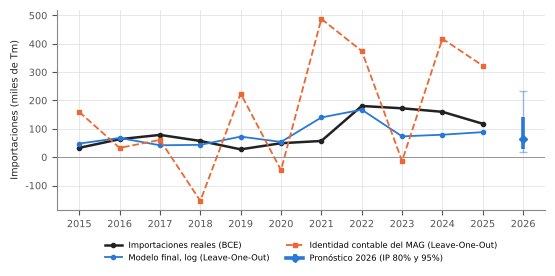

Tablas de la Parte 5B agregadas a la exportación.


In [84]:
anios_e3 = panel_etapa3.index
fig, ax = plt.subplots(figsize=(6.3, 2.6))
ax.plot(anios_e3, y_real_importaciones, color=TINTA, lw=1.8, marker="o", ms=3, label="Importaciones reales (BCE)")
ax.plot(anios_e3, prediccion_final, color=AZUL, lw=1.3, marker="o", ms=3, label="Modelo final, log (Leave-One-Out)")
ax.plot(anios_e3, prediccion_identidad.values, color=NARANJA, lw=1.3, ls="--", marker="s", ms=3,
        label="Identidad contable del MAG (Leave-One-Out)")
lo95, hi95 = intervalos_2026["95%"]; lo80, hi80 = intervalos_2026["80%"]
ax.errorbar([2026], [importaciones_2026_puntual], yerr=[[importaciones_2026_puntual - lo95], [hi95 - importaciones_2026_puntual]],
            color=AZUL, alpha=.45, lw=1, capsize=3)
ax.errorbar([2026], [importaciones_2026_puntual], yerr=[[importaciones_2026_puntual - lo80], [hi80 - importaciones_2026_puntual]],
            color=AZUL, lw=2.6, capsize=0, marker="D", ms=4, label="Pronóstico 2026 (IP 80% y 95%)")
ax.axhline(0, color="#888888", lw=.6)
ax.yaxis.set_major_formatter(miles); ax.set_ylabel("Importaciones (miles de Tm)")
ax.set_xticks(list(anios_e3) + [2026]); ax.grid(color=GRILLA, lw=.5)
ax.legend(fontsize=6, ncol=2, loc="upper center", bbox_to_anchor=(.5, -.12))
fig.savefig(f"{FIGURAS}/fig_importaciones_etapa3.png", dpi=300, bbox_inches="tight"); plt.show()

TABLAS_PARA_DESCARGAR["Resultados_Alternativas_Etapa1"] = comparacion_alternativas_etapa1.reset_index()
TABLAS_PARA_DESCARGAR["Resultados_Alternativas_Nacional"] = comparacion_alternativas_nacional.reset_index()
TABLAS_PARA_DESCARGAR["Resultados_Errores_Nacionales"] = errores_porcentuales_nacionales.reset_index().rename(columns={"index": "Año"})
TABLAS_PARA_DESCARGAR["Resultados_Demanda_Origen_Movil"] = evaluacion_origen_movil.reset_index().rename(columns={"index": "Método"})
TABLAS_PARA_DESCARGAR["Resultados_Inferencia_Etapa3"] = inferencia_etapa3.reset_index().rename(columns={"index": "Término"})
TABLAS_PARA_DESCARGAR["Resultados_Diagnostico_Etapa3"] = diagnostico_etapa3.rename("Valor").reset_index().rename(columns={"index": "Indicador"})
TABLAS_PARA_DESCARGAR["Resultados_Wilcoxon_Etapa3"] = pruebas_etapa3.reset_index().rename(columns={"index": "Alternativa"})
TABLAS_PARA_DESCARGAR["Resultados_Escenarios_2026"] = escenarios_2026.round(0).reset_index().rename(columns={"index": "Producción"})
TABLAS_PARA_DESCARGAR["Resultados_Traduccion_Monetaria"] = traduccion_monetaria.round(0).reset_index().rename(columns={"index": "Modelo"})
print("Tablas de la Parte 5B agregadas a la exportación.")

# Parte 6 — Exportación de tablas

Todas las tablas, gráficos y métricas se ven directamente en el notebook. Esta sección guarda las
tablas principales en Excel, dentro de la carpeta `resultados/`.

In [85]:
print(f"Hay {len(TABLAS_PARA_DESCARGAR)} tablas listas para descargar:\n")
for nombre, tabla in TABLAS_PARA_DESCARGAR.items():
    print(f"  - {nombre}  ({tabla.shape[0]} filas x {tabla.shape[1]} columnas)")


Hay 34 tablas listas para descargar:

  - Etapa1_ESPAC_Consolidado_Crudo  (270 filas x 6 columnas)
  - Etapa1_Clima_Mensual_Por_Provincia  (3473 filas x 7 columnas)
  - Etapa1_Panel_Modelado_Crudo  (270 filas x 9 columnas)
  - Etapa1_Validacion_ESPAC_vs_FAOSTAT  (12 filas x 4 columnas)
  - Etapa1_Diagnostico_ct_prod  (4 filas x 6 columnas)
  - Etapa1_Validacion_2016_2017_vs_INEC  (10 filas x 5 columnas)
  - Etapa1_Robustez_GroupKFold  (5 filas x 7 columnas)
  - Etapa1_Panel_Corregido  (270 filas x 11 columnas)
  - Etapa1_Comparacion_Hiperparametros  (20 filas x 8 columnas)
  - Etapa1_Metricas_Modelo  (6 filas x 3 columnas)
  - Etapa1_Verificacion_Nacional  (12 filas x 4 columnas)
  - Etapa1_Importancia_Variables  (6 filas x 2 columnas)
  - Etapa1_Pronostico_2026  (23 filas x 7 columnas)
  - Insumos_BCE_Maiz_Amarillo_Anual  (13 filas x 4 columnas)
  - Insumos_Precio_Internacional_Anual  (34 filas x 2 columnas)
  - Etapa2_Tres_Fuentes_Demanda  (12 filas x 4 columnas)
  - Etapa2_Comparaci

## Opción A — Todas las tablas en un solo archivo Excel (una pestaña por tabla)

In [86]:
os.makedirs(RUTA_RESULTADOS, exist_ok=True)
guardar_tablas_excel(TABLAS_PARA_DESCARGAR, f"{RUTA_RESULTADOS}/Tesis_Completa_Tablas.xlsx")

# En Colab, para descargarlo directo a la computadora:
# from google.colab import files
# files.download(f"{RUTA_RESULTADOS}/Tesis_Completa_Tablas.xlsx")

Guardado: resultados/Tesis_Completa_Tablas.xlsx  (34 pestañas)


## Opción B — Exportar una sola tabla

In [87]:
NOMBRE_DE_LA_TABLA = "Etapa3_Evolucion_Metodos"   # cambiar por el nombre de la tabla deseada

guardar_tablas_excel({NOMBRE_DE_LA_TABLA: TABLAS_PARA_DESCARGAR[NOMBRE_DE_LA_TABLA]},
                      f"{RUTA_RESULTADOS}/{NOMBRE_DE_LA_TABLA}.xlsx")

Guardado: resultados/Etapa3_Evolucion_Metodos.xlsx  (1 pestañas)


---

## Fin del notebook

Las tres etapas se calculan desde los archivos crudos de `datos/`, con el modelo entrenado y
corregido de principio a fin dentro de este mismo documento.